# Chapter 12 — Clustering

*Chapters 4 to 11 had the same ingredients: examples $\mathbf{x}_i$ with labels $y_i$, a loss that measures the disagreement between a prediction and a label, and a model class searched for a small loss. This chapter takes the labels away. With only the examples $\mathbf{x}_1,\dots,\mathbf{x}_n$, the question becomes whether they fall into groups, and what a good partition can mean when no label can say. The answer of **clustering** has a familiar form: choose the partition and the cluster centers that minimize the within-cluster sum of squares. For a fixed partition the best center of a cluster is, once more, its mean (Proposition 11.1 for the leaf of a tree is the same statement). We derive $k$-means and its guarantees, the criteria for choosing the number of clusters when there is no validation error to look at, the use of $k$-means as a compression method (vector quantization), Gaussian mixtures and hierarchical clustering as the first ways out of the spherical assumption, and spectral clustering, which replaces distances by a graph and eigenvectors by centers. The last section places clustering between supervised and unsupervised learning, with a handful of labels and many unlabeled examples.*

## 12.1 Learning objectives

Part II of the book was about prediction. Part III is about structure: what can be learned from $\mathbf{x}_1,\dots,\mathbf{x}_n$ alone. The first difficulty is that there is no longer a loss that says what a correct answer is, and the chapter keeps coming back to it: every clustering algorithm is the minimization of *some* criterion, and the criterion carries the assumptions.

After working through the chapter you will be able to:

1. formulate clustering as a **combinatorial optimization problem** over partitions, count the partitions (Stirling numbers), and prove that the pairwise-distance form of the within-cluster scatter equals the sum of squared distances to the cluster means, and that the total scatter splits into within and between parts;
2. derive **Lloyd's algorithm** for $k$-means from the two optimality conditions (nearest center, mean), prove that it decreases the objective and stops after finitely many steps at a point that is only a *local* minimum, and implement it from scratch;
3. explain why the result depends on the initialization, prove the key lemma behind **$k$-means++**, and measure the spread of the local minima on real data;
4. evaluate a clustering with an **internal** criterion (the silhouette) and with an **external** one (the adjusted Rand index, whose expected value under random labels is zero), and know what each can and cannot say;
5. choose the number of clusters by the elbow, the silhouette, the gap statistic and the **stability** of the partition under resampling, and see on real data that these criteria disagree;
6. read $k$-means as a **vector quantizer**, measure its rate–distortion curve on a photograph and on Digits, and relate the slope to an effective dimension;
7. derive the **EM algorithm** for Gaussian mixtures, prove that it never decreases the likelihood, show that $k$-means is its limit when the variance goes to zero, and choose the covariance structure and the number of components with the BIC;
8. derive **agglomerative clustering**, show that Ward's criterion is the increase of the $k$-means objective at each merge, and explain the chaining of single linkage;
9. define the **graph Laplacian**, prove that the multiplicity of the eigenvalue zero is the number of connected components, derive spectral clustering as the relaxation of the normalized cut, and run it on the nonconvex clusters where $k$-means fails and on Digits;
10. compare supervised, unsupervised and **semi-supervised** use of the same data: label propagation as the harmonic function of the graph, clusters as features, and the cases where unlabeled data help and where they do not.

We use four real data sets: **Iris** ($150$ flowers, $4$ features, $3$ species), **Wine** ($178$ wines, $13$ chemical measurements, $3$ cultivars; standardized), **Breast Cancer** ($569$ tumors, $30$ features; standardized) and **Digits** ($1797$ images of $8\times8$ pixels, $10$ digits; pixels divided by $16$). Two rules govern the whole chapter. First, **the labels are never given to a clustering algorithm and never used to choose a hyperparameter**; they are used afterwards, to score a partition, in the sections that say so (the species and the digits are what we *hope* the clusters recover, not what the algorithm was told). Second, clustering has no test set in the sense of the previous chapters: the whole data set is the training set, and we standardize it as a whole. In Section 12.9, where new points must be classified, we go back to the training/test split of Chapters 6 to 11 ($1347/450$ for Digits) and fit everything on the training part.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as hier
import scipy.sparse as sp
import scipy.sparse.csgraph as csg
from matplotlib.colors import ListedColormap
from matplotlib.patches import Ellipse
from scipy.optimize import linear_sum_assignment
from scipy.special import logsumexp, stirling2
from scipy.spatial.distance import pdist, squareform
from scipy.stats import multivariate_normal
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans, SpectralClustering
from sklearn.datasets import (load_breast_cancer, load_digits, load_iris, load_sample_image, load_wine,
                              make_circles, make_moons)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_samples, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, kneighbors_graph
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import LabelPropagation, LabelSpreading, SelfTrainingClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
CLUSTER_COLORS = [BLUE, ORANGE, GREEN, VERMILION, SKY, PURPLE, "#000000", "#999999", "#F0E442", "#8C564B"]
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

# The four data sets. The labels are kept apart and used only to score a partition afterwards.
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

wine = load_wine()
X_wine, y_wine = StandardScaler().fit_transform(wine.data), wine.target

bc = load_breast_cancer()
X_bc, y_bc = StandardScaler().fit_transform(bc.data), 1 - bc.target          # malignant = 1, as in Chapter 6

dig = load_digits()
X_dig, y_dig = dig.data / 16, dig.target                                       # pixels in [0, 1]

datasets = {"Iris": (X_iris, y_iris), "Wine": (X_wine, y_wine), "Breast Cancer": (X_bc, y_bc), "Digits": (X_dig, y_dig)}
print(pd.DataFrame({name: {"examples": X.shape[0], "features": X.shape[1], "classes": len(np.unique(y))}
                    for name, (X, y) in datasets.items()}).T.to_string())

               examples  features  classes
Iris                150         4        3
Wine                178        13        3
Breast Cancer       569        30        2
Digits             1797        64       10


## 12.2 Clustering as a combinatorial problem

### 12.2.1 What is asked, and why it is not well defined

In a supervised problem the target $y$ defines what a good answer is: it is the number the model will be scored against. In **clustering** the data are $\mathbf{x}_1,\dots,\mathbf{x}_n\in\mathbb{R}^p$ only, and the goal is a division into groups ("clusters") such that the examples of a group are similar to one another and different from those of the other groups. Two things are missing from this sentence: the meaning of "similar", and the number of groups. The Iris data show that both matter. The $150$ flowers belong to three species, but only one species (*setosa*) is clearly separated from the other two in the four measurements, so that a partition into $2$ groups is at least as natural as one into $3$; and a partition into $3$ groups that is natural for the measurements need not coincide with the species. A theorem of Kleinberg (2002) makes the difficulty precise: no clustering method can have at the same time three properties that look innocuous (invariance to the scale of the distances, the ability to produce any partition for a suitable choice of distances, and consistency, meaning that shrinking the distances inside the clusters and stretching those between them does not change the result). Every method is therefore a *choice* of what to give up, and the chapter is organized as a list of such choices.

### 12.2.2 Partitions and how many there are

:::{admonition} Definition 12.1 (clustering)
:class: tip
A **clustering** of $\{1,\dots,n\}$ into $k$ groups is a partition $\mathcal{C}=\{C_1,\dots,C_k\}$ of the indices into $k$ non-empty disjoint sets with union $\{1,\dots,n\}$; equivalently, a map $c:\{1,\dots,n\}\to\{1,\dots,k\}$ onto, with $C_j=\{i:c(i)=j\}$. We write $n_j=\lvert C_j\rvert$ and $\boldsymbol\mu_j=\frac1{n_j}\sum_{i\in C_j}\mathbf{x}_i$ for the **mean** (the *centroid*) of the cluster $j$. The labels $1,\dots,k$ carry no meaning: two maps that differ by a permutation of the labels are the same clustering.
:::

The number of such partitions is the **Stirling number of the second kind** $S(n,k)$, which satisfies $S(n,k)=k\,S(n-1,k)+S(n-1,k-1)$ (the point $n$ either joins one of the $k$ groups of a partition of the other $n-1$ points, or forms a group by itself) and grows like $k^n/k!$. Searching all partitions for the best one is out of the question, as the following code shows.

In [2]:
rows = []
for n, k in [(10, 3), (25, 3), (50, 3), (150, 3), (150, 5), (1797, 10)]:
    s = stirling2(n, k, exact=True)
    rows.append({"n": n, "k": k, "partitions S(n, k)": f"{float(s):.3e}" if len(str(s)) < 300 else f"10^{len(str(s)) - 1}",
                 "decimal digits": len(str(s))})
print(pd.DataFrame(rows).to_string(index=False))
s150 = float(stirling2(150, 3, exact=True))
print(f"\nIris, k = 3: at 10^9 partitions per second, listing them takes {s150 / 1e9 / 3.156e7:.1e} years; "
      f"the universe is about 1.4e10 years old")

   n  k partitions S(n, k)  decimal digits
  10  3          9.330e+03               4
  25  3          1.412e+11              12
  50  3          1.196e+23              24
 150  3          6.166e+70              71
 150  5         5.839e+102             103
1797 10            10^1790            1791

Iris, k = 3: at 10^9 partitions per second, listing them takes 2.0e+54 years; the universe is about 1.4e10 years old


### 12.2.3 A criterion: the within-cluster scatter

A criterion is needed to rank the partitions. The simplest asks that the *squared Euclidean distance* between two examples of the same cluster be small, summed over all the pairs of a cluster and over the clusters. To make clusters of different sizes comparable we divide by the size.

:::{admonition} Definition 12.2 (scatter)
:class: tip
For a clustering $\mathcal{C}$ of $\mathbf{x}_1,\dots,\mathbf{x}_n$, with $\bar{\mathbf{x}}$ the mean of all the examples, define
$$
\mathrm{SS}_W(\mathcal{C})=\sum_{j=1}^k\frac1{2n_j}\sum_{i,i'\in C_j}\lVert\mathbf{x}_i-\mathbf{x}_{i'}\rVert^2,\qquad
\mathrm{SS}_B(\mathcal{C})=\sum_{j=1}^kn_j\lVert\boldsymbol\mu_j-\bar{\mathbf{x}}\rVert^2,\qquad
\mathrm{SS}_T=\sum_{i=1}^n\lVert\mathbf{x}_i-\bar{\mathbf{x}}\rVert^2,
$$
the **within-cluster**, **between-cluster** and **total** scatter (sums of squares). The total scatter does not depend on the clustering.
:::

The first definition looks at pairs of examples, as the criteria of the combinatorial literature do; the next result turns it into a sum of squared distances to centers, which is the form we can optimize.

:::{admonition} Proposition 12.1 (pairwise form and centroid form)
:class: tip
For every cluster $C_j$ of a clustering,
$$
\frac1{2n_j}\sum_{i,i'\in C_j}\lVert\mathbf{x}_i-\mathbf{x}_{i'}\rVert^2=\sum_{i\in C_j}\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2,\qquad\text{hence}\qquad
\mathrm{SS}_W(\mathcal{C})=\sum_{j=1}^k\sum_{i\in C_j}\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2.\tag{12.1}
$$
:::

*Proof.* Write $\mathbf{x}_i-\mathbf{x}_{i'}=(\mathbf{x}_i-\boldsymbol\mu_j)-(\mathbf{x}_{i'}-\boldsymbol\mu_j)$ and expand the square: $\sum_{i,i'}\lVert\mathbf{x}_i-\mathbf{x}_{i'}\rVert^2=2n_j\sum_i\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2-2\big\langle\sum_i(\mathbf{x}_i-\boldsymbol\mu_j),\sum_{i'}(\mathbf{x}_{i'}-\boldsymbol\mu_j)\big\rangle$, and the last term vanishes because the deviations from the mean sum to zero. $\blacksquare$

The within-cluster scatter is therefore the sum of the squared distances of the examples to the mean of their cluster. The next result shows that it cannot be made smaller by a partition that ignores the position of the means, and that minimizing it is the same as maximizing the separation of the cluster means.

:::{admonition} Proposition 12.2 (decomposition of the scatter; merging two clusters)
:class: tip
(a) For every clustering, $\mathrm{SS}_T=\mathrm{SS}_W(\mathcal{C})+\mathrm{SS}_B(\mathcal{C})$; since $\mathrm{SS}_T$ is fixed, minimizing the within-cluster scatter is the same as maximizing the between-cluster scatter.

(b) If $A$ and $B$ are disjoint sets of examples with sizes $n_A,n_B$ and means $\boldsymbol\mu_A,\boldsymbol\mu_B$, then the scatter of $A\cup B$ around its own mean exceeds the sum of the scatters of $A$ and $B$ around theirs by
$$
\mathrm{SS}(A\cup B)-\mathrm{SS}(A)-\mathrm{SS}(B)=\frac{n_An_B}{n_A+n_B}\,\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2\;\ge\;0.\tag{12.2}
$$
Merging two clusters never decreases the within-cluster scatter, and splitting one never increases it.
:::

*Proof.* (a) For each cluster, $\sum_{i\in C_j}\lVert\mathbf{x}_i-\bar{\mathbf{x}}\rVert^2=\sum_{i\in C_j}\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2+n_j\lVert\boldsymbol\mu_j-\bar{\mathbf{x}}\rVert^2$ (add and subtract $\boldsymbol\mu_j$; the cross term has zero sum). Sum over $j$. (b) Apply (a) to the data set $A\cup B$ with the two clusters $A$ and $B$: the difference in (12.2) is the between-cluster scatter $n_A\lVert\boldsymbol\mu_A-\boldsymbol\mu\rVert^2+n_B\lVert\boldsymbol\mu_B-\boldsymbol\mu\rVert^2$, with $\boldsymbol\mu=(n_A\boldsymbol\mu_A+n_B\boldsymbol\mu_B)/(n_A+n_B)$. Since $\boldsymbol\mu_A-\boldsymbol\mu=\frac{n_B}{n_A+n_B}(\boldsymbol\mu_A-\boldsymbol\mu_B)$ and $\boldsymbol\mu_B-\boldsymbol\mu=-\frac{n_A}{n_A+n_B}(\boldsymbol\mu_A-\boldsymbol\mu_B)$, the sum is $\frac{n_An_B^2+n_Bn_A^2}{(n_A+n_B)^2}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2=\frac{n_An_B}{n_A+n_B}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2$. $\blacksquare$

Equation (12.2) is *exactly* Proposition 11.2, the gain of a split in a regression tree, with the targets replaced by vectors: a tree that splits a node and a clustering algorithm that splits or merges a cluster are measuring the same quantity, the squared distance between the two means weighted by $n_An_B/(n_A+n_B)$. The two problems differ in what they are allowed to do: the tree chooses the two groups with a threshold on one feature, because the targets have to be predicted from the features, whereas a clustering may put any examples together.

The following code checks Proposition 12.1 and Proposition 12.2 on Iris with a random partition into three groups, and with the partition given by the species, which we use here only to see how much of the scatter it explains.

In [3]:
def ss_within(X, labels):
    """Within-cluster scatter in the centroid form (12.1)."""
    return float(sum(((X[labels == j] - X[labels == j].mean(axis=0)) ** 2).sum() for j in np.unique(labels)))


def ss_within_pairs(X, labels):
    """The same quantity in the pairwise form of Definition 12.2."""
    total = 0.0
    for j in np.unique(labels):
        Z = X[labels == j]
        total += ((Z[:, None, :] - Z[None, :, :]) ** 2).sum() / (2 * len(Z))
    return float(total)


def ss_between(X, labels):
    xbar = X.mean(axis=0)
    return float(sum((labels == j).sum() * ((X[labels == j].mean(axis=0) - xbar) ** 2).sum() for j in np.unique(labels)))


ss_total = float(((X_iris - X_iris.mean(axis=0)) ** 2).sum())
rand_labels = np.random.default_rng(SEED).integers(0, 3, len(X_iris))
for name, lab in [("random partition", rand_labels), ("species", y_iris)]:
    w_c, w_p, b = ss_within(X_iris, lab), ss_within_pairs(X_iris, lab), ss_between(X_iris, lab)
    print(f"{name:17s} SS_W centroid form {w_c:9.4f}   pairwise form {w_p:9.4f}   |difference| {abs(w_c - w_p):.1e}"
          f"   SS_W + SS_B - SS_T = {w_c + b - ss_total:+.1e}")
print(f"SS_T = {ss_total:.2f};  species: SS_W / SS_T = {ss_within(X_iris, y_iris) / ss_total:.3f},"
      f"  random: {ss_within(X_iris, rand_labels) / ss_total:.3f}")

# Proposition 12.2(b): merging setosa (class 0) and versicolor (class 1)
A, B = X_iris[y_iris == 0], X_iris[y_iris == 1]
lhs = ss_within(np.vstack([A, B]), np.zeros(100, int)) - ss_within(A, np.zeros(50, int)) - ss_within(B, np.zeros(50, int))
rhs = len(A) * len(B) / (len(A) + len(B)) * ((A.mean(axis=0) - B.mean(axis=0)) ** 2).sum()
print(f"\nmerging setosa and versicolor: increase of the scatter {lhs:.4f}, formula (12.2) {rhs:.4f}")

random partition  SS_W centroid form  675.0583   pairwise form  675.0583   |difference| 0.0e+00   SS_W + SS_B - SS_T = +0.0e+00
species           SS_W centroid form   89.2974   pairwise form   89.2974   |difference| 1.4e-14   SS_W + SS_B - SS_T = -1.1e-13
SS_T = 681.37;  species: SS_W / SS_T = 0.131,  random: 0.991

merging setosa and versicolor: increase of the scatter 257.3267, formula (12.2) 257.3267


The two forms of the within-cluster scatter agree to rounding error ($1.4\times10^{-14}$ at most), and the decomposition of Proposition 12.2(a) holds to the same precision. The two partitions could hardly differ more. A random partition into three groups has $\mathrm{SS}_W/\mathrm{SS}_T=0.991$: it explains less than $1\%$ of the scatter, as it must, because each random group of about $50$ flowers has almost the same mean as the whole sample. The species have $\mathrm{SS}_W=89.30$, which is $13.1\%$ of $\mathrm{SS}_T=681.37$, so the three species account for $86.9\%$ of the scatter of the four measurements. Merging setosa and versicolor raises the scatter by $257.33$, the value that equation (12.2) predicts, to all the digits printed.

The species partition is not the partition that minimizes $\mathrm{SS}_W$: the best partition into three groups, found below, has $\mathrm{SS}_W=78.85$, lower than the $89.30$ of the species. A clustering algorithm optimizes a criterion, not the labels, and the two can disagree; we come back to this in Section 12.4.

### 12.2.4 A hard problem

Minimizing $\mathrm{SS}_W$ over the partitions into $k$ groups is the **$k$-means problem**. It is NP-hard when the dimension is not fixed, even for $k=2$ (Aloise, Deshpande, Hansen and Popat, 2009), and also in the plane when $k$ is not fixed (Mahajan, Nimbhorkar and Varadarajan, 2012), the analogue for partitions of the NP-completeness of the optimal tree quoted in Section 11.2.2. No algorithm is known that finds the best partition in time polynomial in $n$, $k$ and $p$ for all data sets, and the practical algorithms of the chapter are therefore **heuristics**: local search methods that reach a partition that cannot be improved by simple moves, with no promise that it is the best one. The same situation was met in Chapter 7 (nonconvex objectives) and Chapter 11 (greedy trees), and the remedy will be the same: understand what the algorithm guarantees, run it from several starting points, and look at how much the answer depends on them.

## 12.3 $k$-means

### 12.3.1 Two optimality conditions

Because of Proposition 12.1 we can minimize over the centers as well as over the partition. For centers $\boldsymbol\mu_1,\dots,\boldsymbol\mu_k\in\mathbb{R}^p$ and an assignment $c(i)\in\{1,\dots,k\}$ define the **$k$-means objective**
$$
J(c,\boldsymbol\mu_1,\dots,\boldsymbol\mu_k)=\sum_{i=1}^n\lVert\mathbf{x}_i-\boldsymbol\mu_{c(i)}\rVert^2.\tag{12.3}
$$

:::{admonition} Proposition 12.3 (the two optimality conditions)
:class: tip
(a) For fixed centers, $J$ is minimized over the assignments by sending each example to its **nearest center**, $c(i)\in\arg\min_j\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert$. The set of points closer to $\boldsymbol\mu_j$ than to every other center is a polyhedron (a **Voronoi cell**) bounded by hyperplanes that are the perpendicular bisectors of the segments between centers.

(b) For a fixed assignment, $J$ is minimized over the centers by the **means** of the clusters, $\boldsymbol\mu_j=\frac1{n_j}\sum_{i\in C_j}\mathbf{x}_i$ (any point for an empty cluster).

(c) Hence $\min_{c,\boldsymbol\mu}J=\min_{\mathcal{C}}\mathrm{SS}_W(\mathcal{C})$, the minimum over the partitions into at most $k$ groups, and every global minimizer satisfies (a) and (b) at the same time.
:::

*Proof.* (a) $J$ is a sum of $n$ terms, the $i$-th depending only on $c(i)$, so each term is minimized separately. The cell of $\boldsymbol\mu_j$ is defined by the inequalities $\lVert\mathbf{x}-\boldsymbol\mu_j\rVert^2\le\lVert\mathbf{x}-\boldsymbol\mu_l\rVert^2$, which are linear in $\mathbf{x}$: $2\langle\mathbf{x},\boldsymbol\mu_l-\boldsymbol\mu_j\rangle\le\lVert\boldsymbol\mu_l\rVert^2-\lVert\boldsymbol\mu_j\rVert^2$. (b) $J$ splits into one sum per cluster, and in cluster $j$ the function $\boldsymbol\mu\mapsto\sum_{i\in C_j}\lVert\mathbf{x}_i-\boldsymbol\mu\rVert^2$ is a convex quadratic with gradient $-2\sum_{i\in C_j}(\mathbf{x}_i-\boldsymbol\mu)$, which vanishes at the mean; this is the argument of Proposition 11.1. (c) By (b) and Proposition 12.1 the minimum over the centers of $J$ is $\mathrm{SS}_W$; a global minimizer of $J$ must be a minimizer in each of the two blocks of variables. $\blacksquare$

Two remarks. The statement (b) is Proposition 11.1 again: the value in the box of a regression tree and the center of a cluster are both means, because both problems minimize a sum of squares. And (a) says that a $k$-means partition is a partition into **convex** regions whose boundaries are hyperplanes, exactly as a tree's boxes are axis-aligned boxes: a tree is a partition chosen with the targets, in boxes, by greedy splitting; $k$-means is a partition chosen without targets, in Voronoi cells, by alternating the two conditions of the proposition. That alternation is the algorithm.

### 12.3.2 Lloyd's algorithm

**Lloyd's algorithm** (1957, published in 1982; also called the $k$-means algorithm) starts from $k$ centers and repeats two steps until the assignment no longer changes:

1. **assignment step**: send every example to its nearest center, keeping its current cluster unless another center is *strictly* nearer;
2. **update step**: replace each center by the mean of its cluster (an empty cluster keeps its center).

The assignment step costs $O(nkp)$ operations (the squared distances are $\lVert\mathbf{x}\rVert^2-2\langle\mathbf{x},\boldsymbol\mu\rangle+\lVert\boldsymbol\mu\rVert^2$, a matrix product), the update step $O(np)$.

:::{admonition} Theorem 12.4 (Lloyd's algorithm)
:class: tip
Let $J_t$ be the value of (12.3) after the update step of iteration $t$. Then $J_{t+1}\le J_t$, with strict inequality whenever the assignment changes, and the algorithm stops after a finite number of iterations at a pair (assignment, centers) that satisfies both conditions of Proposition 12.3. That pair is in general **not** a global minimizer of $J$.
:::

*Proof.* By Proposition 12.3(a) the assignment step does not increase $J$, and it decreases it strictly if some example moves to a strictly nearer center; by 12.3(b) the update step does not increase $J$. Hence $J$ never increases, and strictly decreases whenever the assignment changes. A partition cannot occur twice with a strict decrease in between, and there are finitely many partitions, so the assignment stops changing; at that moment the centers are the means of the clusters and every example is at least as near to its own center as to any other. That a fixed point need not be a global minimum is shown by examples as small as four points (Exercise 12.1), and by the experiments of the next subsection. $\blacksquare$

The theorem is a statement about *monotone decrease and termination*; it says nothing about the quality of the point reached, and nothing about the *number* of iterations, which can be large in the worst case (superpolynomial examples exist) but is a few tens in practice. The following code implements the algorithm and compares it with scikit-learn started from the same three centers (three Iris flowers chosen at random).

In [4]:
def lloyd(X, centers, max_iter=300):
    """Lloyd's algorithm. Returns centers, labels, the history of J and the history of the centers."""
    C = np.array(centers, dtype=float)
    labels, J_hist, C_hist = None, [], [C.copy()]
    for _ in range(max_iter):
        D = (X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None, :]       # squared distances, n x k
        new = D.argmin(axis=1)
        if labels is not None:                       # keep the current cluster unless another center is strictly nearer
            keep = D[np.arange(len(X)), labels] <= D[np.arange(len(X)), new] + 1e-12
            new = np.where(keep, labels, new)
        J_hist.append(float(((X - C[new]) ** 2).sum()))
        if labels is not None and (new == labels).all():
            break
        labels = new
        for j in range(len(C)):
            if (labels == j).any():
                C[j] = X[labels == j].mean(axis=0)
        C_hist.append(C.copy())
    return C, labels, J_hist, C_hist


init_idx = np.random.default_rng(SEED).choice(len(X_iris), 3, replace=False)
C0 = X_iris[init_idx]
C_fin, lab_fin, J_hist, _ = lloyd(X_iris, C0)
km = KMeans(n_clusters=3, init=C0, n_init=1, algorithm="lloyd", tol=0, max_iter=300).fit(X_iris)
print("J after each assignment step:", " ".join(f"{v:.2f}" for v in J_hist))
print(f"monotone: {bool(np.all(np.diff(J_hist) <= 1e-9))};  assignment steps (the last one finds that nothing changes): ours {len(J_hist)}, scikit-learn {km.n_iter_}")
print(f"final J: ours {J_hist[-1]:.6f}, scikit-learn {km.inertia_:.6f};  largest difference of the centers "
      f"{np.abs(np.sort(C_fin, axis=0) - np.sort(km.cluster_centers_, axis=0)).max():.1e}")

J after each assignment step: 181.27 88.83 84.95 84.01 83.05 81.75 80.81 79.87 79.34 78.92 78.86
monotone: True;  assignment steps (the last one finds that nothing changes): ours 11, scikit-learn 11
final J: ours 78.855666, scikit-learn 78.855666;  largest difference of the centers 1.8e-15


The two implementations follow the same path. Started from the same three flowers they stop at $J=78.855666$ with centers that agree to $1.8\times10^{-15}$, after the same number of assignment steps ($11$, the last one being the step that finds that nothing changes). The objective decreases at every step, as Theorem 12.4 says: it is $181.27$ after the first assignment, $88.83$ after the second, and the nine remaining steps lower it by ten units more, in irregular steps, the last of which is $0.06$. The value reached is not the lowest of the chapter: other starts reach $78.851$ (Section 12.3.4), a different fixed point $0.005$ lower. Theorem 12.4 guarantees a fixed point, not the best one.

Figure 12.1 shows the algorithm on two of the four features (the petal length and width, so that the picture is the whole problem), started from three flowers chosen at random. The color is the cluster, the marker shape is the species, which the algorithm never sees.

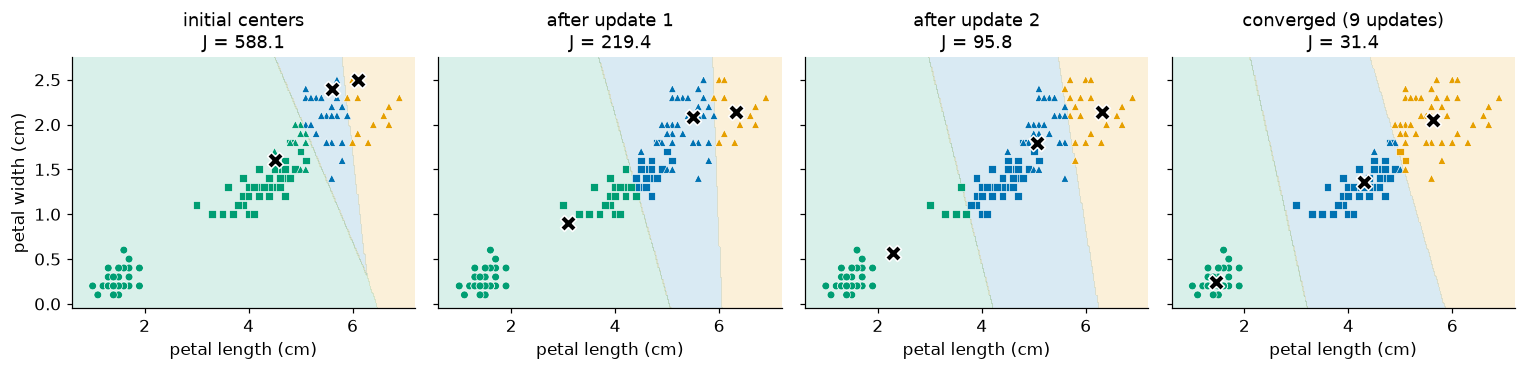

In [5]:
def figure_12_1():
    Xp = X_iris[:, 2:4]
    idx = np.random.default_rng(SEED + 3).choice(len(Xp), 3, replace=False)
    C, lab, J_h, C_h = lloyd(Xp, Xp[idx])
    steps = [0, 1, 2, len(C_h) - 1]
    gx, gy = np.meshgrid(np.linspace(0.6, 7.2, 300), np.linspace(-0.05, 2.75, 300))
    grid = np.c_[gx.ravel(), gy.ravel()]
    markers = ["o", "s", "^"]
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True, sharey=True)
    for ax, t in zip(axes, steps):
        Ct = C_h[t]
        cell = ((grid[:, None, :] - Ct[None]) ** 2).sum(-1).argmin(1).reshape(gx.shape)
        ax.contourf(gx, gy, cell, levels=[-0.5, 0.5, 1.5, 2.5], colors=CLUSTER_COLORS[:3], alpha=0.15)
        assign = ((Xp[:, None, :] - Ct[None]) ** 2).sum(-1).argmin(1)
        for s in range(3):
            m = y_iris == s
            ax.scatter(Xp[m, 0], Xp[m, 1], c=[CLUSTER_COLORS[a] for a in assign[m]], marker=markers[s], s=26, edgecolor="white", linewidth=0.4)
        ax.scatter(Ct[:, 0], Ct[:, 1], c="black", marker="X", s=110, edgecolor="white", zorder=5)
        j_t = float(((Xp - Ct[assign]) ** 2).sum())
        ax.set_title(("initial centers" if t == 0 else f"after update {t}" if t < len(C_h) - 1 else f"converged ({t} updates)") + f"\nJ = {j_t:.1f}")
        ax.set_xlabel("petal length (cm)")
        ax.grid(False)
    axes[0].set_ylabel("petal width (cm)")
    fig.tight_layout()
    plt.show()


figure_12_1()

The figure shows what the theorem does not say, namely how a bad start is repaired. The three initial centers are flowers of the two large species and none is near setosa, so in the first panel every setosa flower is assigned to the center in the middle of the picture, together with the small versicolor flowers. The update moves this center toward the mean of that mixed group, and then, one step after another, to the left, until it sits on setosa while the other two centers divide versicolor and virginica between them. The objective on the two features goes from $588.1$ to $219.4$, $95.8$ and $31.4$ at the end ($9$ updates). The squares and triangles of a different color from their neighbors, at the boundary between the two large species, are flowers that the partition places in the other cluster than their species; there is no line that separates the two species without errors in these two features.

### 12.3.3 A fixed point can still be improved

The conditions of Proposition 12.3 are conditions on *two blocks of variables*, and they are weaker than optimality with respect to every change of the partition. Moving one example $\mathbf{x}$ from the cluster $A$ (with $n_A$ points and mean $\boldsymbol\mu_A$) to the cluster $B$ (with $n_B$ points and mean $\boldsymbol\mu_B$) and recomputing the two means changes the objective by
$$
\Delta J=\frac{n_B}{n_B+1}\lVert\mathbf{x}-\boldsymbol\mu_B\rVert^2-\frac{n_A}{n_A-1}\lVert\mathbf{x}-\boldsymbol\mu_A\rVert^2,
$$
(the two terms are the increase of the scatter of $B$ when it gains $\mathbf{x}$ and the decrease of the scatter of $A$ when it loses it; both are instances of equation (12.2) in which one of the two sets is the single point $\mathbf{x}$). Lloyd's algorithm compares $\lVert\mathbf{x}-\boldsymbol\mu_B\rVert^2$ with $\lVert\mathbf{x}-\boldsymbol\mu_A\rVert^2$ without the two factors, which are larger and smaller than $1$ respectively, so it can stop at a partition in which a single move still decreases $J$. The algorithm of Hartigan and Wong (1979), which tests $\Delta J$, avoids this. How often does it happen? We run Lloyd's algorithm (scikit-learn's) on Digits with $k=10$ and test every example against every other cluster.

In [6]:
def best_single_moves(X, labels, centers):
    """For each example, the smallest change of J obtained by moving it to another cluster (negative = improvement)."""
    k = len(centers)
    n_j = np.bincount(labels, minlength=k).astype(float)
    D = ((X[:, None, :] - centers[None]) ** 2).sum(-1)
    own = D[np.arange(len(X)), labels]
    leave = n_j[labels] / np.maximum(n_j[labels] - 1, 1) * own            # decrease of J if x leaves its cluster
    join = n_j[None, :] / (n_j[None, :] + 1) * D                            # increase of J if x joins cluster j
    join[np.arange(len(X)), labels] = np.inf
    best = join.argmin(axis=1)
    return join[np.arange(len(X)), best] - leave, best


rows = []
for seed in range(3):
    km = KMeans(10, n_init=1, init="random", random_state=seed, tol=0).fit(X_dig)
    delta, target = best_single_moves(X_dig, km.labels_, km.cluster_centers_)
    i = int(delta.argmin())
    moved = km.labels_.copy(); moved[i] = target[i]
    J_before = ss_within(X_dig, km.labels_); J_after = ss_within(X_dig, moved)             # recomputed with the new means
    rows.append({"seed": seed, "J at the fixed point": J_before, "examples whose move helps": int((delta < -1e-9).sum()),
                 "best predicted change": delta[i], "change of J after the move": J_after - J_before})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

 seed  J at the fixed point  examples whose move helps  best predicted change  change of J after the move
    0             4592.4535                          6                -0.0454                     -0.0454
    1             4628.7339                          5                -0.0598                     -0.0598
    2             4824.6555                          4                -0.0585                     -0.0585


The single-move formula is exact: the change of $J$ predicted by $\Delta J$ and the change computed after moving the example and recomputing the two means are the same to four decimals ($-0.0454$, $-0.0598$, $-0.0585$). The three fixed points of Lloyd's algorithm contain $6$, $5$ and $4$ examples whose move lowers the objective, so the fixed points of Proposition 12.3 are not locally optimal for single moves. But the amount is small: the best single move improves $J$ by about $0.05$ out of $4600$, one part in $10^{5}$. In practice the difference between Lloyd and Hartigan–Wong is negligible next to the difference between *local minima*: these three runs end at $4592.5$, $4628.7$ and $4824.7$, that is $0.9\%$, $1.7\%$ and $6.0\%$ above the best value found for Digits with $k=10$ (see the next table). What matters for the result is where the algorithm starts.

### 12.3.4 Local minima and the initialization

Lloyd's algorithm is deterministic given the initial centers, so the quality of the result is decided by the initialization. The simplest choice, $k$ examples chosen uniformly at random, can put two centers in the same natural group and leave another group without one, a situation from which the two steps cannot escape. **$k$-means++** (Arthur and Vassilvitskii, 2007) spreads the initial centers by sampling:

1. choose the first center uniformly among the examples;
2. for each example let $D(\mathbf{x})^2$ be the squared distance to the nearest center chosen so far, and choose the next center among the examples with probability proportional to $D(\mathbf{x})^2$;
3. repeat step 2 until $k$ centers have been chosen, and then run Lloyd's algorithm.

An example far from all the chosen centers has a large $D^2$ and is likely to be chosen, so the new centers tend to fall in groups that do not yet have one. The analysis rests on the following lemma, which says how good a *single* uniformly chosen center is for the cluster that contains it.

:::{admonition} Lemma 12.5 (a random center costs twice the optimum)
:class: tip
Let $A$ be a set of $n_A$ points with mean $\boldsymbol\mu_A$ and let $\mathbf{c}$ be drawn uniformly from $A$. Then
$$
\mathbb{E}\Big[\sum_{\mathbf{x}\in A}\lVert\mathbf{x}-\mathbf{c}\rVert^2\Big]=2\sum_{\mathbf{x}\in A}\lVert\mathbf{x}-\boldsymbol\mu_A\rVert^2 .
$$
:::

*Proof.* For every point $\mathbf{c}$, $\sum_{\mathbf{x}\in A}\lVert\mathbf{x}-\mathbf{c}\rVert^2=\sum_{\mathbf{x}\in A}\lVert\mathbf{x}-\boldsymbol\mu_A\rVert^2+n_A\lVert\boldsymbol\mu_A-\mathbf{c}\rVert^2$ (add and subtract $\boldsymbol\mu_A$). Average over $\mathbf{c}\in A$: the second term becomes $n_A\cdot\frac1{n_A}\sum_{\mathbf{c}\in A}\lVert\mathbf{c}-\boldsymbol\mu_A\rVert^2$, equal to the optimal scatter again. $\blacksquare$

Applied to every optimal cluster in turn, with the $D^2$ sampling making it likely that a new center falls in a cluster not yet covered, the lemma is the core of the main result.

:::{admonition} Theorem 12.6 (Arthur and Vassilvitskii, 2007; stated without proof)
:class: tip
The expected value of $J$ for the centers chosen by $k$-means++ (before any Lloyd iteration) is at most $8(\ln k+2)$ times the optimal value of $J$.
:::

The guarantee is on the *seeding* alone, it grows only logarithmically with $k$, and Lloyd's iterations can only improve it by Theorem 12.4. No guarantee of this kind exists for the uniform seeding (Exercise 12.1 is an example in which the ratio is unbounded). The next code checks the lemma on the $50$ versicolor flowers (the average over all $50$ possible choices of $\mathbf{c}$ is exactly computable), implements $k$-means++ and measures how often the two seedings reach the best value found, on three data sets, in $200$ runs of a single start each.

In [7]:
Z = X_iris[y_iris == 1]
opt_one = ((Z - Z.mean(axis=0)) ** 2).sum()
mean_cost = np.mean([((Z - c) ** 2).sum() for c in Z])             # exact average over the 50 possible centers
print(f"Lemma 12.5 on 50 versicolor flowers: average cost of a uniform center {mean_cost:.4f}, twice the optimum {2 * opt_one:.4f}")


def kmeans_pp_seeds(X, k, rng):
    """k-means++ seeding, as in the three steps above."""
    centers = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        d2 = ((X[:, None, :] - np.array(centers)[None]) ** 2).sum(-1).min(axis=1)
        centers.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(centers)


# Our seeding followed by our Lloyd, 200 starts on Iris, against uniform seeding
rng = np.random.default_rng(SEED)
J_pp = [lloyd(X_iris, kmeans_pp_seeds(X_iris, 3, rng))[2][-1] for _ in range(200)]
J_rand = [lloyd(X_iris, X_iris[rng.choice(len(X_iris), 3, replace=False)])[2][-1] for _ in range(200)]
print(f"Iris, k = 3, 200 starts of our code: k-means++ seeding gives J in [{min(J_pp):.2f}, {max(J_pp):.2f}] and ends in the bad local minimum (J > 100) in {sum(v > 100 for v in J_pp)} runs; "
      f"uniform seeding gives J in [{min(J_rand):.2f}, {max(J_rand):.2f}] and {sum(v > 100 for v in J_rand)} bad runs")

# The three data sets with scikit-learn's implementations: 200 runs with a single start each
init_study = {}
for name, k in [("Iris", 3), ("Wine", 3), ("Digits", 10)]:
    X = datasets[name][0]
    init_study[name] = {init: np.array([KMeans(k, init=init, n_init=1, random_state=s).fit(X).inertia_ for s in range(200)])
                        for init in ["random", "k-means++"]}
rows = []
for name, d in init_study.items():
    best = min(v.min() for v in d.values())
    for init, v in d.items():
        hit = float((v <= best * (1 + 1e-3)).mean())
        rows.append({"data": name, "seeding": init, "best J": v.min(), "median J": np.median(v), "worst J": v.max(),
                     "runs within 0.1% of the best": hit, "P(hit in 10 starts)": 1 - (1 - hit) ** 10})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}" if v < 100 else f"{v:.1f}"))

Lemma 12.5 on 50 versicolor flowers: average cost of a uniform center 61.2328, twice the optimum 61.2328
Iris, k = 3, 200 starts of our code: k-means++ seeding gives J in [78.85, 145.53] and ends in the bad local minimum (J > 100) in 19 runs; uniform seeding gives J in [78.85, 145.76] and 49 bad runs


  data   seeding  best J  median J  worst J  runs within 0.1% of the best  P(hit in 10 starts)
  Iris    random  78.851    78.856    145.8                         0.785                1.000
  Iris k-means++  78.851    78.856   78.856                         1.000                1.000
  Wine    random  1277.9    1278.8   1617.4                         0.575                1.000
  Wine k-means++  1277.9    1278.8   1594.2                         0.520                0.999
Digits    random  4551.3    4578.9   4922.1                         0.210                0.905
Digits k-means++  4551.3    4570.4   4857.3                         0.370                0.990


The lemma holds exactly: the average cost of a uniform center on the $50$ versicolor flowers is $61.2328$, twice the optimal scatter of the group.

The results do not say that $k$-means++ is always better. On Iris, with our plain implementation of the three steps, $19$ of the $200$ runs end in one of the bad local minima ($J$ between $142.7$ and $145.8$, all of them with setosa split in two and versicolor and virginica merged) against $49$ for uniform seeding, which is a reduction of more than half but not a cure. The implementation of scikit-learn uses a *greedy* variant, which draws several candidate centers at each step and keeps the one that lowers $J$ most; with it, all $200$ runs reach the best value on Iris. On Wine the two seedings are indistinguishable ($57.5\%$ and $52.0\%$ of the runs within $0.1\%$ of the best value, a difference of ten runs out of two hundred, about one standard error); a few runs of both end about $25\%$ above the best, with one cluster badly placed. On Digits, where the landscape has many local minima, $k$-means++ is clearly better: $37\%$ of the runs against $21\%$ reach the best value, the median is $0.4\%$ above the best against $0.6\%$, and ten starts contain a run within $0.1\%$ of the best with probability $0.990$ against $0.905$ (computed from the table as $1-(1-p)^{10}$ under independence of starts).

Two practical rules follow. First, the number of starts matters as much as the seeding: a success probability of $0.2$ per start becomes $0.9$ with ten starts, which is why the algorithm is normally run several times and the partition with the smallest $J$ is kept (scikit-learn's default, `n_init='auto'`, runs $10$ starts with uniform seeding and a single one with $k$-means++; the Digits rows show what that single start can miss). Second, the value "best $J$ found" is a *proxy* for the optimum: none of the $400$ runs certifies that no better partition exists.

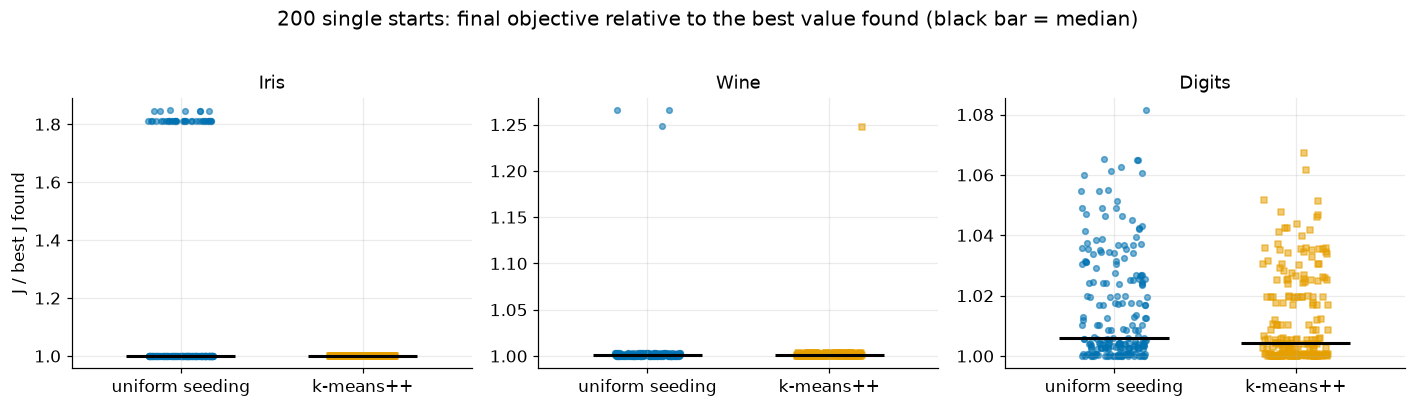

In [8]:
def figure_12_2():
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, (name, d) in zip(axes, init_study.items()):
        best = min(v.min() for v in d.values())
        for pos, (init, v) in enumerate(d.items()):
            jitter = np.random.default_rng(pos).uniform(-0.18, 0.18, len(v))
            ax.scatter(pos + jitter, v / best, s=14, alpha=0.55, color=[BLUE, ORANGE][pos], marker=["o", "s"][pos])
            ax.hlines(np.median(v) / best, pos - 0.3, pos + 0.3, color="black", linewidth=2)
        ax.set_xticks([0, 1], ["uniform seeding", "k-means++"])
        ax.set_xlim(-0.6, 1.6)
        ax.set_title(f"{name}")
        ax.set_ylabel("J / best J found" if name == "Iris" else "")
    fig.suptitle("200 single starts: final objective relative to the best value found (black bar = median)", y=1.02)
    fig.tight_layout()
    plt.show()


figure_12_2()

Figure 12.2 shows the same $200$ runs. On Iris the uniform seeding yields two groups of values, the best one and a group at $1.81$ to $1.85$ times the best (the partitions with setosa split in two), and nothing in between; the dispersion is a matter of *which* local minimum, not of how far from it. On Wine the bad starts are rare. On Digits there is no bad group but a continuum of local minima, up to $8\%$ above the best, and the two seedings differ in how the values are distributed, not in the range.

### 12.3.5 The scale of the features decides the clusters

$k$-means uses the Euclidean distance, so a feature with a large range dominates the distances, as in $k$-NN (Chapter 4) and in the SVM (Chapter 8). On Wine the effect is dramatic. The raw features have very different scales (the proline content is in the hundreds, the hue near $1$), and the partition of the raw data is almost entirely a partition by proline. We score the partitions with the **adjusted Rand index** (ARI) of Section 12.4, which is $1$ when the partition equals the cultivars and about $0$ for a partition unrelated to them.

In [9]:
rows = []
for name, X in [("raw features", wine.data), ("standardized", X_wine), ("min-max scaled", (wine.data - wine.data.min(0)) / np.ptp(wine.data, axis=0))]:
    labs = KMeans(3, n_init=10, random_state=SEED).fit_predict(X)
    rows.append({"features": name, "ARI with the cultivars": adjusted_rand_score(y_wine, labs),
                 "share of the variance of the largest-scale feature": X.var(axis=0).max() / X.var(axis=0).sum()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("raw features with the largest standard deviation:", ", ".join(f"{wine.feature_names[j]} ({wine.data[:, j].std():.1f})" for j in np.argsort(-wine.data.std(axis=0))[:3]))

      features  ARI with the cultivars  share of the variance of the largest-scale feature
  raw features                   0.371                                               0.998
  standardized                   0.897                                               0.077
min-max scaled                   0.854                                               0.125
raw features with the largest standard deviation: proline (314.0), magnesium (14.2), alcalinity_of_ash (3.3)


The scale is decisive. With the raw measurements one feature, the proline, carries $99.8\%$ of the total variance, so the Euclidean distance between two wines is practically the difference between their proline values, and the partition is a partition of that one axis: ARI $0.371$. Standardizing, which gives every feature the same variance ($1/13$ of the total, $7.7\%$), raises the ARI to $0.897$. Min-max scaling, which brings every feature to $[0,1]$, is intermediate ($0.854$) because the range of a feature is set by its extreme values, and an outlier can make a feature count less than the others. There is no scale-free answer: the choice of scale states how much each feature matters, and standardization, which says that a standard deviation counts the same in every feature, is the default used in the rest of the chapter for Wine and Breast Cancer.

Beyond the scale, $k$-means makes three assumptions that follow from (12.3): the clusters are **convex** (Voronoi cells), roughly **spherical** (the distance to the center is the only thing that matters, not its direction) and of similar **size and density** (a large cluster next to a small one is split in the wrong place, because the objective prefers to cut the large one). Gaussian mixtures (Section 12.7.1) relax the spherical assumption, spectral clustering (Section 12.8) the convexity.

## 12.4 Evaluating a clustering

The objective $J$ cannot be used to compare clusterings with different numbers of groups (Section 12.5), and it says nothing about whether a partition is *useful*. Two kinds of criteria exist. **Internal** criteria look only at the data and the partition; **external** criteria compare the partition with a grouping that is known independently, such as the species of Iris. Both are needed, and neither is a loss in the sense of the previous chapters: there is no unique correct answer to be right about.

### 12.4.1 Without labels: the silhouette

:::{admonition} Definition 12.3 (silhouette)
:class: tip
Let $d(\mathbf{x},\mathbf{x}')=\lVert\mathbf{x}-\mathbf{x}'\rVert$ and let example $i$ belong to the cluster $C_j$ with $n_j\ge2$. Let
$$
a(i)=\frac1{n_j-1}\sum_{i'\in C_j,\,i'\ne i}d(\mathbf{x}_i,\mathbf{x}_{i'}),\qquad
b(i)=\min_{l\ne j}\frac1{n_l}\sum_{i'\in C_l}d(\mathbf{x}_i,\mathbf{x}_{i'}),\qquad
s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}}\in[-1,1],
$$
the mean distance to the other members of its own cluster, the mean distance to the nearest other cluster, and the **silhouette** of the example ($s(i)=0$ if $n_j=1$). The **silhouette score** of a clustering is the mean of $s(i)$ over the examples.
:::

A silhouette near $1$ means that the example is much closer to its own cluster than to any other; near $0$, that it lies between two clusters; negative, that it is on average closer to another cluster than to its own. The score is computed in $O(n^2p)$ operations. It compares the cohesion of a cluster with its separation from the nearest neighbor cluster, which is why it can compare partitions with *different numbers of clusters*, which $J$ cannot do. The code computes it from the definition, compares it with scikit-learn and draws the **silhouette diagram** of Iris for $k=2$ and $k=3$: one bar per example, grouped by cluster and sorted inside the cluster.

Iris, k = 2: silhouette score 0.6810 (scikit-learn 0.6810, largest difference per example 2.2e-15); negative silhouettes: 0; mean per cluster: 0.633, 0.770
Iris, k = 3: silhouette score 0.5528 (scikit-learn 0.5528, largest difference per example 4.8e-15); negative silhouettes: 0; mean per cluster: 0.417, 0.798, 0.451


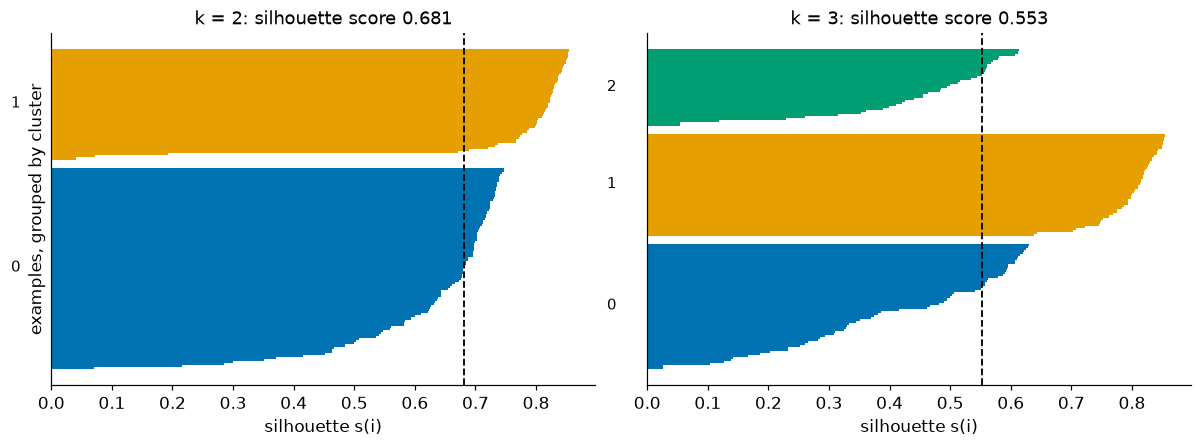

In [10]:
def silhouette_from_scratch(X, labels):
    D = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    ks = np.unique(labels)
    s = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]
        if own.sum() < 2:
            continue
        a = D[i, own].sum() / (own.sum() - 1)
        b = min(D[i, labels == l].mean() for l in ks if l != labels[i])
        s[i] = (b - a) / max(a, b)
    return s


iris_km = {k: KMeans(k, n_init=10, random_state=SEED).fit(X_iris) for k in (2, 3)}
for k, m in iris_km.items():
    s = silhouette_from_scratch(X_iris, m.labels_)
    print(f"Iris, k = {k}: silhouette score {s.mean():.4f} (scikit-learn {silhouette_score(X_iris, m.labels_):.4f}, "
          f"largest difference per example {np.abs(s - silhouette_samples(X_iris, m.labels_)).max():.1e}); "
          f"negative silhouettes: {int((s < 0).sum())}; mean per cluster: "
          + ", ".join(f"{s[m.labels_ == j].mean():.3f}" for j in range(k)))


def figure_12_3():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
    for ax, (k, m) in zip(axes, iris_km.items()):
        s = silhouette_samples(X_iris, m.labels_)
        pos = 0
        for j in range(k):
            sj = np.sort(s[m.labels_ == j])
            ax.barh(np.arange(pos, pos + len(sj)), sj, height=1.0, color=CLUSTER_COLORS[j], edgecolor="none")
            ax.text(-0.05, pos + len(sj) / 2, f"{j}", ha="right", va="center", fontsize=10)
            pos += len(sj) + 4
        ax.axvline(s.mean(), color="black", linestyle="--", linewidth=1.2)
        ax.set_title(f"k = {k}: silhouette score {s.mean():.3f}")
        ax.set_xlabel("silhouette s(i)")
        ax.set_yticks([])
        ax.grid(False)
    axes[0].set_ylabel("examples, grouped by cluster")
    fig.tight_layout()
    plt.show()


figure_12_3()

The code agrees with scikit-learn to rounding error (differences of order $10^{-15}$ per example). The score is $0.681$ for $k=2$ and $0.553$ for $k=3$, and neither partition has an example with a negative silhouette. The diagrams show where the score comes from. With $k=2$ the cluster that contains setosa (on average $0.770$) is compact and far from the other, and the other one, which contains the $100$ flowers of the two large species, averages $0.633$. With $k=3$ setosa keeps its high values ($0.798$) but the two clusters into which the large species are divided, $0.417$ and $0.451$, have many flowers with a silhouette near $0$: their flowers are about as close to the neighbor cluster as to their own, which is the overlap of versicolor and virginica seen in Figure 12.1. The silhouette therefore prefers *two* clusters for Iris. That is not an error of the index: at the scale of the whole sample the data really do consist of two groups, a well separated one and a diffuse one; the third group exists at a finer scale and with a much weaker separation. The species were defined by botanists with other information.

### 12.4.2 With labels: the adjusted Rand index

Suppose that a reference partition $\mathcal{U}$ of the examples is available (the species, the digits). The agreement between a clustering $\mathcal{V}=\{V_1,\dots,V_k\}$ and $\mathcal{U}=\{U_1,\dots,U_r\}$ cannot be measured by the accuracy, because the cluster labels have no meaning (cluster $0$ may be the species $2$), and the numbers of groups may differ. The remedy is to count *pairs* of examples, which do not depend on the names.

:::{admonition} Definition 12.4 (Rand index and adjusted Rand index)
:class: tip
Let $n_{ij}=\lvert U_i\cap V_j\rvert$ be the **contingency table**, with row sums $a_i=\lvert U_i\rvert$ and column sums $b_j=\lvert V_j\rvert$. A pair of examples is *together* in a partition if they belong to the same group. The number of pairs together in both partitions is $\sum_{ij}\binom{n_{ij}}2$, and the **Rand index** is the fraction of pairs on which the two partitions agree (together in both or apart in both),
$$
R=\binom n2^{-1}\Big[\binom n2+2\sum_{ij}\binom{n_{ij}}2-\sum_i\binom{a_i}2-\sum_j\binom{b_j}2\Big].
$$
The **adjusted Rand index** (Hubert and Arabie, 1985) is
$$
\mathrm{ARI}=\frac{\sum_{ij}\binom{n_{ij}}2-\Big[\sum_i\binom{a_i}2\sum_j\binom{b_j}2\Big]\Big/\binom n2}{\frac12\Big[\sum_i\binom{a_i}2+\sum_j\binom{b_j}2\Big]-\Big[\sum_i\binom{a_i}2\sum_j\binom{b_j}2\Big]\Big/\binom n2}.
$$
:::

:::{admonition} Proposition 12.7 (properties of the ARI)
:class: tip
(a) The ARI does not change when the groups of either partition are renamed. (b) $\mathrm{ARI}\le1$, with equality if and only if the two partitions are equal. (c) If the two partitions are fixed and the elements of one of them are permuted uniformly at random (the *permutation model*, in which the group sizes $a_i$ and $b_j$ are fixed), then $\mathbb{E}\big[\sum_{ij}\binom{n_{ij}}2\big]=\sum_i\binom{a_i}2\sum_j\binom{b_j}2/\binom n2$, so that the numerator of the ARI has expectation $0$. The ARI of a partition unrelated to the reference is thus close to $0$ (and can be slightly negative), whatever the numbers of groups.
:::

*Proof.* (a) The formula uses only the numbers $n_{ij}$, $a_i$, $b_j$, which are permuted by a renaming. (c) $\sum_{ij}\binom{n_{ij}}2$ counts the pairs together in both partitions. Take one of the $\sum_i\binom{a_i}2$ pairs together in $\mathcal{U}$; under a random permutation of the examples of $\mathcal{V}$ the two examples occupy two positions chosen uniformly among all $\binom n2$ pairs of positions, and the probability that the pair is together in $\mathcal{V}$ is $\sum_j\binom{b_j}2/\binom n2$; sum over the pairs. (b) Since $n_{ij}\le a_i$ and $n_{ij}\le b_j$, every pair counted in $\sum_{ij}\binom{n_{ij}}2$ is counted in $\sum_i\binom{a_i}2$ and in $\sum_j\binom{b_j}2$, so $\sum_{ij}\binom{n_{ij}}2\le\min\{\sum_i\binom{a_i}2,\sum_j\binom{b_j}2\}\le\frac12[\cdots+\cdots]$, which makes the numerator at most the denominator. Equality forces the two sums to be equal to $\sum_{ij}\binom{n_{ij}}2$: every pair together in one partition is together in the other, which means that the partitions are equal. $\blacksquare$

The adjustment is the point of the definition. The Rand index of two unrelated partitions is far from $0$ (most pairs are apart in both), and the **normalized mutual information** $\mathrm{NMI}=I(\mathcal{U};\mathcal{V})\big/\tfrac12[H(\mathcal{U})+H(\mathcal{V})]$, with $I$ the mutual information and $H$ the entropy of the group-membership distributions, also grows when the number of groups grows, even for random labels. The code computes the ARI from the contingency table, and the values obtained by random labels.

In [11]:
def ari_from_scratch(u, v):
    table = pd.crosstab(np.asarray(u), np.asarray(v)).to_numpy()
    c2 = lambda m: m * (m - 1) / 2
    sum_ij, sum_a, sum_b = c2(table).sum(), c2(table.sum(1)).sum(), c2(table.sum(0)).sum()
    expected = sum_a * sum_b / c2(table.sum())
    return float((sum_ij - expected) / (0.5 * (sum_a + sum_b) - expected))


m3 = iris_km[3]
print("contingency table of the species (rows) and the k = 3 clusters (columns):")
print(pd.crosstab(pd.Series(iris.target_names[y_iris], name="species"), pd.Series(m3.labels_, name="cluster")).to_string())
print(f"\nARI: from scratch {ari_from_scratch(y_iris, m3.labels_):.6f}, scikit-learn {adjusted_rand_score(y_iris, m3.labels_):.6f};"
      f"  after renaming the clusters {ari_from_scratch(y_iris, (m3.labels_ + 1) % 3):.6f};  NMI {normalized_mutual_info_score(y_iris, m3.labels_):.4f}")

rng = np.random.default_rng(SEED)
rows = []
for kk in [3, 10, 50, 200]:
    rand_part = [rng.integers(0, kk, len(y_dig)) for _ in range(20)]
    pairs = [(adjusted_rand_score(y_dig, r), normalized_mutual_info_score(y_dig, r)) for r in rand_part]
    rows.append({"random labels with k groups": kk, "mean ARI": np.mean([a for a, _ in pairs]), "mean NMI": np.mean([b for _, b in pairs])})
print("\nDigits against random partitions (20 draws each):")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

contingency table of the species (rows) and the k = 3 clusters (columns):
cluster      0   1   2
species               
setosa       0  50   0
versicolor  48   0   2
virginica   14   0  36

ARI: from scratch 0.730238, scikit-learn 0.730238;  after renaming the clusters 0.730238;  NMI 0.7582

Digits against random partitions (20 draws each):
 random labels with k groups  mean ARI  mean NMI
                           3   -0.0000    0.0029
                          10    0.0000    0.0100
                          50    0.0001    0.0442
                         200   -0.0001    0.1505


The contingency table reads as the picture of Figure 12.1: setosa is entirely in one cluster, and the other two clusters share versicolor and virginica: cluster $0$ holds $48$ versicolor and $14$ virginica flowers, cluster $2$ holds $36$ virginica and $2$ versicolor. The ARI is $0.7302$; our code and scikit-learn give the same value to six decimals, and renaming the clusters does not change it. The NMI of the same partition is $0.7582$, a different number on a different scale: the two scores cannot be compared with each other.

The last table is the reason for the adjustment. Random labels, unrelated to the digits, have ARI equal to $0$ to the fourth decimal for every number of groups from $3$ to $200$, as Proposition 12.7(c) says. The NMI of the same random labels grows with the number of groups, from $0.003$ with $3$ groups to $0.151$ with $200$, which is a score of $0.15$ for pure noise: a clustering with many small groups can raise its NMI without containing any information. For this reason the ARI is the main external score of the chapter, and the NMI is reported only as a second opinion, in comparisons between partitions with the same number of clusters.

An external score measures agreement with *one* grouping of the data. A low ARI does not prove a bad clustering (the groups of the data may be real and different from the labels: the two groups of Section 12.5 on Iris are an example), and a high ARI does not prove that the partition is the only reasonable one. We use the ARI throughout because it is what the reader can check, and we say each time that the labels played no role in the choice of the method or the parameters.

## 12.5 Choosing the number of clusters

### 12.5.1 The objective cannot do it

In a supervised problem the number of parameters (the depth of a tree, the penalty of a ridge) is chosen by looking at an error on data that were not used for fitting (Chapter 5). For clustering the natural analogue fails, for the same reason that the training error of Chapter 3 always favors the richest model.

:::{admonition} Proposition 12.8 ($J$ decreases with $k$)
:class: tip
Let $J^\ast(k)=\min_{\mathcal{C}}\mathrm{SS}_W(\mathcal{C})$ be the minimum of the within-cluster scatter over the partitions into $k$ groups. Then $J^\ast(1)=\mathrm{SS}_T$, $J^\ast(k+1)\le J^\ast(k)$ for $k<n$, and $J^\ast(n)=0$.
:::

*Proof.* Take an optimal partition into $k<n$ groups. One of its groups has at least two examples; moving one of them to a group of its own does not increase the scatter by (12.2) (splitting never increases it), and produces a partition into $k+1$ groups. The last statements are clear. $\blacksquare$

The same holds for the objective *evaluated on held-out examples* when the centers are those fitted on the training examples: the held-out distortion decreases with $k$ for a long time, as we show below, because more centers are always nearer to a new point. So no validation set can pick $k$ by the minimum of $J$; four other families of criteria are in use.

1. **The elbow.** Plot $J^\ast(k)$ against $k$ and look for a bend after which the decrease is small. The idea is that the decrease is large while a new center explains a real group and small when it only splits a group in two (Proposition 12.2(b) says by how much, $\frac{n_An_B}{n_A+n_B}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2$). There is no rule, and the bend is often not there.
2. **The silhouette.** Choose the $k$ that maximizes the mean silhouette (Section 12.4.1).
3. **The gap statistic** (Tibshirani, Walther and Hastie, 2001). Compare $\log J^\ast(k)$ with its expectation for data with *no cluster structure*, drawn uniformly in the bounding box of the data: $\mathrm{Gap}(k)=\frac1B\sum_{b=1}^B\log J^\ast_b(k)-\log J^\ast(k)$, with $J^\ast_b$ computed on $B$ reference data sets. Choose the smallest $k$ such that $\mathrm{Gap}(k)\ge\mathrm{Gap}(k+1)-s_{k+1}$, where $s_{k}$ is the standard deviation of $\log J^\ast_b(k)$ times $\sqrt{1+1/B}$.
4. **Stability** (Ben-Hur, Elisseeff and Guyon, 2002; Lange, Roth, Braun and Buhmann, 2004). If the data really have $k$ groups, two clusterings computed from two independent samples should agree; if $k$ is too large, the algorithm has to cut a group in two *somewhere* and cuts it in a different place each time. We draw two disjoint halves of the data, cluster each with $k$-means, assign **all** the examples to the nearest center of each of the two solutions, and measure the ARI between the two assignments; the average over repeated random halves is the **stability** of $k$. This is the instability of trees of Section 11.5.5, used as a criterion: a partition that changes a lot when a few examples change is not determined by the data.

The code computes the four quantities for $k=1,\dots,8$ on Iris and Wine and $k=1,\dots,15$ on Digits. The numbers of classes ($3$, $3$, $10$) are used *only* to mark the plot.

In [12]:
def gap_statistic(X, ks, B=20, seed=SEED):
    rng = np.random.default_rng(seed)
    lo, hi = X.min(axis=0), X.max(axis=0)
    log_j = np.array([np.log(KMeans(k, n_init=10, random_state=SEED).fit(X).inertia_) for k in ks])
    ref = np.array([[np.log(KMeans(k, n_init=3, random_state=SEED).fit(rng.uniform(lo, hi, X.shape)).inertia_) for k in ks] for _ in range(B)])
    gap, s = ref.mean(axis=0) - log_j, ref.std(axis=0) * np.sqrt(1 + 1 / B)
    chosen = next((ks[i] for i in range(len(ks) - 1) if gap[i] >= gap[i + 1] - s[i + 1]), None)
    return gap, s, chosen


def stability(X, k, reps=15, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        perm = rng.permutation(len(X))
        half = len(X) // 2
        m1 = KMeans(k, n_init=3, random_state=int(rng.integers(10 ** 9))).fit(X[perm[:half]])
        m2 = KMeans(k, n_init=3, random_state=int(rng.integers(10 ** 9))).fit(X[perm[half:2 * half]])
        out.append(adjusted_rand_score(m1.predict(X), m2.predict(X)))
    return np.array(out)


k_study = {}
t0 = time.perf_counter()
for name, kmax in [("Iris", 8), ("Wine", 8), ("Digits", 15)]:
    X, y = datasets[name]
    ks = list(range(1, kmax + 1))
    models = {k: KMeans(k, n_init=10, random_state=SEED).fit(X) for k in ks}
    gap, s_gap, k_gap = gap_statistic(X, ks)
    stab = {k: stability(X, k) for k in ks if k >= 2}
    k_study[name] = {"ks": ks, "J": np.array([models[k].inertia_ for k in ks]),
                     "sil": np.array([np.nan] + [silhouette_score(X, models[k].labels_) for k in ks[1:]]),
                     "gap": gap, "gap_s": s_gap, "k_gap": k_gap,
                     "stab": np.array([np.nan] + [stab[k].mean() for k in ks[1:]]), "stab_sd": np.array([np.nan] + [stab[k].std(ddof=1) for k in ks[1:]]),
                     "ari": np.array([adjusted_rand_score(y, models[k].labels_) for k in ks])}
rows = []
for name, r in k_study.items():
    ks = r["ks"]
    rows.append({"data": name, "classes": len(np.unique(datasets[name][1])), "best silhouette": ks[int(np.nanargmax(r["sil"]))],
                 "best stability": ks[int(np.nanargmax(r["stab"]))], "gap rule": r["k_gap"] if r["k_gap"] is not None else "none",
                 "k with the best ARI": ks[int(np.argmax(r["ari"]))]})
print(pd.DataFrame(rows).to_string(index=False))
print(f"[{time.perf_counter() - t0:.1f} s]")

  data  classes  best silhouette  best stability gap rule  k with the best ARI
  Iris        3                2               2     none                    3
  Wine        3                3               3        4                    3
Digits       10                9               9     none                   11
[21.5 s]


In [13]:
for name, r in k_study.items():
    print(f"\n{name}")
    print(pd.DataFrame({"k": r["ks"], "J": r["J"], "J / SS_T": r["J"] / r["J"][0], "silhouette": r["sil"], "gap": r["gap"], "gap s": r["gap_s"],
                        "stability": r["stab"], "(sd)": r["stab_sd"], "ARI with labels": r["ari"]}).to_string(index=False, float_format=lambda v: f"{v:.3f}" if abs(v) < 100 else f"{v:.1f}"))


Iris
 k      J  J / SS_T  silhouette   gap  gap s  stability  (sd)  ARI with labels
 1  681.4     1.000         NaN 0.078  0.045        NaN   NaN            0.000
 2  152.3     0.224       0.681 0.989  0.035      0.977 0.032            0.540
 3 78.851     0.116       0.553 1.450  0.036      0.841 0.159            0.730
 4 57.228     0.084       0.498 1.579  0.038      0.764 0.105            0.650
 5 46.461     0.068       0.491 1.648  0.039      0.731 0.192            0.612
 6 39.040     0.057       0.365 1.713  0.036      0.673 0.119            0.448
 7 34.306     0.050       0.354 1.769  0.041      0.667 0.079            0.481
 8 30.132     0.044       0.349 1.818  0.042      0.685 0.072            0.445

Wine
 k      J  J / SS_T  silhouette   gap  gap s  stability  (sd)  ARI with labels
 1 2314.0     1.000         NaN 0.802  0.017        NaN   NaN            0.000
 2 1658.8     0.717       0.259 1.015  0.017      0.518 0.251            0.374
 3 1277.9     0.552       0.285 1.191  0

The four criteria, applied to the same partitions, do not give one answer.

**Iris.** The silhouette ($0.681$ at $k=2$ against $0.553$ at $k=3$) and the stability ($0.977$ against $0.841$) choose $k=2$. The elbow is ambiguous: $78\%$ of the total scatter disappears with the second center and a further $11\%$ with the third, and then about $3\%$ or less with each. The gap statistic gives no answer: the rule finds no $k\le8$ at which the curve stops growing, and the gap grows steadily from $0.08$ to $1.82$. The reason is the choice of the reference distribution: Iris has strongly correlated features, so it looks clustered compared with data uniform in the bounding box at every $k$ (Tibshirani et al. proposed to draw the reference in a box aligned with the principal components for this reason). The ARI with the species, which was not used by any criterion, is highest at $k=3$ ($0.730$), and $0.540$ at $k=2$. The criteria are not wrong and the species are not wrong: they answer two different questions, "how many groups does the geometry show?" and "how many species did the botanists distinguish?".

**Wine.** Here the criteria agree: the silhouette ($0.285$) and the stability ($0.883$, standard deviation $0.064$) are largest at $k=3$, the elbow has its bend there ($J/\mathrm{SS}_T$ falls from $0.717$ to $0.552$ and then more slowly), and the ARI with the cultivars is largest at $3$ ($0.897$). The gap rule chooses $4$, not $3$, because the gap at $k=3$ ($1.191$) is smaller than the gap at $k=4$ ($1.231$) minus its standard error ($0.015$). The agreement is moderate: a silhouette of $0.285$ is in the range that Kaufman and Rousseeuw (1990) describe as weak structure, and the margin over $k=2$ and $k=4$ is $0.025$.

**Digits.** The criteria are even less decisive. $J$ decreases smoothly and has no elbow. The silhouette rises to a maximum at $k=9$ ($0.189$) and stays within $0.007$ of it up to $k=15$, a plateau rather than a peak. The stability is largest at $9$ ($0.826$), but the value for $10$ ($0.805$) is within one standard deviation ($0.108$). The gap rule gives no answer, for the reason given for Iris. And the ARI with the digit labels is highest at $k=11$ and $13$ ($0.726$), against $0.667$ at $k=10$. No criterion finds the ten classes, and one must ask whether it should: $k$-means partitions the pixel space by Euclidean distance, and the ten digits are not necessarily ten compact groups in that space, since handwriting varies a great deal inside one digit.

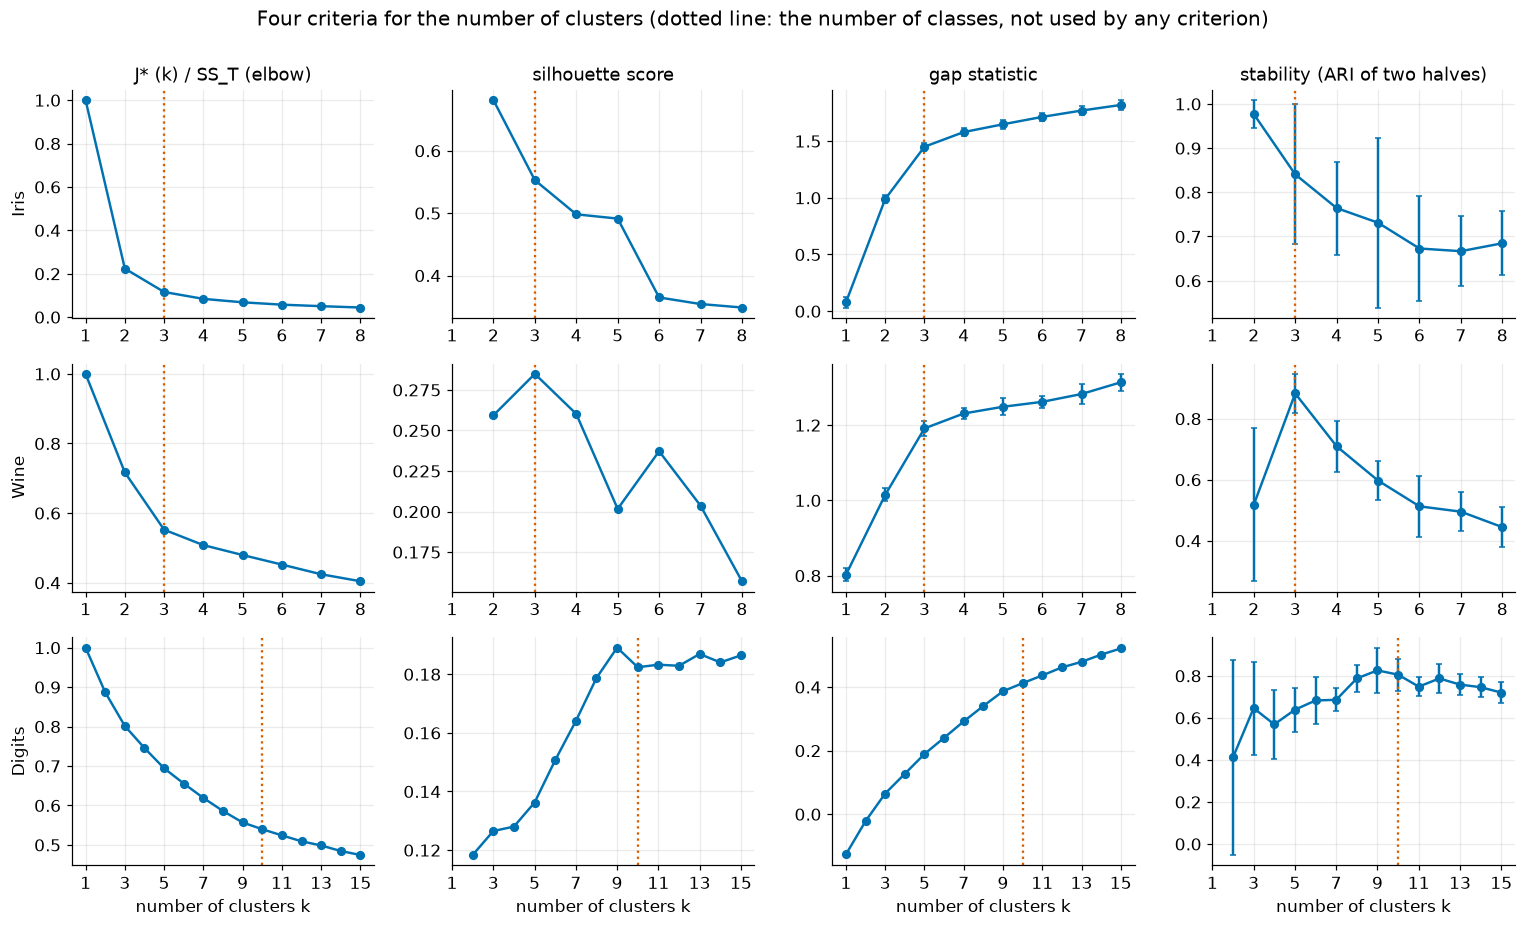

In [14]:
def figure_12_4():
    fig, axes = plt.subplots(3, 4, figsize=(14, 8.4))
    titles = ["J* (k) / SS_T (elbow)", "silhouette score", "gap statistic", "stability (ARI of two halves)"]
    for row, (name, r) in enumerate(k_study.items()):
        ks = np.array(r["ks"])
        n_true = len(np.unique(datasets[name][1]))
        series = [(r["J"] / r["J"][0], None), (r["sil"], None), (r["gap"], r["gap_s"]), (r["stab"], r["stab_sd"])]
        for col, (ax, (v, err)) in enumerate(zip(axes[row], series)):
            ax.errorbar(ks, v, yerr=err, color=BLUE, marker="o", markersize=5, linewidth=1.6, capsize=2)
            ax.axvline(n_true, color=VERMILION, linestyle=":", linewidth=1.5)
            if row == 0:
                ax.set_title(titles[col])
            if col == 0:
                ax.set_ylabel(name)
            if row == 2:
                ax.set_xlabel("number of clusters k")
            ax.set_xticks(ks if len(ks) <= 8 else ks[::2])
    fig.suptitle("Four criteria for the number of clusters (dotted line: the number of classes, not used by any criterion)", y=1.0)
    fig.tight_layout()
    plt.show()


figure_12_4()

Figure 12.4 shows the same numbers. In each row the dotted line marks the number of classes. For Iris the silhouette and the stability decrease from $k=2$ on, with the stability bars (one standard deviation over $15$ pairs of halves) wide for $k\ge3$. For Wine the silhouette and the stability have a peak at $3$, the only case in which the peak is visible in both, and the gap curve has a corner there. For Digits the curves are smooth, the peak of the silhouette is a shoulder, and the dotted line at $10$ does not coincide with anything. The conclusion is that the number of clusters is not a property of the data alone: it depends on the criterion, the scale of the structure sought and the purpose. In practice one looks at several criteria, at the partitions themselves, and asks which number is useful for what the clusters will be used for (Section 12.9 gives an example in which a deliberately larger $k$ is the right choice).

### 12.5.2 A validation set does not help either

To see the claim about held-out data, we split Digits at random into $900$ examples for fitting and $897$ held out, fit $k$-means on the first part and compute the mean squared distance of the held-out examples to their nearest center.

In [15]:
perm = np.random.default_rng(SEED).permutation(len(X_dig))
fit_idx, held_idx = perm[:900], perm[900:]
rows = []
for k in [2, 5, 10, 20, 50, 100, 200, 400]:
    m = KMeans(k, n_init=3, random_state=SEED).fit(X_dig[fit_idx])
    held = ((X_dig[held_idx] - m.cluster_centers_[m.predict(X_dig[held_idx])]) ** 2).sum(axis=1).mean()
    rows.append({"k": k, "mean distortion, fitting examples": m.inertia_ / len(fit_idx), "mean distortion, held-out examples": held})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

  k  mean distortion, fitting examples  mean distortion, held-out examples
  2                              4.196                               4.214
  5                              3.289                               3.293
 10                              2.526                               2.580
 20                              2.051                               2.151
 50                              1.517                               1.785
100                              1.154                               1.603
200                              0.797                               1.454
400                              0.413                               1.380


The distortion of the held-out examples decreases at every step, from $4.214$ with $2$ centers to $1.380$ with $400$, so that it never signals "enough". Overfitting shows up as a *gap* that widens: the ratio of the held-out to the fitting distortion is $1.00$ with $2$ centers and then $1.02$, $1.05$, $1.18$, $1.39$, $1.82$ and $3.34$ with $10$, $20$, $50$, $100$, $200$ and $400$ (the last is two fitting examples per center). The curve is flattening, which is the information that the elbow looks for, and it has the same ambiguity. A validation set measures how well the codebook describes new data, which is the right question for quantization (Section 12.6), but it does not tell us how many groups the data have.

## 12.6 Vector quantization: $k$-means as compression

### 12.6.1 Quantizers, rate and distortion

So far $k$-means found *groups*. The same algorithm answers a different question from communications engineering: how to represent a vector $\mathbf{x}\in\mathbb{R}^p$ with a few bits, losing as little as possible. A **vector quantizer** with $k$ codewords consists of a **codebook** $\boldsymbol\mu_1,\dots,\boldsymbol\mu_k\in\mathbb{R}^p$ and an **encoder** that sends $\mathbf{x}$ to the index $j(\mathbf{x})$ of a codeword; the decoder reconstructs $\hat{\mathbf{x}}=\boldsymbol\mu_{j(\mathbf{x})}$. Storing the index takes $\log_2k$ bits (the **rate**) in place of the $p$ numbers of $\mathbf{x}$, and the price is the **distortion** $D=\mathbb{E}\lVert\mathbf{X}-\hat{\mathbf{X}}\rVert^2$. On a sample, the distortion of the quantizer is $J/n$, with $J$ the $k$-means objective (12.3): **$k$-means is the design of an optimal quantizer for the empirical distribution**, and the two conditions of Proposition 12.3 are the necessary conditions of Lloyd (1957, published 1982) and Max (1960) for scalars, extended to vectors by Linde, Buzo and Gray (1980): the best encoder for a codebook sends each vector to its nearest codeword, and the best codeword for an encoder is the mean of the vectors sent to it.

How does the best achievable distortion depend on the rate? For a source with a density the answer is classical, and we state it without proof.

:::{admonition} Theorem 12.9 (high-resolution quantization; Zador, 1964, stated without proof)
:class: tip
Let $\mathbf{X}\in\mathbb{R}^p$ have a density $f$ with a finite moment of order slightly above $2$, and let $D^\ast(k)$ be the smallest distortion of a quantizer with $k$ codewords. Then, as $k\to\infty$,
$$
D^\ast(k)\;\sim\;c_p\,\lVert f\rVert_{p/(p+2)}\;k^{-2/p},
$$
where $c_p$ depends only on the dimension and $\lVert f\rVert_{p/(p+2)}=\big(\int f^{p/(p+2)}\big)^{(p+2)/p}$.
:::

The exponent is what matters: on a log–log plot the distortion falls along a line of slope $-2/p$, so that **doubling the number of codewords, one more bit, divides the distortion by $2^{2/p}$** (by $4$, that is $6$ dB, in dimension $1$; by only $2^{2/64}\approx1.02$ in dimension $64$). The theorem is about data that fill a $p$-dimensional region. When the data lie near a lower-dimensional set, the slope measured on a sample is that of the lower dimension, and $d_{\text{eff}}=-2/\text{slope}$ is an **effective dimension** of the data, in the sense of Section 4.7.3.

### 12.6.2 Quantizing the colors of a photograph

The data are the $427\times640=273{,}280$ pixels of the photograph `china.jpg` that ships with scikit-learn (a real photograph, Creative Commons licensed; see the data sources). Each pixel is a point of $[0,1]^3$ (red, green, blue). We fit the codebook on a random subsample of $20{,}000$ pixels, which is what one does with large images, and encode all the pixels with it. As a baseline we use the uniform quantizer that rounds each channel to $L$ equally spaced levels, with $L^3$ colors.

In [16]:
img = load_sample_image("china.jpg")
pix = img.reshape(-1, 3).astype(float) / 255
sub = pix[np.random.default_rng(SEED).choice(len(pix), 20000, replace=False)]
print(f"image {img.shape[1]} x {img.shape[0]} pixels = {len(pix):,} points of [0, 1]^3, codebook fitted on {len(sub):,} of them")


def quantization_error(P, recon):
    mse = float(((P - recon) ** 2).mean())                 # mean squared error per channel
    return mse, 10 * np.log10(1 / mse)                     # and the peak signal-to-noise ratio in dB


vq_models, rows = {}, []
for k in [2, 4, 8, 16, 27, 32, 64, 128, 216, 256]:
    vq_models[k] = KMeans(k, n_init=1, random_state=SEED).fit(sub)
    mse, psnr = quantization_error(pix, vq_models[k].cluster_centers_[vq_models[k].predict(pix)])
    row = {"k": k, "bits per pixel": np.log2(k), "compression (24 bits / rate)": 24 / np.log2(k), "MSE": mse, "PSNR (dB)": psnr}
    L = round(k ** (1 / 3))
    if L ** 3 == k:                                          # uniform per-channel baseline with the same number of colors
        row["uniform quantizer MSE, same k"] = quantization_error(pix, np.round(pix * (L - 1)) / (L - 1))[0]
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.5f}" if v < 0.1 else f"{v:.2f}"))

used = {L ** 3: len(np.unique(np.round(pix * (L - 1)).astype(int), axis=0)) for L in (2, 3, 4, 6)}
print("\ncolors of the uniform grid that the photograph actually uses:", ", ".join(f"{u} of {k}" for k, u in used.items()))

ks_img = np.array([k for k in vq_models if k >= 16])
mse_img = np.array([quantization_error(pix, vq_models[k].cluster_centers_[vq_models[k].predict(pix)])[0] for k in ks_img])
slope_img = np.polyfit(np.log(ks_img), np.log(mse_img), 1)[0]
print(f"\nlog-log slope of the distortion for k >= 16: {slope_img:.3f}; effective dimension -2/slope = {-2 / slope_img:.2f} (the pixels live in 3 dimensions)")

image 640 x 427 pixels = 273,280 points of [0, 1]^3, codebook fitted on 20,000 of them


  k  bits per pixel  compression (24 bits / rate)     MSE  PSNR (dB)  uniform quantizer MSE, same k
  2            1.00                         24.00 0.01976      17.04                            NaN
  4            2.00                         12.00 0.00702      21.54                            NaN
  8            3.00                          8.00 0.00328      24.84                        0.05394
 16            4.00                          6.00 0.00181      27.43                            NaN
 27            4.75                          5.05 0.00116      29.34                        0.01879
 32            5.00                          4.80 0.00101      29.96                            NaN
 64            6.00                          4.00 0.00059      32.28                        0.00895
128            7.00                          3.43 0.00037      34.33                            NaN
216            7.75                          3.09 0.00026      35.88                        0.00315



colors of the uniform grid that the photograph actually uses: 8 of 8, 17 of 27, 33 of 64, 82 of 216

log-log slope of the distortion for k >= 16: -0.734; effective dimension -2/slope = 2.73 (the pixels live in 3 dimensions)


The distortion falls steadily with the number of colors, and so does the visual error: with $k=16$ colors ($4$ bits per pixel instead of $24$, a compression of $6:1$) the PSNR is $27.4$ dB, with $256$ colors ($8$ bits, $3:1$) it is $36.4$ dB. (The sizes ignore the codebook, which has $256$ colors of $24$ bits, under a thousand bytes, against $273{,}280$ indices.) A codebook fitted to the colors of *this* image is much better than a fixed grid: with $8$ and with $27$ colors the mean squared error of $k$-means is about $16$ times smaller than that of the uniform quantizer ($0.0033$ against $0.0539$, and $0.0012$ against $0.0188$), with $64$ colors $15$ times, and with $216$ colors $12$ times ($0.00026$ against $0.00315$). The reason is visible in the last line of the output: the uniform grid wastes colors on regions of the color cube where this photograph has no pixel (it uses $17$ of the $27$ grid colors, $33$ of $64$ and $82$ of $216$), and the codebook puts every codeword where the pixels are.

The slope of the log-log curve of the distortion for $k\ge16$ is $-0.734$, which Theorem 12.9 turns into an effective dimension $-2/\text{slope}=2.73$ for pixels that live in $3$ dimensions: the estimate is consistent with the colors of a natural image occupying a region of the color cube that is slightly thinner than the cube. The measure should not be over-read, since it comes from a range of $k$ that spans little more than one decade and the asymptotic regime of the theorem is far away. Figure 12.5 shows the image with $4$, $16$ and $64$ colors. With $4$ colors the sky and the water merge, and the red of the tower is lost; with $16$ the reds and greens are back, but the smooth sky breaks into visible bands (false contours), which are the price of too few codewords for a region where the colors change slowly; with $64$ colors the image is close to the original and only slight banding remains in the sky.

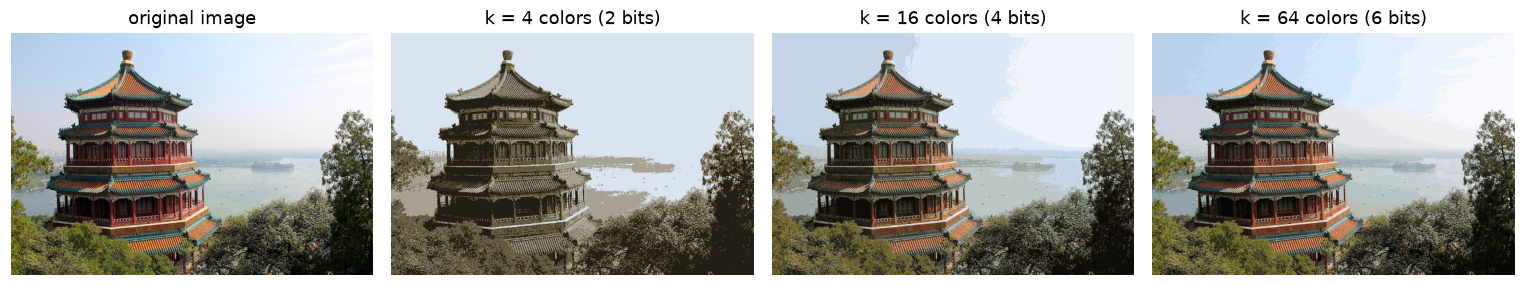

In [17]:
def figure_12_5():
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.1))
    panels = [("original image", img)] + [(f"k = {k} colors ({int(np.log2(k))} bits)", (vq_models[k].cluster_centers_[vq_models[k].predict(pix)].reshape(img.shape) * 255).round().astype(np.uint8))
                                          for k in (4, 16, 64)]
    for ax, (title, im) in zip(axes, panels):
        ax.imshow(im)
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    plt.show()


figure_12_5()

### 12.6.3 Digits as a codebook of images

On Digits the points are $64$-dimensional, and the theorem predicts a distortion that falls very slowly with $k$ if the images filled their space. We fit codebooks of $2$ to $200$ images and look at the rate–distortion curve and at the reconstructions.

In [18]:
dig_vq, rows = {}, []
for k in [2, 5, 10, 20, 50, 100, 200]:
    dig_vq[k] = KMeans(k, n_init=3, random_state=SEED).fit(X_dig)
    rows.append({"k": k, "bits per image": np.log2(k), "MSE per pixel": dig_vq[k].inertia_ / X_dig.size,
                 "ARI with the digits": adjusted_rand_score(y_dig, dig_vq[k].labels_)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
ks_dig = np.array([k for k in dig_vq if k >= 10])
slope_dig = np.polyfit(np.log(ks_dig), np.log([dig_vq[k].inertia_ / X_dig.size for k in ks_dig]), 1)[0]
print(f"\nlog-log slope for k >= 10: {slope_dig:.3f}; effective dimension -2/slope = {-2 / slope_dig:.1f} (the images have 64 pixels)")

  k  bits per image  MSE per pixel  ARI with the digits
  2          1.0000         0.0650               0.1381
  5          2.3219         0.0516               0.3392
 10          3.3219         0.0396               0.6669
 20          4.3219         0.0322               0.6259
 50          5.6439         0.0245               0.3330
100          6.6439         0.0195               0.1817
200          7.6439         0.0150               0.0936

log-log slope for k >= 10: -0.319; effective dimension -2/slope = 6.3 (the images have 64 pixels)


Ten codewords, $3.3$ bits per image, reduce the distortion to $54\%$ of the total variance ($J/\mathrm{SS}_T=0.540$); $200$ codewords reduce it to $0.0150$ per pixel, against $0.0733$ for the mean image. The log-log slope for $k\ge10$ is $-0.319$, which gives an effective dimension of $6.3$. For a cloud that filled the $64$-dimensional space the slope would be $-2/64=-0.031$, ten times flatter: the images are much more compressible than their dimension would suggest, which is the observation of Section 4.7.3 seen from another side. The number $6.3$ is lower than the ten to twenty components found there, and it should not be taken as a measurement of the dimension: with $1797$ images and at most $200$ codewords we are far from the asymptotic regime of the theorem (about nine images per codeword at $k=200$), and the distortion is measured on the images used for fitting, which flatters large codebooks.

The last column is a reminder that the quantizer and the clustering are different uses of one algorithm. The ARI with the digit labels is highest at $k=10$ ($0.667$) and falls as the codebook grows ($0.333$ with $50$ codewords, $0.094$ with $200$), although the distortion keeps decreasing: a partition into $200$ small groups does not match a partition into ten classes, even when each of the small groups is pure. The distortion measures how well the images are represented, the ARI how well the partition reproduces the ten classes; neither is a substitute for the other.

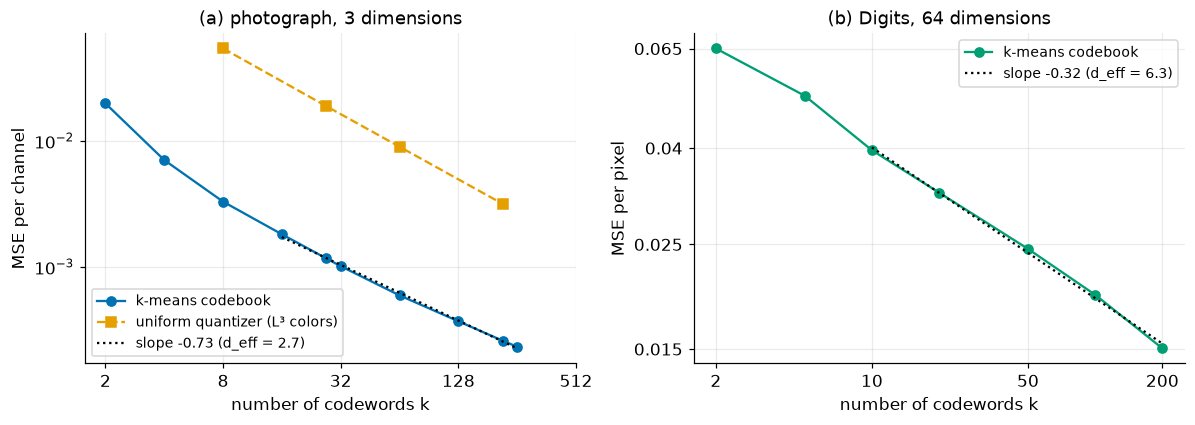

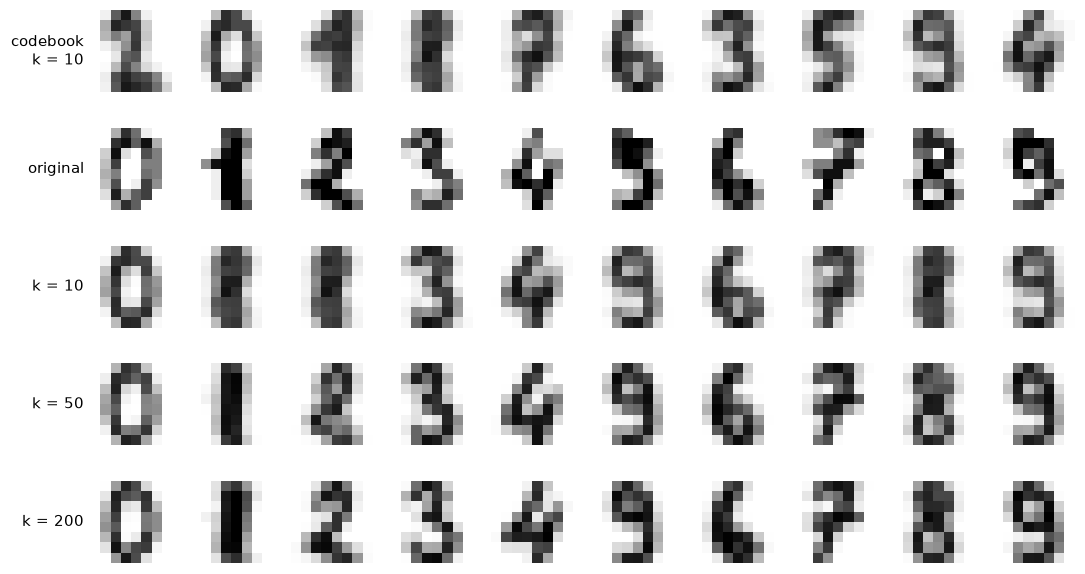

In [19]:
def figure_12_6():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    ax = axes[0]
    ks_all = np.array(sorted(vq_models))
    mse_all = np.array([quantization_error(pix, vq_models[k].cluster_centers_[vq_models[k].predict(pix)])[0] for k in ks_all])
    ax.loglog(ks_all, mse_all, "o-", color=BLUE, label="k-means codebook")
    uni_k = [8, 27, 64, 216]
    uni = [quantization_error(pix, np.round(pix * (round(k ** (1 / 3)) - 1)) / (round(k ** (1 / 3)) - 1))[0] for k in uni_k]
    ax.loglog(uni_k, uni, "s--", color=ORANGE, label="uniform quantizer (L³ colors)")
    c = np.polyfit(np.log(ks_img), np.log(mse_img), 1)
    ax.loglog(ks_img, np.exp(np.polyval(c, np.log(ks_img))), ":", color="black", label=f"slope {slope_img:.2f} (d_eff = {-2 / slope_img:.1f})")
    ax.set(xlabel="number of codewords k", ylabel="MSE per channel", title="(a) photograph, 3 dimensions")
    ax.set_xticks([2, 8, 32, 128, 512], ["2", "8", "32", "128", "512"])
    ax.minorticks_off()
    ax.legend(fontsize=9)
    ax = axes[1]
    ks_d = np.array(sorted(dig_vq))
    mse_d = np.array([dig_vq[k].inertia_ / X_dig.size for k in ks_d])
    ax.loglog(ks_d, mse_d, "o-", color=GREEN, label="k-means codebook")
    c = np.polyfit(np.log(ks_dig), np.log([dig_vq[k].inertia_ / X_dig.size for k in ks_dig]), 1)
    ax.loglog(ks_dig, np.exp(np.polyval(c, np.log(ks_dig))), ":", color="black", label=f"slope {slope_dig:.2f} (d_eff = {-2 / slope_dig:.1f})")
    ax.set(xlabel="number of codewords k", ylabel="MSE per pixel", title="(b) Digits, 64 dimensions")
    ax.set_xticks([2, 10, 50, 200], ["2", "10", "50", "200"])
    ax.set_yticks([0.015, 0.025, 0.04, 0.065], ["0.015", "0.025", "0.04", "0.065"])
    ax.minorticks_off()
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()


figure_12_6()


def figure_12_7():
    ks_show = [10, 50, 200]
    first = [int(np.where(y_dig == d)[0][0]) for d in range(10)]
    fig, axes = plt.subplots(2 + len(ks_show), 10, figsize=(10, 5.6))
    rows_img = [("codebook\nk = 10", dig_vq[10].cluster_centers_), ("original", X_dig[first])] + \
               [(f"k = {k}", dig_vq[k].cluster_centers_[dig_vq[k].predict(X_dig[first])]) for k in ks_show]
    for r, (label, imgs) in enumerate(rows_img):
        for c in range(10):
            ax = axes[r, c]
            ax.imshow(imgs[c].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for sp_ in ax.spines.values():
                sp_.set_visible(False)
        axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10)
    fig.tight_layout()
    plt.show()


figure_12_7()

Figure 12.6 shows the rate–distortion curves. In (a) the points of the photograph follow the line closely for $k\ge16$, and the uniform quantizer stays above the codebook at every size shown. In (b) the Digits curve is also a straight line in these coordinates, much steeper than a $64$-dimensional cloud would allow.

Figure 12.7 shows what the codewords look like. The first row is the codebook with $k=10$: blurred images that average the examples of a group, several of which resemble a digit. Below, the first example of each digit and its reconstruction by codebooks of $10$, $50$ and $200$ images. With $10$ codewords the reconstruction of the $0$, the $3$, the $4$, the $6$, the $7$ and the $9$ is recognizable, whereas the examples of the $1$, the $2$ and the $8$ are replaced by smudged vertical shapes and the $5$ by a codeword that resembles a $9$. With $50$ codewords most of the images become readable. The example of the digit $5$ is still reconstructed by a $9$-like codeword even with $200$: the encoder minimizes the distance in pixels, not the readability, and for a thick $5$ the nearest codeword in pixels can be a $9$.

Vector quantization is also the reason why $k$-means is used as a **preprocessing** step: replacing each example by the index of its codeword (or by its distances to the codewords, as in Section 12.9.3) is a data-driven discretization of the feature space. We use that in a moment; first we leave the Euclidean, convex clusters behind.

## 12.7 Beyond spheres: Gaussian mixtures and hierarchical clustering

### 12.7.1 Gaussian mixtures and the EM algorithm

$k$-means describes a cluster by its center only. A **Gaussian mixture model** (GMM) gives each cluster a center, a covariance matrix and a weight, and treats the data as drawn from a probability density: first a hidden label $z\in\{1,\dots,k\}$ is drawn with probabilities $\pi_1,\dots,\pi_k$, then $\mathbf{x}\sim\mathcal{N}(\boldsymbol\mu_z,\boldsymbol\Sigma_z)$. The density of $\mathbf{x}$ is the mixture $p(\mathbf{x})=\sum_{j=1}^k\pi_j\,\mathcal{N}(\mathbf{x};\boldsymbol\mu_j,\boldsymbol\Sigma_j)$, and the parameters $\theta=(\pi_j,\boldsymbol\mu_j,\boldsymbol\Sigma_j)_j$ are fitted by maximum likelihood (Chapter 2),
$$
\ell(\theta)=\sum_{i=1}^n\log\sum_{j=1}^k\pi_j\,\mathcal{N}(\mathbf{x}_i;\boldsymbol\mu_j,\boldsymbol\Sigma_j).
$$
The logarithm of a sum has no closed-form maximizer. If the labels $z_i$ were known the problem would split into $k$ ordinary Gaussian fits, and the **EM algorithm** (Dempster, Laird and Rubin, 1977) exploits this by alternating between guessing the labels and fitting. The guess is the posterior probability of the component $j$ for the example $i$, the **responsibility**
$$
r_{ij}=\Pr(z_i=j\mid\mathbf{x}_i)=\frac{\pi_j\,\mathcal{N}(\mathbf{x}_i;\boldsymbol\mu_j,\boldsymbol\Sigma_j)}{\sum_{l}\pi_l\,\mathcal{N}(\mathbf{x}_i;\boldsymbol\mu_l,\boldsymbol\Sigma_l)}\tag{12.4}
$$
(Bayes' rule, Chapter 2), a *soft* assignment: the example belongs to every cluster, with weights that sum to one.

:::{admonition} Proposition 12.10 (the M-step)
:class: tip
Given responsibilities $r_{ij}$, let $N_j=\sum_ir_{ij}$. The parameters that maximize the expected complete-data log-likelihood $Q=\sum_{i,j}r_{ij}\big[\log\pi_j+\log\mathcal{N}(\mathbf{x}_i;\boldsymbol\mu_j,\boldsymbol\Sigma_j)\big]$ are
$$
\pi_j=\frac{N_j}n,\qquad\boldsymbol\mu_j=\frac1{N_j}\sum_{i}r_{ij}\mathbf{x}_i,\qquad\boldsymbol\Sigma_j=\frac1{N_j}\sum_{i}r_{ij}(\mathbf{x}_i-\boldsymbol\mu_j)(\mathbf{x}_i-\boldsymbol\mu_j)^\top.\tag{12.5}
$$
:::

*Proof.* $Q$ separates into a term in $\pi$ and one term for each $(\boldsymbol\mu_j,\boldsymbol\Sigma_j)$. The first, $\sum_jN_j\log\pi_j$ with $\sum_j\pi_j=1$, is maximized by $\pi_j=N_j/n$ (a Lagrange multiplier gives $N_j/\pi_j=\text{const}$). The second is the log-likelihood of a Gaussian sample in which example $i$ has weight $r_{ij}$, whose maximizers are the weighted mean and the weighted covariance, as in the unweighted case of Chapter 2. $\blacksquare$

:::{admonition} Theorem 12.11 (EM never decreases the likelihood)
:class: tip
Let $\theta^{t+1}$ be obtained from $\theta^t$ by computing the responsibilities (12.4) at $\theta^t$ (E-step) and then the parameters (12.5) (M-step). Then $\ell(\theta^{t+1})\ge\ell(\theta^t)$.
:::

*Proof.* For any probabilities $q_{ij}$ over $j$ with $\sum_jq_{ij}=1$, Jensen's inequality for the concave logarithm gives
$$
\ell(\theta)=\sum_i\log\sum_jq_{ij}\frac{\pi_j\mathcal{N}(\mathbf{x}_i;\boldsymbol\mu_j,\boldsymbol\Sigma_j)}{q_{ij}}\;\ge\;\sum_{i,j}q_{ij}\log\frac{\pi_j\mathcal{N}(\mathbf{x}_i;\boldsymbol\mu_j,\boldsymbol\Sigma_j)}{q_{ij}}=:F(q,\theta),
$$
with equality when the ratio inside the logarithm does not depend on $j$, that is when $q_{ij}$ is the posterior (12.4). The E-step takes $q=r(\theta^t)$, so $F(q,\theta^t)=\ell(\theta^t)$. The M-step maximizes $F(q,\cdot)$ over $\theta$ (the term $-\sum q\log q$ does not depend on $\theta$, and the rest is $Q$ of Proposition 12.10), so $F(q,\theta^{t+1})\ge F(q,\theta^t)$. Therefore $\ell(\theta^{t+1})\ge F(q,\theta^{t+1})\ge F(q,\theta^t)=\ell(\theta^t)$. $\blacksquare$

The likelihood increases at every iteration and, being bounded for covariances kept away from singular matrices, converges; the limit is a stationary point, in general a local maximum, so that the initialization matters here too (scikit-learn starts from a $k$-means partition). The next result connects the two algorithms of the chapter.

:::{admonition} Proposition 12.12 ($k$-means is the limit of a mixture with vanishing variance)
:class: tip
Consider the mixture with equal weights $\pi_j=1/k$ and covariances $\boldsymbol\Sigma_j=\sigma^2\mathbf{I}$, with the same $\sigma^2$ for all the components. As $\sigma^2\to0$, the responsibility $r_{ij}$ tends to $1$ if $\boldsymbol\mu_j$ is the unique nearest center of $\mathbf{x}_i$ and to $0$ otherwise, and the M-step for the centers becomes the update step of Lloyd's algorithm.
:::

*Proof.* Here $r_{ij}\propto\exp(-\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2/2\sigma^2)$. Dividing numerator and denominator by the term of the nearest center $j^\ast$, every other term becomes $\exp\big(-(\lVert\mathbf{x}_i-\boldsymbol\mu_l\rVert^2-\lVert\mathbf{x}_i-\boldsymbol\mu_{j^\ast}\rVert^2)/2\sigma^2\big)\to0$. With hard responsibilities, $\boldsymbol\mu_j$ in (12.5) is the mean of the examples assigned to it. $\blacksquare$

So $k$-means is "hard EM for equal spherical components", and the mixture adds three things: soft assignments, a covariance per component (clusters that are elongated or tilted), and a likelihood, which allows model comparison. The covariance can be restricted to save parameters: **spherical** ($\boldsymbol\Sigma_j=\sigma_j^2\mathbf{I}$, $k$ parameters), **diagonal** ($kp$), **tied** (one full matrix shared by the components, $p(p+1)/2$) or **full** ($kp(p+1)/2$), on top of the $k-1$ weights and the $kp$ means. Comparing models with different numbers of parameters by the likelihood alone would always favor the largest, so we use the **Bayesian information criterion** $\mathrm{BIC}=-2\ell(\hat\theta)+d\ln n$, with $d$ the number of parameters (smaller is better; this is the convention of scikit-learn and of the $C_p$/BIC comparison of Section 10.3).

The following code implements EM, checks that the likelihood is monotone and that the result agrees with scikit-learn started from the same parameters, and shows what a mixture with full covariances does that $k$-means does not on Iris.

In [20]:
def em_gmm(X, pi, mu, Sigma, max_iter=500, tol=1e-10, reg=1e-6):
    """EM for a Gaussian mixture with full covariances: E-step (12.4), M-step (12.5)."""
    n, p = X.shape
    ll_hist = []
    for _ in range(max_iter):
        log_p = np.column_stack([np.log(pi[j]) + multivariate_normal(mu[j], Sigma[j], allow_singular=True).logpdf(X) for j in range(len(pi))])
        ll_i = logsumexp(log_p, axis=1)
        ll_hist.append(float(ll_i.sum()))
        R = np.exp(log_p - ll_i[:, None])                                   # responsibilities
        if len(ll_hist) > 1 and ll_hist[-1] - ll_hist[-2] < tol:
            break
        N = R.sum(axis=0)
        pi, mu = N / n, (R.T @ X) / N[:, None]
        Sigma = np.array([(R[:, j, None] * (X - mu[j])).T @ (X - mu[j]) / N[j] + reg * np.eye(p) for j in range(len(pi))])
    return pi, mu, Sigma, np.array(ll_hist), R


km3 = KMeans(3, n_init=10, random_state=SEED).fit(X_iris)
pi0 = np.bincount(km3.labels_) / len(X_iris)
mu0 = km3.cluster_centers_
Sig0 = np.array([np.cov(X_iris[km3.labels_ == j].T, bias=True) + 1e-6 * np.eye(4) for j in range(3)])
pi_, mu_, Sig_, ll_hist, R_ = em_gmm(X_iris, pi0, mu0, Sig0)
sk = GaussianMixture(3, covariance_type="full", weights_init=pi0, means_init=mu0, precisions_init=np.linalg.inv(Sig0),
                     reg_covar=1e-6, tol=1e-10, max_iter=500).fit(X_iris)
print(f"EM from the k-means solution: {len(ll_hist)} E-steps, log-likelihood {ll_hist[0]:.3f} -> {ll_hist[-1]:.3f}, "
      f"never decreases: {bool(np.all(np.diff(ll_hist) > -1e-9))}")
print(f"scikit-learn from the same start: log-likelihood {sk.score(X_iris) * len(X_iris):.3f}; "
      f"largest difference of the means {np.abs(np.sort(sk.means_, axis=0) - np.sort(mu_, axis=0)).max():.1e}; "
      f"ARI between the two sets of hard assignments {adjusted_rand_score(R_.argmax(1), sk.predict(X_iris)):.3f}")
print(f"weights {np.round(pi_, 3)};  mean largest responsibility {R_.max(axis=1).mean():.3f};  examples with largest responsibility < 0.9: {int((R_.max(axis=1) < 0.9).sum())}")
print(f"ARI with the species: k-means {adjusted_rand_score(y_iris, km3.labels_):.3f}, mixture with full covariances {adjusted_rand_score(y_iris, R_.argmax(1)):.3f}")

EM from the k-means solution: 41 E-steps, log-likelihood -197.320 -> -180.185, never decreases: True
scikit-learn from the same start: log-likelihood -180.185; largest difference of the means 8.3e-07; ARI between the two sets of hard assignments 1.000
weights [0.299 0.333 0.367];  mean largest responsibility 0.990;  examples with largest responsibility < 0.9: 3
ARI with the species: k-means 0.730, mixture with full covariances 0.904


Theorem 12.11 is confirmed: the log-likelihood rises from $-197.320$ at the $k$-means start to $-180.185$ and never decreases over the $41$ E-steps (Figure 12.9(a) shows that most of the increase takes place in the first fifteen). Our implementation and scikit-learn, started from the same parameters, reach the same log-likelihood, with means that agree to $8\times10^{-7}$ (the tolerance of the stopping rule) and the same hard assignments.

The soft assignments are nearly hard: the mean of the largest responsibility is $0.990$ and only $3$ of the $150$ flowers have a largest responsibility below $0.9$, the flowers at the boundary between versicolor and virginica. What the mixture changes is the *shape* of the groups, and it matters for the result. The ARI with the species is $0.904$ for the mixture with full covariances, against $0.730$ for $k$-means. The estimated weights ($0.299$, $0.333$, $0.367$, that is about $45$, $50$ and $55$ flowers) are close to the true proportions, while the sizes of the $k$-means clusters ($62$, $50$, $38$) are not: with equal spherical clusters the boundary between versicolor and virginica is the perpendicular bisector of the two centers, and it cuts through the more spread-out virginica group; with a covariance for each component the boundary can bend around it.

The likelihood of a mixture with free covariances has a flaw that the monotonicity theorem does not remove: it is **unbounded**. Center one component on a single example and shrink its covariance: the density of that example grows without limit while the other examples are explained by the other components. We check this on Iris, with a two-component mixture in which the first component is a Gaussian $\mathcal{N}(\mathbf{x}_1,\varepsilon\mathbf{I})$ centered on one flower and the second is fitted to the other $149$.

In [21]:
p_dim = X_iris.shape[1]
rest = X_iris[1:]
comp2 = multivariate_normal(rest.mean(axis=0), np.cov(rest.T, bias=True))
log_comp2 = comp2.logpdf(X_iris)
rows = []
for eps in [1.0, 1e-2, 1e-4, 1e-8, 1e-16, 1e-32, 1e-48, 1e-64]:
    # log N(x; x_1, eps I), written out so that it can be evaluated for tiny eps
    log_comp1 = -0.5 * p_dim * np.log(2 * np.pi * eps) - ((X_iris - X_iris[0]) ** 2).sum(axis=1) / (2 * eps)
    ll = logsumexp([np.log(1 / 150) + log_comp1, np.log(149 / 150) + log_comp2], axis=0).sum()
    rows.append({"variance of the first component": f"{eps:.0e}", "log-likelihood": ll})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"for comparison, the well-behaved 3-component mixture above has log-likelihood {ll_hist[-1]:.2f}")

variance of the first component  log-likelihood
                          1e+00         -380.77
                          1e-02         -366.98
                          1e-04         -369.56
                          1e-08         -351.13
                          1e-16         -314.29
                          1e-32         -240.61
                          1e-48         -166.93
                          1e-64          -93.25
for comparison, the well-behaved 3-component mixture above has log-likelihood -180.19


The log-likelihood of this model grows without limit as $\varepsilon\to0$: from $-380.77$ with $\varepsilon=1$ to $-93.25$ with $\varepsilon=10^{-64}$, by $73.7$ for every sixteen orders of magnitude of $\varepsilon$ (the density at the flower $\mathbf{x}_1$ is $(2\pi\varepsilon)^{-p/2}$ with $p=4$, whose logarithm increases by $\frac p2\ln10^{16}=73.7$), apart from a small dip at moderate $\varepsilon$ before the spike takes over. Between $\varepsilon=10^{-32}$ and $10^{-48}$ the model passes the log-likelihood of the sensible three-component mixture ($-180.19$) and then leaves it far behind. A mixture that describes one flower with a spike and the other $149$ with a single Gaussian has a larger likelihood than the one that finds the species, so the supremum of $\ell$ is $+\infty$ and maximum likelihood has no solution to look for. What EM finds, when it does not collapse onto a spike, is a *local* maximum, and the likelihood of a fitted mixture is therefore not an absolute measure of quality.

Implementations avoid this by adding a small multiple of the identity to every covariance (the `reg_covar` of scikit-learn, the `reg` of our code) and by restarting when a component collapses; the likelihood is then a quantity to be compared among *reasonable* local maxima. We now let the BIC choose the covariance structure and the number of components, on Iris and on Wine (standardized).

In [22]:
bic_study = {}
for name, kmax in [("Iris", 6), ("Wine", 6)]:
    X, y = datasets[name]
    res = {}
    for cov in ["spherical", "diag", "tied", "full"]:
        fits = [GaussianMixture(k, covariance_type=cov, n_init=5, random_state=SEED).fit(X) for k in range(1, kmax + 1)]
        res[cov] = {"bic": np.array([g.bic(X) for g in fits]), "ari": np.array([adjusted_rand_score(y, g.predict(X)) for g in fits])}
    bic_study[name] = res
    table = pd.DataFrame({f"{cov} BIC": r["bic"] for cov, r in res.items()}, index=range(1, kmax + 1))
    table.index.name = "k"
    print(f"\n{name}: BIC (smaller is better)")
    print(table.to_string(float_format=lambda v: f"{v:.1f}"))
    best = min(((r["bic"][k], cov, k + 1) for cov, r in res.items() for k in range(kmax)))
    print(f"best BIC: {best[0]:.1f} for covariance '{best[1]}' with k = {best[2]} (ARI with the labels {res[best[1]]['ari'][best[2] - 1]:.3f});"
          f"   ARI at k = 3: " + ", ".join(f"{cov} {r['ari'][2]:.3f}" for cov, r in res.items()))


Iris: BIC (smaller is better)
   spherical BIC  diag BIC  tied BIC  full BIC
k                                             
1         1804.1    1522.1     830.0     830.0
2         1012.2     857.6     688.1     574.0
3          853.8     744.6     633.8     580.9
4          783.9     705.1     618.0     622.2
5          742.7     701.1     607.2     673.1
6          705.8     697.0     620.4     695.8
best BIC: 574.0 for covariance 'full' with k = 2 (ARI with the labels 0.568);   ARI at k = 3: spherical 0.730, diag 0.745, tied 0.886, full 0.904



Wine: BIC (smaller is better)
   spherical BIC  diag BIC  tied BIC  full BIC
k                                             
1         6639.4    6701.6    5741.3    5741.3
2         6135.0    5983.7    5643.3    5608.3
3         5708.8    5543.4    5570.9    5806.3
4         5645.8    5476.5    5529.9    5806.8
5         5649.7    5539.1    5503.4    6026.1
6         5634.4    5560.9    5524.1    6353.4
best BIC: 5476.5 for covariance 'diag' with k = 4 (ARI with the labels 0.683);   ARI at k = 3: spherical 0.879, diag 0.915, tied 0.946, full 0.880


**Iris.** The smallest BIC is $574.0$ for a mixture of *two* components with full covariances (the partition is setosa against the rest: ARI with the species $0.568$), as for the silhouette and the stability of Section 12.5. The model with three components and full covariances follows at $580.9$, a difference of $6.9$, which on the scale of Kass and Raftery (1995, differences of $6$ to $10$ count as strong evidence) is a clear but not overwhelming preference for two. The covariance structure matters more than the number of components: with spherical or diagonal covariances the BIC at $k=3$ is $853.8$ and $744.6$, much worse than for a full or tied matrix ($580.9$ and $633.8$), because the four features are strongly correlated within each species. The ARI at $k=3$ confirms it: $0.730$ (spherical, equal to $k$-means), $0.745$ (diagonal), $0.886$ (tied) and $0.904$ (full).

**Wine.** The smallest BIC is $5476.5$, for *diagonal* covariances and $k=4$ components, a model whose ARI with the cultivars is only $0.683$: the fourth component divides one cultivar. With $k=3$ the BIC prefers the diagonal structure ($5543.4$, ARI $0.915$) to the spherical ($5708.8$), the tied ($5570.9$) and the full one ($5806.3$). The full covariances are heavily penalized: a component has $13\cdot14/2=91$ covariance parameters, and a cultivar has about $60$ wines. The best ARI at $k=3$ is $0.946$, obtained with tied covariances, which is not the model chosen by the BIC.

Two lessons follow. The BIC answers the question of *density estimation* ("which model describes the distribution of the features best, after a penalty?"), and it is not guaranteed to select the model that agrees with a grouping defined by other means. And its choice depends on the family of models searched: with full covariances only, Iris has two components and Wine has two.

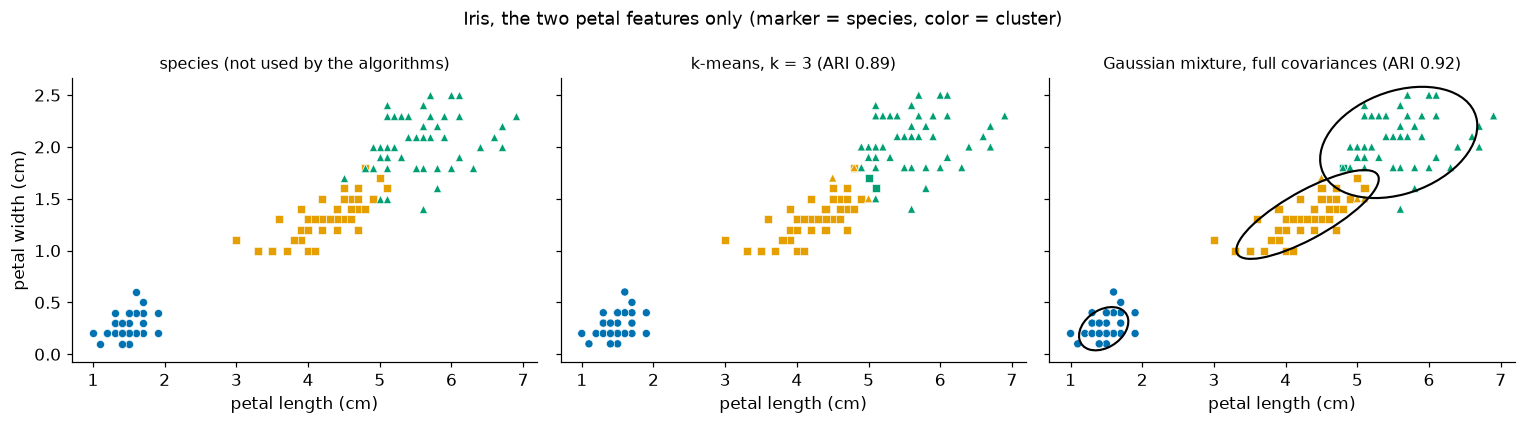

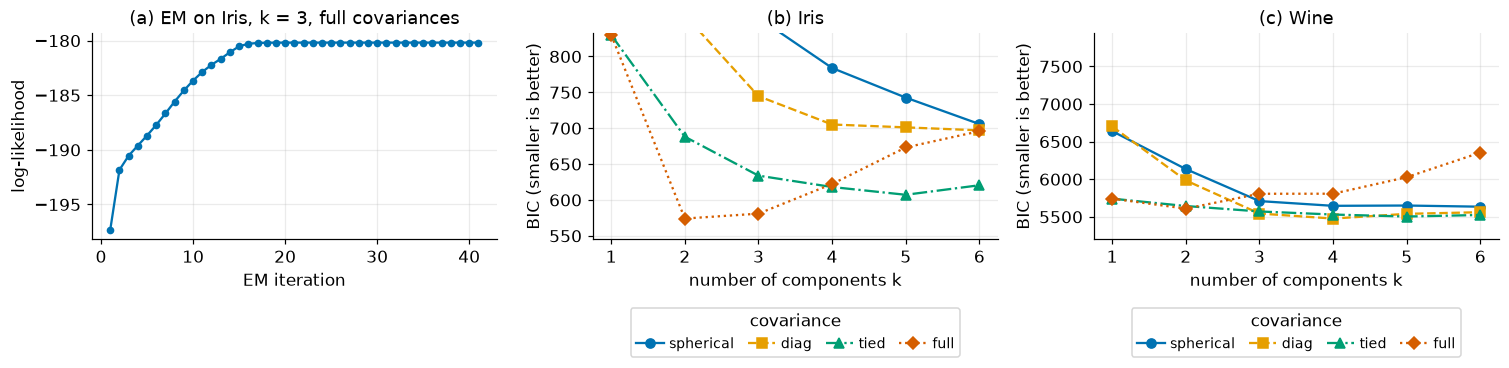

In [23]:
def figure_12_8():
    Xp = X_iris[:, 2:4]
    km_p = KMeans(3, n_init=10, random_state=SEED).fit(Xp)
    gm_p = GaussianMixture(3, covariance_type="full", n_init=10, random_state=SEED).fit(Xp)
    markers = ["o", "s", "^"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharex=True, sharey=True)
    def match_to_species(lab):
        """Rename the clusters so that each takes the color of the species it overlaps most (colors only; nothing is recomputed)."""
        table = pd.crosstab(y_iris, lab).reindex(index=range(3), columns=range(3), fill_value=0).to_numpy()
        rows_, cols_ = linear_sum_assignment(-table)
        perm = np.empty(3, int)
        perm[cols_] = rows_
        return perm[lab]
    lab_km, lab_gm = match_to_species(km_p.labels_), match_to_species(gm_p.predict(Xp))
    parts = [("species (not used by the algorithms)", y_iris, None),
             (f"k-means, k = 3 (ARI {adjusted_rand_score(y_iris, km_p.labels_):.2f})", lab_km, None),
             (f"Gaussian mixture, full covariances (ARI {adjusted_rand_score(y_iris, gm_p.predict(Xp)):.2f})", lab_gm, gm_p)]
    for ax, (title, lab, gm) in zip(axes, parts):
        for s in range(3):
            m = y_iris == s
            ax.scatter(Xp[m, 0], Xp[m, 1], c=[CLUSTER_COLORS[a] for a in lab[m]] if lab is not y_iris else CLUSTER_COLORS[s],
                       marker=markers[s], s=28, edgecolor="white", linewidth=0.4)
        if gm is not None:
            for mu, S, c in zip(gm.means_, gm.covariances_, range(3)):
                w, V = np.linalg.eigh(S)
                ang = np.degrees(np.arctan2(V[1, 1], V[0, 1]))
                ax.add_patch(Ellipse(mu, 4 * np.sqrt(w[1]), 4 * np.sqrt(w[0]), angle=ang, fill=False, edgecolor="black", linewidth=1.4))
        ax.set_title(title, fontsize=10.5)
        ax.set_xlabel("petal length (cm)")
        ax.grid(False)
    axes[0].set_ylabel("petal width (cm)")
    fig.suptitle("Iris, the two petal features only (marker = species, color = cluster)", fontsize=11.5)
    fig.tight_layout()
    plt.show()


figure_12_8()


def figure_12_9():
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    ax = axes[0]
    ax.plot(np.arange(1, len(ll_hist) + 1), ll_hist, "o-", color=BLUE, markersize=4)
    ax.set(xlabel="EM iteration", ylabel="log-likelihood", title="(a) EM on Iris, k = 3, full covariances")
    for ax, (name, res) in zip(axes[1:], bic_study.items()):
        for (cov, r), mk, col in zip(res.items(), ["o", "s", "^", "D"], [BLUE, ORANGE, GREEN, VERMILION]):
            ax.plot(np.arange(1, len(r["bic"]) + 1), r["bic"], marker=mk, color=col, linestyle=["-", "--", "-.", ":"][list(res).index(cov)], label=cov)
        lo = min(r["bic"].min() for r in res.values())
        ax.set_ylim(lo - 0.05 * abs(lo), lo + 0.45 * abs(lo))
        ax.set(xlabel="number of components k", ylabel="BIC (smaller is better)", title=f"({'bc'[list(bic_study).index(name)]}) {name}")
        ax.legend(title="covariance", fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=4, columnspacing=1.0, handletextpad=0.4)
    fig.tight_layout()
    plt.show()


figure_12_9()

Figure 12.8 shows the difference on the two petal features, which are enough to draw it: in the central panel the partition of $k$-means (ARI $0.89$ on these two features) has boundaries that are straight lines, and in the right panel the mixture with full covariances (ARI $0.92$) describes versicolor by a narrow ellipse along the diagonal and virginica by a larger one, which is what the species look like. Figure 12.9 collects the likelihood and the BIC. In (a) the log-likelihood of EM rises quickly and flattens (Iris, $k=3$, full covariances). In (b) and (c) the BIC is plotted against $k$ for the four covariance structures, with the vertical axis cut to show the region of the minimum (for Iris the spherical and diagonal curves are far above at small $k$): the curve of the full covariances is the lowest at $k=2$ in (b) and the highest at large $k$ in (c), where the number of parameters grows fastest.

### 12.7.2 Hierarchical clustering and Ward's criterion

A second way to avoid choosing $k$ in advance is to build the whole family of partitions. **Agglomerative clustering** starts from the $n$ examples as $n$ clusters and repeatedly merges the two clusters that are closest, until one cluster is left; the record of the merges, with the distance at which each took place, is a **dendrogram**, and cutting it at a height gives a partition into any number of clusters, nested in the others. What "closest" means for two clusters $A$ and $B$ is the **linkage**:

| linkage | distance between $A$ and $B$ | tends to produce |
|---|---|---|
| single | $\min_{\mathbf{a}\in A,\mathbf{b}\in B}\lVert\mathbf{a}-\mathbf{b}\rVert$ | long, thin chains; isolates outliers |
| complete | $\max_{\mathbf{a}\in A,\mathbf{b}\in B}\lVert\mathbf{a}-\mathbf{b}\rVert$ | compact clusters of similar diameter |
| average | $\frac1{n_An_B}\sum_{\mathbf{a}\in A,\mathbf{b}\in B}\lVert\mathbf{a}-\mathbf{b}\rVert$ | in between |
| Ward | increase of $\mathrm{SS}_W$ caused by the merge | compact clusters of similar size |

The last row is the one that connects with the rest of the chapter, and it is Proposition 12.2(b).

:::{admonition} Proposition 12.13 (Ward's criterion is the $k$-means objective)
:class: tip
The merge cost of Ward's method is $\Delta(A,B)=\mathrm{SS}(A\cup B)-\mathrm{SS}(A)-\mathrm{SS}(B)=\frac{n_An_B}{n_A+n_B}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2$ by (12.2): at each step Ward's method makes the merge that **increases the within-cluster scatter the least**, so it is a greedy, bottom-up minimization of the $k$-means objective, whereas Lloyd's algorithm is an iterative improvement of a partition into a fixed number of clusters. The height of a merge in the dendrogram of SciPy is $\sqrt{2\Delta(A,B)}$.
:::

Single linkage has a different structure, which explains its chaining.

:::{admonition} Proposition 12.14 (single linkage and the minimum spanning tree)
:class: tip
The partition into $k$ clusters obtained by single linkage is the partition into connected components of the minimum spanning tree of the complete graph of the examples (edge weights = distances) after the $k-1$ heaviest edges have been removed.
:::

*Proof.* Kruskal's algorithm builds the minimum spanning tree by examining the edges in increasing order of weight and adding an edge when it joins two different components; the components at each stage are exactly the clusters of single linkage, which merges the two clusters at the smallest distance between any of their members. Stopping when $k$ components remain means leaving out the $k-1$ heaviest edges of the tree. $\blacksquare$

A cluster of single linkage is therefore a set connected by a chain of short steps, whatever its shape: this is why the method finds elongated clusters that $k$-means cannot (Section 12.8), and why one outlier or a thin bridge of points between two groups is enough to merge them. The cost of the standard algorithms is $O(n^2)$ memory for the matrix of distances and between $O(n^2)$ and $O(n^3)$ time, which restricts the method to data sets of a few thousand points. The code checks Proposition 12.13 on the merges of Iris, compares the value of $\mathrm{SS}_W$ obtained by cutting Ward's dendrogram with that of $k$-means, checks Proposition 12.14 on Wine, and compares the four linkages on Iris and Wine.

In [24]:
Z = hier.linkage(X_iris, "ward")
members = {i: [i] for i in range(len(X_iris))}
errs = []
for t, (a, b, h, _) in enumerate(Z):
    members[len(X_iris) + t] = members[int(a)] + members[int(b)]
    if t in (0, 50, 100, 140, 147):
        A, B = X_iris[members[int(a)]], X_iris[members[int(b)]]
        delta = len(A) * len(B) / (len(A) + len(B)) * ((A.mean(axis=0) - B.mean(axis=0)) ** 2).sum()
        errs.append(abs(h - np.sqrt(2 * delta)))
print(f"Ward merge heights against sqrt(2 n_A n_B/(n_A+n_B) ||mu_A - mu_B||^2): largest difference over 5 merges {max(errs):.1e}")

print("heights of the last four merges of the Ward dendrogram of Iris (the last one first):", ", ".join(f"{h:.2f}" for h in Z[:-5:-1, 2]))

rows = []
for k in [2, 3, 4, 5, 6]:
    lab_w = hier.fcluster(Z, k, "maxclust")
    rows.append({"k": k, "SS_W, Ward cut": ss_within(X_iris, lab_w), "SS_W, k-means": KMeans(k, n_init=10, random_state=SEED).fit(X_iris).inertia_})
print(pd.DataFrame(rows).assign(**{"excess of Ward": lambda d: d["SS_W, Ward cut"] / d["SS_W, k-means"] - 1}).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# Proposition 12.14 on Wine: cut the heaviest k - 1 edges of the minimum spanning tree
mst = csg.minimum_spanning_tree(squareform(pdist(X_wine))).toarray()
edges = np.argwhere(mst > 0)
order = np.argsort(-mst[mst > 0])
for k in (3, 5):
    cut = mst.copy()
    for e in order[:k - 1]:
        cut[tuple(edges[e])] = 0
    mst_labels = csg.connected_components(sp.csr_matrix(cut), directed=False)[1]
    single = AgglomerativeClustering(k, linkage="single").fit_predict(X_wine)
    print(f"Wine, k = {k}: ARI between the MST cut and single linkage {adjusted_rand_score(mst_labels, single):.3f}; cluster sizes {sorted(np.bincount(single).tolist(), reverse=True)}")

rows = []
for name, k in [("Iris", 3), ("Wine", 3)]:
    X, y = datasets[name]
    for link in ["ward", "complete", "average", "single"]:
        lab = AgglomerativeClustering(k, linkage=link).fit_predict(X)
        rows.append({"data": name, "linkage": link, "ARI with the labels": adjusted_rand_score(y, lab), "cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
    rows.append({"data": name, "linkage": "(k-means)", "ARI with the labels": adjusted_rand_score(y, KMeans(k, n_init=10, random_state=SEED).fit_predict(X)),
                 "cluster sizes": sorted(np.bincount(KMeans(k, n_init=10, random_state=SEED).fit_predict(X)).tolist(), reverse=True)})
print()
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Ward merge heights against sqrt(2 n_A n_B/(n_A+n_B) ||mu_A - mu_B||^2): largest difference over 5 merges 6.9e-15
heights of the last four merges of the Ward dendrogram of Iris (the last one first): 32.45, 12.30, 6.40, 4.85
 k  SS_W, Ward cut  SS_W, k-means  excess of Ward
 2         154.947        152.348           0.017
 3          79.297         78.851           0.006
 4          58.821         57.228           0.028
 5          47.071         46.461           0.013
 6          39.744         39.040           0.018
Wine, k = 3: ARI between the MST cut and single linkage 1.000; cluster sizes [174, 3, 1]
Wine, k = 5: ARI between the MST cut and single linkage 1.000; cluster sizes [172, 3, 1, 1, 1]



data   linkage  ARI with the labels cluster sizes
Iris      ward                0.731  [64, 50, 36]
Iris  complete                0.642  [72, 50, 28]
Iris   average                0.759  [64, 50, 36]
Iris    single                0.564   [98, 50, 2]
Iris (k-means)                0.730  [62, 50, 38]
Wine      ward                0.790  [64, 58, 56]
Wine  complete                0.577  [69, 58, 51]
Wine   average               -0.005   [174, 3, 1]
Wine    single               -0.007   [174, 3, 1]
Wine (k-means)                0.897  [65, 62, 51]


Proposition 12.13 is confirmed: the heights of the merges of SciPy agree with $\sqrt{2\Delta}$ to $7\times10^{-15}$. The last four merges of the Iris dendrogram are at the heights $32.45$, $12.30$, $6.40$ and $4.85$: the large gap before the last merge, the one that joins setosa to the rest, is the dendrogram's version of the preference of the silhouette for two clusters.

Cutting Ward's dendrogram gives a partition that is never better than $k$-means for the objective, as one expects from a greedy method, and never much worse: $\mathrm{SS}_W$ exceeds the $k$-means value by $0.6\%$ to $2.8\%$ for $k=2,\dots,6$. (The $k$-means values are themselves local minima, found with ten starts.) The Wine rows of the last table show what the other linkages do. Single linkage and average linkage produce clusters of sizes $174$, $3$ and $1$: they find outliers and chain everything else into one cluster, with ARI $-0.007$ and $-0.005$. Complete linkage gives clusters of reasonable sizes but an ARI of $0.577$, and Ward $0.790$, below $k$-means ($0.897$). On Iris the ranking is different: average linkage is the best ($0.759$) and Ward ($0.731$) matches $k$-means ($0.730$), while single linkage isolates two flowers ($98$, $50$, $2$). No linkage is uniformly the best, and the one that works on a data set depends on its geometry.

The check of Proposition 12.14 on Wine is exact: cutting the $k-1$ heaviest edges of the minimum spanning tree gives the same partition as single linkage (ARI $1.000$) for $k=3$ and $5$, and the partitions are those of sizes $174,3,1$ and $172,3,1,1,1$: the heaviest edges of the tree lead to isolated wines, which is the chaining effect of the previous paragraph.

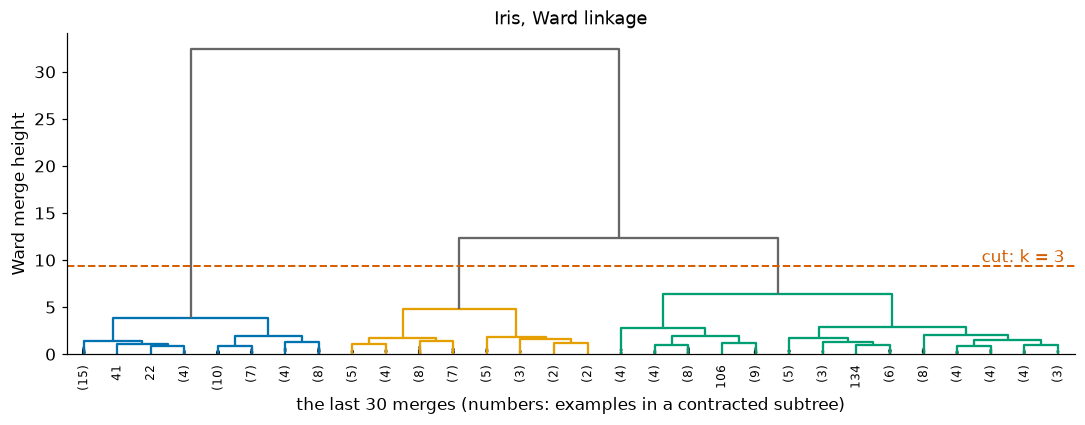

In [25]:
def figure_12_10():
    Zw = hier.linkage(X_iris, "ward")
    thr = (Zw[-3, 2] + Zw[-2, 2]) / 2                        # a cut between the 3-cluster and the 2-cluster levels
    hier.set_link_color_palette([BLUE, ORANGE, GREEN])
    fig, ax = plt.subplots(figsize=(10, 4.0))
    hier.dendrogram(Zw, truncate_mode="lastp", p=30, color_threshold=thr, above_threshold_color="#666666", ax=ax,
                    leaf_rotation=90, leaf_font_size=8, show_contracted=True)
    ax.axhline(thr, color=VERMILION, linestyle="--", linewidth=1.3)
    ax.text(0.99, thr, "  cut: k = 3", color=VERMILION, ha="right", va="bottom", transform=ax.get_yaxis_transform())
    ax.set(xlabel="the last 30 merges (numbers: examples in a contracted subtree)", ylabel="Ward merge height", title="Iris, Ward linkage")
    ax.grid(False)
    fig.tight_layout()
    plt.show()
    hier.set_link_color_palette(None)


figure_12_10()

Figure 12.10 shows the top of the Ward dendrogram of Iris (the last $30$ merges; the numbers under the leaves are the sizes of the subtrees that were contracted). The horizontal line cuts it into three clusters, with the setosa branch on the left; a cut at any height between $12.30$ and $32.45$ would give two. The advantage of the dendrogram over a single partition is that it displays *all* the scales at once and lets the reader decide where the structure stops being convincing.

## 12.8 Spectral clustering

### 12.8.1 When distances to centers are the wrong idea

The clusters of $k$-means are Voronoi cells, which are convex; those of a Gaussian mixture are ellipsoids. Many groups of real data are neither: a ring around a disk, two interleaved crescents, a long curved ridge. What these groups have in common is **connectivity**: each example is close to some other example of its own group, even if the group as a whole is far from being round. Spectral clustering turns that idea into an algorithm by first replacing the data with a **similarity graph**, and then clustering the vertices of the graph.

The graph has the $n$ examples as vertices and a symmetric weight $w_{ij}\ge0$ on each pair, large for similar examples. Three constructions are common: the **$\varepsilon$-graph** (weight $1$ if $\lVert\mathbf{x}_i-\mathbf{x}_j\rVert\le\varepsilon$), the **fully connected graph** with Gaussian weights $w_{ij}=\exp(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma^2)$ (the Gaussian kernel of Chapter 9), and the **$m$-nearest-neighbor graph**, with weight $1$ if $\mathbf{x}_j$ is among the $m$ nearest neighbors of $\mathbf{x}_i$ *or* the reverse, which adapts to regions of different density and is the one we use. Let $\mathbf{W}=(w_{ij})$, let $d_i=\sum_jw_{ij}$ be the **degree** of vertex $i$ and $\mathbf{D}=\mathrm{diag}(d_1,\dots,d_n)$.

:::{admonition} Definition 12.5 (graph Laplacians)
:class: tip
Assume $d_i>0$ for all $i$. The **unnormalized Laplacian**, the **symmetric normalized Laplacian** and the **random-walk Laplacian** are
$$
\mathbf{L}=\mathbf{D}-\mathbf{W},\qquad\mathbf{L}_{\mathrm{sym}}=\mathbf{I}-\mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2},\qquad\mathbf{L}_{\mathrm{rw}}=\mathbf{I}-\mathbf{D}^{-1}\mathbf{W}.
$$
:::

:::{admonition} Proposition 12.15 (properties of the Laplacians)
:class: tip
(a) For every $\mathbf{f}\in\mathbb{R}^n$, $\ \mathbf{f}^\top\mathbf{L}\mathbf{f}=\frac12\sum_{i,j}w_{ij}(f_i-f_j)^2$. Hence $\mathbf{L}$ is positive semidefinite and $\mathbf{L}\mathbf{1}=\mathbf{0}$.

(b) The multiplicity of the eigenvalue $0$ of $\mathbf{L}$ is the number of connected components of the graph, and the eigenspace is spanned by the indicator vectors of the components.

(c) $\mathbf{L}_{\mathrm{sym}}$ is positive semidefinite with eigenvalues in $[0,2]$. For $\lambda\in\mathbb{R}$ and $\mathbf{v}\in\mathbb{R}^n$ the following are equivalent: $\mathbf{L}_{\mathrm{rw}}\mathbf{v}=\lambda\mathbf{v}$; $\mathbf{L}\mathbf{v}=\lambda\mathbf{D}\mathbf{v}$; $\mathbf{L}_{\mathrm{sym}}\mathbf{u}=\lambda\mathbf{u}$ with $\mathbf{u}=\mathbf{D}^{1/2}\mathbf{v}$.
:::

*Proof.* (a) $\sum_{i,j}w_{ij}(f_i-f_j)^2=\sum_{i,j}w_{ij}f_i^2+\sum_{i,j}w_{ij}f_j^2-2\sum_{i,j}w_{ij}f_if_j=2\mathbf{f}^\top\mathbf{D}\mathbf{f}-2\mathbf{f}^\top\mathbf{W}\mathbf{f}=2\mathbf{f}^\top\mathbf{L}\mathbf{f}$. (b) If $\mathbf{L}\mathbf{f}=\mathbf{0}$ then $\mathbf{f}^\top\mathbf{L}\mathbf{f}=0$, so by (a) $f_i=f_j$ whenever $w_{ij}>0$, and $\mathbf{f}$ is constant on each connected component; conversely the indicator of a component is in the null space (every term of (a) vanishes). The indicators of different components are linearly independent. (c) $\mathbf{f}^\top\mathbf{L}_{\mathrm{sym}}\mathbf{f}=\frac12\sum_{i,j}w_{ij}\big(f_i/\sqrt{d_i}-f_j/\sqrt{d_j}\big)^2\ge0$, and the same computation with a plus sign shows that $\mathbf{f}^\top(\mathbf{I}+\mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2})\mathbf{f}\ge0$, that is $\lambda\le2$. The equivalences are $\mathbf{D}^{-1}(\mathbf{D}-\mathbf{W})\mathbf{v}=\lambda\mathbf{v}\iff(\mathbf{D}-\mathbf{W})\mathbf{v}=\lambda\mathbf{D}\mathbf{v}\iff\mathbf{D}^{-1/2}\mathbf{L}\mathbf{D}^{-1/2}(\mathbf{D}^{1/2}\mathbf{v})=\lambda\mathbf{D}^{1/2}\mathbf{v}$. $\blacksquare$

Part (a) is a **smoothness measure**: $\mathbf{f}^\top\mathbf{L}\mathbf{f}$ is small when $\mathbf{f}$ takes similar values on similar examples. We will use it twice, to derive the algorithm and, in Section 12.9, to propagate labels. The code builds the $m$-nearest-neighbor graph of Iris and of Digits, checks (a) on a random vector, and counts the zero eigenvalues of $\mathbf{L}_{\mathrm{sym}}$ (the same multiplicity as for $\mathbf{L}$ by (c)) against the number of connected components.

In [26]:
def knn_similarity(X, m):
    """Symmetric 0/1 adjacency of the m-nearest-neighbor graph (an edge if either example is among the other's m nearest)."""
    A = kneighbors_graph(X, m, mode="connectivity", include_self=False)
    return ((A + A.T) > 0).astype(float).toarray()


def laplacians(W):
    d = W.sum(axis=1)
    L = np.diag(d) - W
    L_sym = np.eye(len(W)) - W / np.sqrt(d)[:, None] / np.sqrt(d)[None, :]
    return L, L_sym, d


W_iris = knn_similarity(X_iris, 10)
L_iris, Ls_iris, d_iris = laplacians(W_iris)
f = np.random.default_rng(SEED).standard_normal(len(X_iris))
quad = 0.5 * (W_iris * (f[:, None] - f[None, :]) ** 2).sum()
print(f"Proposition 12.15(a) on the 10-NN graph of Iris: f'Lf = {f @ L_iris @ f:.6f}, (1/2) sum w_ij (f_i - f_j)^2 = {quad:.6f}")

rows = []
for name, X, m in [("Iris", X_iris, 5), ("Iris", X_iris, 10), ("Digits", X_dig, 5), ("Digits", X_dig, 10), ("Wine", X_wine, 5), ("Wine", X_wine, 10)]:
    W = knn_similarity(X, m)
    _, Ls, _ = laplacians(W)
    ev = np.linalg.eigvalsh(Ls)
    n_comp, comp = csg.connected_components(sp.csr_matrix(W), directed=False)
    rows.append({"data": name, "m": m, "connected components": n_comp, "eigenvalues of L_sym below 1e-10": int((ev < 1e-10).sum()),
                 "component sizes": sorted(np.bincount(comp).tolist(), reverse=True), "largest eigenvalue": ev.max()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Proposition 12.15(a) on the 10-NN graph of Iris: f'Lf = 1442.170545, (1/2) sum w_ij (f_i - f_j)^2 = 1442.170545


  data  m  connected components  eigenvalues of L_sym below 1e-10 component sizes  largest eigenvalue
  Iris  5                     2                                 2       [100, 50]               1.511
  Iris 10                     2                                 2       [100, 50]               1.340
Digits  5                     2                                 2      [1770, 27]               1.607
Digits 10                     1                                 1          [1797]               1.393
  Wine  5                     1                                 1           [178]               1.573
  Wine 10                     1                                 1           [178]               1.371


Part (a) of Proposition 12.15 holds to the digits printed ($f^\top\mathbf{L}f=1442.093502$ in both forms). The number of eigenvalues of $\mathbf{L}_{\mathrm{sym}}$ equal to zero is the number of connected components in all six graphs, and the largest eigenvalues ($1.34$ to $1.61$) are below the bound $2$. The components deserve a look, because they are the first clusters that the graph provides without any computation. The $10$-nearest-neighbor graph of Iris has two, of $100$ and $50$ flowers: no setosa flower has a flower of another species among its ten nearest neighbors, and no flower of the other species has a setosa flower among its own, so the graph separates setosa by construction. The Digits graph with $m=5$ has two components, one of $27$ images whose nearest neighbors in the graph all lie inside the group, and the rest of $1770$; with $m=10$ the graph is connected. A graph that is too sparse produces such small islands, which are components but not clusters of any interest; the choice of $m$ is a parameter of the method, and Section 12.8.4 shows how much it matters. The graph of Wine is connected for both values of $m$.

### 12.8.2 Graph cuts and the relaxation

A good partition of the graph cuts few edges of large weight. For $A\subset V$ with complement $\bar A$ let $\mathrm{cut}(A,\bar A)=\sum_{i\in A,j\in\bar A}w_{ij}$. The smallest cut is a poor criterion, because the cheapest cut is usually one that separates a single vertex with a few neighbors from the rest. Two balanced versions penalize small sets, with $\mathrm{vol}(A)=\sum_{i\in A}d_i$:
$$
\mathrm{RatioCut}(A,\bar A)=\mathrm{cut}(A,\bar A)\Big(\frac1{\lvert A\rvert}+\frac1{\lvert\bar A\rvert}\Big),\qquad
\mathrm{Ncut}(A,\bar A)=\mathrm{cut}(A,\bar A)\Big(\frac1{\mathrm{vol}(A)}+\frac1{\mathrm{vol}(\bar A)}\Big).
$$
Minimizing them over $A$ is NP-hard (Wagner and Wagner, 1993). The Laplacian turns them into eigenvalue problems when the discrete constraint is relaxed.

:::{admonition} Proposition 12.16 (RatioCut and Ncut as Rayleigh quotients)
:class: tip
(a) For $A\subset V$ define $f_i=\sqrt{\lvert\bar A\rvert/\lvert A\rvert}$ if $i\in A$ and $f_i=-\sqrt{\lvert A\rvert/\lvert\bar A\rvert}$ if $i\in\bar A$. Then $\mathbf{f}^\top\mathbf{1}=0$, $\lVert\mathbf{f}\rVert^2=n$ and $\mathbf{f}^\top\mathbf{L}\mathbf{f}=n\,\mathrm{RatioCut}(A,\bar A)$. Relaxing $\mathbf{f}$ to any real vector with $\mathbf{f}\perp\mathbf{1}$ and $\lVert\mathbf{f}\rVert^2=n$ gives the eigenvector of the **second smallest eigenvalue** $\lambda_2$ of $\mathbf{L}$ (the *Fiedler vector*), and therefore $\min_A\mathrm{RatioCut}(A,\bar A)\ge\lambda_2$.

(b) With $f_i=\sqrt{\mathrm{vol}(\bar A)/\mathrm{vol}(A)}$ on $A$ and $-\sqrt{\mathrm{vol}(A)/\mathrm{vol}(\bar A)}$ on $\bar A$ one has $\mathbf{f}^\top\mathbf{D}\mathbf{1}=0$, $\mathbf{f}^\top\mathbf{D}\mathbf{f}=\mathrm{vol}(V)$ and $\mathbf{f}^\top\mathbf{L}\mathbf{f}=\mathrm{vol}(V)\,\mathrm{Ncut}(A,\bar A)$, and the relaxation is the generalized eigenproblem $\mathbf{L}\mathbf{f}=\lambda\mathbf{D}\mathbf{f}$, solved by the second eigenvector of $\mathbf{L}_{\mathrm{rw}}$ (Proposition 12.15(c)).
:::

*Proof.* (a) $\sum_if_i=\lvert A\rvert\sqrt{\lvert\bar A\rvert/\lvert A\rvert}-\lvert\bar A\rvert\sqrt{\lvert A\rvert/\lvert\bar A\rvert}=0$ and $\lVert\mathbf{f}\rVert^2=\lvert\bar A\rvert+\lvert A\rvert=n$. By Proposition 12.15(a), only the pairs with one vertex in each set contribute, and each unordered pair appears twice with the factor $\frac12$, so $\mathbf{f}^\top\mathbf{L}\mathbf{f}=\mathrm{cut}(A,\bar A)\big(\sqrt{\lvert\bar A\rvert/\lvert A\rvert}+\sqrt{\lvert A\rvert/\lvert\bar A\rvert}\big)^2=\mathrm{cut}\,\big(\frac{\lvert\bar A\rvert}{\lvert A\rvert}+\frac{\lvert A\rvert}{\lvert\bar A\rvert}+2\big)=\mathrm{cut}\,\big(\frac n{\lvert A\rvert}+\frac n{\lvert\bar A\rvert}\big)$. The constant vector $\mathbf{1}$ is the eigenvector of the eigenvalue $0$; by the Rayleigh–Ritz theorem the minimum of $\mathbf{f}^\top\mathbf{L}\mathbf{f}$ over $\mathbf{f}\perp\mathbf{1}$ with $\lVert\mathbf{f}\rVert^2=n$ is $n\lambda_2$, attained at the eigenvector of $\lambda_2$, and the discrete vectors are among the competitors; since $\mathbf{f}^\top\mathbf{L}\mathbf{f}=n\,\mathrm{RatioCut}$, this gives $\mathrm{RatioCut}\ge\lambda_2$. (b) is the same computation with the weights $d_i$: $\mathbf{f}^\top\mathbf{D}\mathbf{1}=\mathrm{vol}(A)\sqrt{\mathrm{vol}(\bar A)/\mathrm{vol}(A)}-\mathrm{vol}(\bar A)\sqrt{\mathrm{vol}(A)/\mathrm{vol}(\bar A)}=0$, $\mathbf{f}^\top\mathbf{D}\mathbf{f}=\mathrm{vol}(\bar A)+\mathrm{vol}(A)$, and the cross term gives $\mathrm{cut}\,\big(\frac{\mathrm{vol}(V)}{\mathrm{vol}(A)}+\frac{\mathrm{vol}(V)}{\mathrm{vol}(\bar A)}\big)$; the relaxed problem $\min\mathbf{f}^\top\mathbf{L}\mathbf{f}$ subject to $\mathbf{f}^\top\mathbf{D}\mathbf{1}=0$ and $\mathbf{f}^\top\mathbf{D}\mathbf{f}=\mathrm{vol}(V)$ is solved by the second generalized eigenvector. $\blacksquare$

For $k>2$ groups the same argument with a matrix $\mathbf{H}\in\mathbb{R}^{n\times k}$ whose columns are normalized indicators leads to $\min\mathrm{tr}(\mathbf{H}^\top\mathbf{L}\mathbf{H})$ over matrices with orthonormal columns, solved by the $k$ eigenvectors of the $k$ smallest eigenvalues (Ky Fan's theorem), and the relaxed solution is a matrix of real numbers that has to be turned back into a partition. The standard way is to treat the $n$ rows of the matrix as new, $k$-dimensional examples and to cluster them with $k$-means.

:::{admonition} Algorithm 12.1 (spectral clustering; Shi and Malik, 2000; Ng, Jordan and Weiss, 2001)
:class: note
1. Build the similarity graph $\mathbf{W}$ and its degrees $\mathbf{D}$.
2. Compute the $k$ eigenvectors $\mathbf{u}_1,\dots,\mathbf{u}_k$ of $\mathbf{L}_{\mathrm{sym}}$ with the smallest eigenvalues. *Shi–Malik (normalized cut):* use $\mathbf{v}_j=\mathbf{D}^{-1/2}\mathbf{u}_j$, the eigenvectors of $\mathbf{L}_{\mathrm{rw}}$. *Ng–Jordan–Weiss:* use $\mathbf{u}_j$ and normalize each row of the matrix $[\mathbf{u}_1\cdots\mathbf{u}_k]$ to unit length.
3. Run $k$-means with $k$ clusters on the $n$ rows of the resulting matrix; the example $i$ belongs to the cluster of row $i$.
:::

Why does step 3 work? If the graph has exactly $k$ connected components, the $k$ eigenvectors with eigenvalue $0$ span the indicators of the components (Proposition 12.15(b)), so that all the rows corresponding to one component are *equal* (up to the scaling by $\mathbf{D}^{1/2}$ of the NJW version) and $k$-means separates them without effort. When the clusters are joined by a few weak edges, the graph is a small perturbation of that case, and the perturbation theory of Davis and Kahan says that the span of the first $k$ eigenvectors changes in proportion to the size of the perturbation divided by the gap between $\lambda_k$ and $\lambda_{k+1}$. The rows are then *close* to $k$ points, and $k$-means finds the groups. The same reasoning gives the **eigengap heuristic** for choosing $k$: look for a $k$ such that the eigenvalues $\lambda_1,\dots,\lambda_k$ are small and $\lambda_{k+1}$ is clearly larger. There is also a probabilistic reading of the normalized cut: $\mathrm{Ncut}(A,\bar A)$ is the sum of the probabilities that a random walk on the graph, in its stationary regime, steps from $A$ to $\bar A$ and from $\bar A$ to $A$ (Meila and Shi, 2001), so that a good cluster is a set from which a random walk escapes rarely.

We implement both variants. For two clusters we also check Proposition 12.16(a) on the graph of the two overlapping Iris species (versicolor and virginica; setosa is a connected component by itself in the graph of the whole data set, as the table above shows), and look at the sign pattern of the Fiedler vector.

In [27]:
def spectral_embedding(W, k, variant):
    _, L_sym, d = laplacians(W)
    ev, U = np.linalg.eigh(L_sym)
    V = U[:, :k]
    if variant == "njw":                                          # Ng-Jordan-Weiss: rows of U normalized to unit length
        V = V / np.linalg.norm(V, axis=1, keepdims=True)
    else:                                                         # Shi-Malik: eigenvectors of L_rw, v = D^{-1/2} u
        V = V / np.sqrt(d)[:, None]
    return V, ev


def spectral_clustering(W, k, variant="rw", seed=SEED):
    V, ev = spectral_embedding(W, k, variant)
    return KMeans(k, n_init=10, random_state=seed).fit_predict(V), ev


# Proposition 12.16(a) on the 10-NN graph of the 100 versicolor and virginica flowers (setosa is a separate component, see above)
sel = y_iris > 0
W_vv = knn_similarity(X_iris[sel], 10)
L_vv, _, _ = laplacians(W_vv)
is_vers = y_iris[sel] == 1
nA, nB = is_vers.sum(), (~is_vers).sum()
f_cut = np.where(is_vers, np.sqrt(nB / nA), -np.sqrt(nA / nB))
cut = W_vv[np.ix_(is_vers, ~is_vers)].sum()
ev_vv, U_vv = np.linalg.eigh(L_vv)
print(f"versicolor against virginica on their 10-NN graph ({csg.connected_components(sp.csr_matrix(W_vv), directed=False)[0]} component): "
      f"cut = {cut:.0f} edges; n * RatioCut = {len(f_cut) * cut * (1 / nA + 1 / nB):.6f}, f'Lf = {f_cut @ L_vv @ f_cut:.6f}, f'1 = {f_cut.sum():.1e}, |f|^2 = {f_cut @ f_cut:.1f}")
print(f"second eigenvalue of L: {ev_vv[1]:.5f}, so the relaxation bound lambda_2 = {ev_vv[1]:.5f} is below RatioCut = {cut * (1 / nA + 1 / nB):.5f}")
pred = (U_vv[:, 1] > 0).astype(int)
acc = max((pred == is_vers).mean(), (pred != is_vers).mean())
part_f = pred.astype(bool)
rc_f = W_vv[np.ix_(part_f, ~part_f)].sum() * (1 / part_f.sum() + 1 / (~part_f).sum())
print(f"the sign of the Fiedler vector recovers the species of {acc:.1%} of these flowers (the species were not used); "
      f"its own RatioCut is {rc_f:.4f} ({part_f.sum()} and {(~part_f).sum()} flowers), against {cut * (1 / nA + 1 / nB):.4f} for the species")

# Our two variants against scikit-learn on the 10-NN graph of Digits
W_dig = knn_similarity(X_dig, 10)
lab_rw, ev_dig = spectral_clustering(W_dig, 10, "rw")
lab_njw, _ = spectral_clustering(W_dig, 10, "njw")
sk_lab = SpectralClustering(10, affinity="precomputed", random_state=SEED, assign_labels="kmeans").fit(W_dig).labels_
print(f"\nDigits, 10-NN graph, k = 10: ARI with the digits: Shi-Malik {adjusted_rand_score(y_dig, lab_rw):.3f}, "
      f"Ng-Jordan-Weiss {adjusted_rand_score(y_dig, lab_njw):.3f}, scikit-learn {adjusted_rand_score(y_dig, sk_lab):.3f};"
      f"  ARI between our Shi-Malik and scikit-learn {adjusted_rand_score(lab_rw, sk_lab):.3f}")

versicolor against virginica on their 10-NN graph (1 component): cut = 60 edges; n * RatioCut = 240.000000, f'Lf = 240.000000, f'1 = 0.0e+00, |f|^2 = 100.0
second eigenvalue of L: 0.28231, so the relaxation bound lambda_2 = 0.28231 is below RatioCut = 2.40000
the sign of the Fiedler vector recovers the species of 86.0% of these flowers (the species were not used); its own RatioCut is 1.1460 (38 and 62 flowers), against 2.4000 for the species



Digits, 10-NN graph, k = 10: ARI with the digits: Shi-Malik 0.757, Ng-Jordan-Weiss 0.819, scikit-learn 0.757;  ARI between our Shi-Malik and scikit-learn 1.000


For the graph of the $100$ versicolor and virginica flowers the identities of Proposition 12.16(a) hold exactly: the vector $\mathbf{f}$ built from the species has $\mathbf{f}^\top\mathbf{1}=0$, $\lVert\mathbf{f}\rVert^2=100$ and $\mathbf{f}^\top\mathbf{L}\mathbf{f}=240=n\,\mathrm{RatioCut}$, the species cut $60$ edges and its RatioCut is $2.40$. The bound is respected, $\lambda_2=0.282\le\mathrm{RatioCut}$, but it is far from tight: the sign of the Fiedler vector gives a partition into $62$ and $38$ flowers that cuts only $27$ edges and has a RatioCut of $1.146$, less than half that of the species. The best partition of the *graph* is not the partition by *species*, which overlap in the measurements; the Fiedler partition agrees with the species for $86.0\%$ of the flowers. It is a relaxation, the eigenvector is not an indicator and the bound $\lambda_2$ is $4$ times smaller than the cut that the sign pattern attains.

On Digits, the Shi–Malik variant of our code and `SpectralClustering` of scikit-learn, which solves the same problem on the same graph, give the same partition (ARI between them $1.000$, ARI with the digits $0.757$ in both cases). The Ng–Jordan–Weiss variant gives a different one with an ARI of $0.819$: the two variants differ only in the normalization of the rows before $k$-means, and that choice is worth $0.06$ of ARI here.

### 12.8.3 Nonconvex clusters

We now test the claim of the section on data where $k$-means must fail. The data of the next experiment are **constructed** (they are the one place in the chapter where real data cannot be used, because we need clusters of a known nonconvex shape): `make_moons` produces two interleaved half circles, `make_circles` two concentric circles, $300$ points each with a little Gaussian noise. We compare six methods, all given the true number of clusters, except the density-based method **DBSCAN** (Ester, Kriegel, Sander and Xu, 1996), which has no $k$: it calls an example a *core point* if at least `min_samples` examples lie within distance $\varepsilon$ of it, defines the clusters as the connected components of the core points together with the examples within $\varepsilon$ of a core point, and labels the remaining examples as noise. Like single linkage, DBSCAN follows chains of near points, but it ignores the isolated ones.

In [28]:
Xm, ym = make_moons(300, noise=0.06, random_state=SEED)
Xc, yc = make_circles(300, noise=0.05, factor=0.4, random_state=SEED)
shapes = {"two moons": (Xm, ym), "two circles": (Xc, yc)}
methods = {
    "k-means": lambda X: KMeans(2, n_init=10, random_state=SEED).fit_predict(X),
    "Gaussian mixture": lambda X: GaussianMixture(2, covariance_type="full", n_init=10, random_state=SEED).fit_predict(X),
    "Ward": lambda X: AgglomerativeClustering(2).fit_predict(X),
    "single linkage": lambda X: AgglomerativeClustering(2, linkage="single").fit_predict(X),
    "DBSCAN (eps 0.2)": lambda X: DBSCAN(eps=0.2, min_samples=5).fit_predict(X),
    "spectral (10-NN, ours)": lambda X: spectral_clustering(knn_similarity(X, 10), 2, "rw")[0],
}
shape_labels = {sh: {m: fn(X) for m, fn in methods.items()} for sh, (X, y) in shapes.items()}
table = pd.DataFrame({sh: {m: adjusted_rand_score(shapes[sh][1], lab) for m, lab in labs.items()} for sh, labs in shape_labels.items()})
print("ARI with the true grouping (constructed data):")
print(table.to_string(float_format=lambda v: f"{v:.3f}"))
print("DBSCAN labels as noise:", {sh: int((labs["DBSCAN (eps 0.2)"] == -1).sum()) for sh, labs in shape_labels.items()})

ARI with the true grouping (constructed data):
                        two moons  two circles
k-means                     0.247       -0.003
Gaussian mixture            0.488       -0.003
Ward                        0.597        0.001
single linkage              1.000        1.000
DBSCAN (eps 0.2)            1.000        1.000
spectral (10-NN, ours)      1.000        1.000
DBSCAN labels as noise: {'two moons': 0, 'two circles': 0}


On the constructed data the result is the one that was announced. $k$-means and the Gaussian mixture, whose clusters are convex, fail: on two circles both have an ARI of $0$ (they cut the circles with a straight line through the center), and on two moons $k$-means reaches $0.247$ and the mixture $0.488$. Ward's method, whose clusters are also compact, gives $0.597$ on the moons and $0.001$ on the circles. The three methods built on connectivity, single linkage, DBSCAN with $\varepsilon=0.2$ and spectral clustering with the $10$-nearest-neighbor graph, recover both groupings exactly (ARI $1.000$), and DBSCAN labels no point as noise. Two cautions are in order. The data are an easy case for the methods that follow chains: the noise (standard deviations $0.06$ and $0.05$) is small compared with the distance between the two groups, whereas on Wine single linkage was destroyed by a few outliers (Section 12.7.2). And the success of DBSCAN depends on $\varepsilon$ and `min_samples`, which we did not tune but did choose knowing the scale of the data; there is no criterion in the algorithm for choosing them.

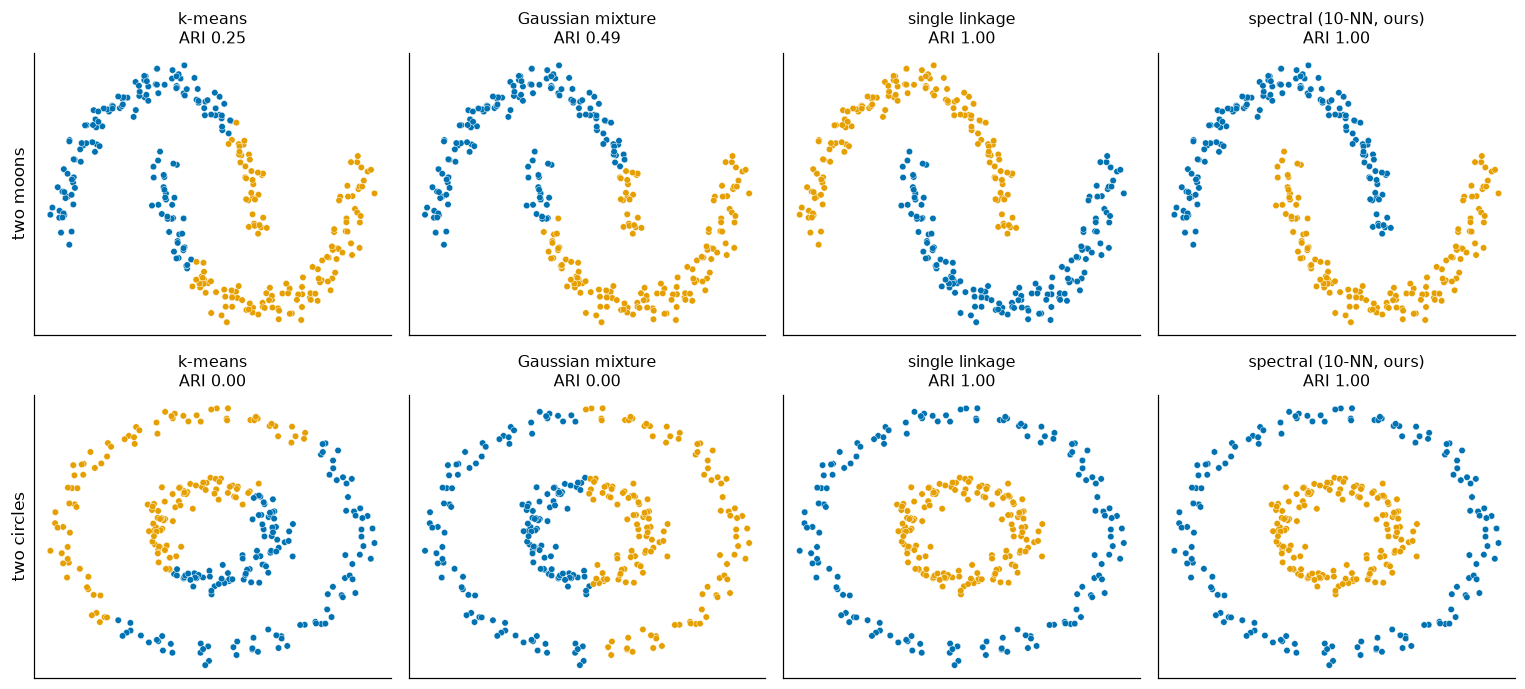

In [29]:
def figure_12_11():
    names = ["k-means", "Gaussian mixture", "single linkage", "spectral (10-NN, ours)"]
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
    for r, (sh, (X, y)) in enumerate(shapes.items()):
        for c, m in enumerate(names):
            ax = axes[r, c]
            lab = shape_labels[sh][m]
            ax.scatter(X[:, 0], X[:, 1], c=[CLUSTER_COLORS[a] for a in lab], marker="o", s=18, edgecolor="white", linewidth=0.3)
            ax.set_title(f"{m}\nARI {table.loc[m, sh] + 0.0:.2f}".replace("-0.00", "0.00"), fontsize=10.5)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if c == 0:
                ax.set_ylabel(sh)
    fig.tight_layout()
    plt.show()


figure_12_11()

Figure 12.11 shows four of the six methods. In the first two columns the straight boundary of $k$-means and the curved one of the mixture cut the crescents and the circles across; in the last two columns the clusters follow the shapes.

### 12.8.4 Spectral clustering on Digits

On real data the situation is less clear-cut. Figure 12.12 shows, for the $m$-nearest-neighbor graph of Digits, the first $20$ eigenvalues of $\mathbf{L}_{\mathrm{sym}}$ (the eigengap heuristic), the examples in the plane of the second and third eigenvectors of the random-walk Laplacian, and the dependence of the result on $m$ and on the variant of the algorithm, with the other clustering methods of the chapter as baselines.

In [30]:
rows = []
t0 = time.perf_counter()
for m in [5, 7, 10, 15, 20, 30, 50]:
    W = knn_similarity(X_dig, m)
    n_comp = csg.connected_components(sp.csr_matrix(W), directed=False)[0]
    row = {"m (neighbors)": m, "components": n_comp}
    for variant in ["rw", "njw"]:
        lab, _ = spectral_clustering(W, 10, variant)
        row[f"ARI {variant}"] = adjusted_rand_score(y_dig, lab)
    rows.append(row)
spec_m = pd.DataFrame(rows)
print(spec_m.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
base = {"k-means": adjusted_rand_score(y_dig, KMeans(10, n_init=10, random_state=SEED).fit_predict(X_dig)),
        "Ward": adjusted_rand_score(y_dig, AgglomerativeClustering(10).fit_predict(X_dig)),
        "Gaussian mixture, diagonal": adjusted_rand_score(y_dig, GaussianMixture(10, covariance_type="diag", reg_covar=1e-2, n_init=3, random_state=SEED).fit_predict(X_dig))}
print("baselines, ARI with the digits:", ", ".join(f"{k} {v:.3f}" for k, v in base.items()))
gaps = np.diff(ev_dig[:20])
print(f"eigenvalues of L_sym (10-NN graph): {np.round(ev_dig[:14], 4).tolist()}")
print(f"largest gaps among the first 20: after eigenvalue {int(np.argsort(-gaps)[0]) + 1} ({gaps.max():.4f}) and {int(np.argsort(-gaps)[1]) + 1} ({np.sort(gaps)[-2]:.4f}); gap after the 10th: {gaps[9]:.4f}")
print(f"[{time.perf_counter() - t0:.1f} s]")

 m (neighbors)  components  ARI rw  ARI njw
             5           2   0.769    0.775
             7           1   0.757    0.825
            10           1   0.757    0.819
            15           1   0.735    0.746
            20           1   0.733    0.739
            30           1   0.741    0.782
            50           1   0.718    0.739
baselines, ARI with the digits: k-means 0.667, Ward 0.794, Gaussian mixture, diagonal 0.676
eigenvalues of L_sym (10-NN graph): [0.0, 0.0028, 0.006, 0.008, 0.0092, 0.0121, 0.0127, 0.0184, 0.0207, 0.0336, 0.0372, 0.0548, 0.0643, 0.0715]
largest gaps among the first 20: after eigenvalue 11 (0.0176) and 9 (0.0129); gap after the 10th: 0.0036
[8.9 s]


Spectral clustering beats $k$-means ($0.667$) at every $m$ tried, by $0.05$ to $0.16$ of ARI, but the comparison with the other baselines is less favorable. Ward's method on the raw pixels reaches $0.794$, and only the Ng–Jordan–Weiss variant with $m=7$ and $m=10$ exceeds it ($0.825$ and $0.819$, by $0.03$ at most). The Shi–Malik variant is below Ward for all $m$ ($0.719$ to $0.769$). The dependence on the graph is not small and not monotone: the NJW score varies between $0.739$ and $0.825$ over the values of $m$, a spread as large as the difference between spectral clustering and Ward's method, so a comparison of methods made with one value of $m$ would be arbitrary. The cost is also larger: every value of $m$ needs the eigendecomposition of a $1797\times1797$ matrix, whereas $k$-means on the pixels takes a fraction of a second.

The eigengap heuristic does not find the ten digits. The eigenvalues grow from $0$ with the largest gaps after the ninth ($0.0128$) and the eleventh ($0.0176$) eigenvalue, and the gap after the tenth is only $0.0035$: the graph suggests nine or eleven groups, in line with the criteria of Section 12.5. A clustering does not discover the number of classes of a labeled data set, because the labels are not the only structure of the data.

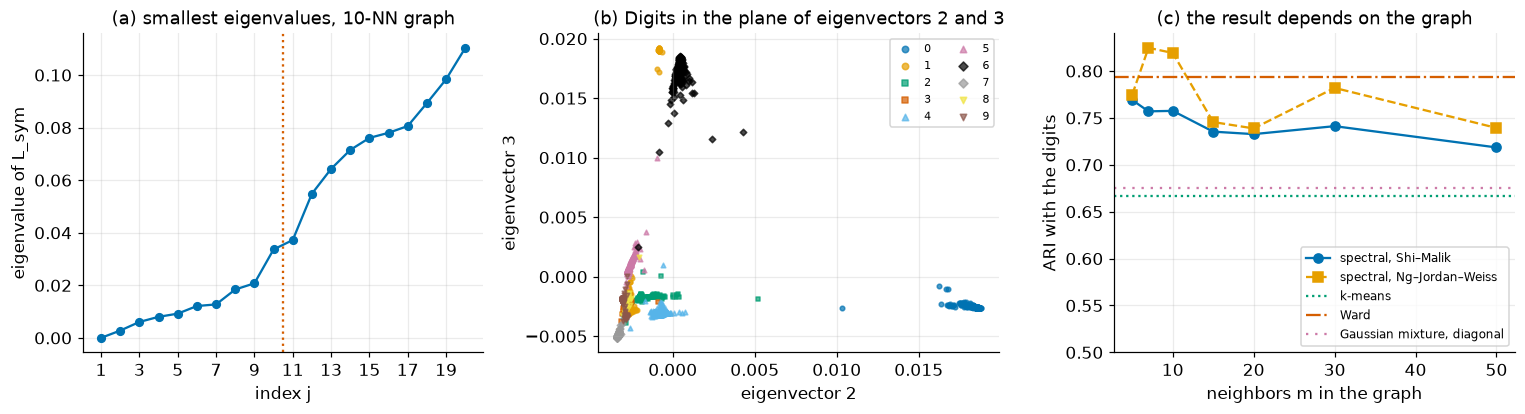

In [31]:
def figure_12_12():
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
    ax = axes[0]
    ax.plot(np.arange(1, 21), ev_dig[:20], "o-", color=BLUE, markersize=5)
    ax.axvline(10.5, color=VERMILION, linestyle=":", linewidth=1.5)
    ax.set(xlabel="index j", ylabel="eigenvalue of L_sym", title="(a) smallest eigenvalues, 10-NN graph")
    ax.set_xticks(range(1, 21, 2))
    ax = axes[1]
    V, _ = spectral_embedding(W_dig, 10, "rw")
    for d in range(10):
        m = y_dig == d
        ax.scatter(V[m, 1], V[m, 2], s=9, color=CLUSTER_COLORS[d % 10], marker=["o", "s", "^", "D", "v"][d // 2 % 5], alpha=0.7, label=str(d))
    ax.set(xlabel="eigenvector 2", ylabel="eigenvector 3", title="(b) Digits in the plane of eigenvectors 2 and 3")
    ax.legend(ncol=2, fontsize=7, markerscale=1.4, loc="best")
    ax = axes[2]
    ax.plot(spec_m["m (neighbors)"], spec_m["ARI rw"], "o-", color=BLUE, label="spectral, Shi–Malik")
    ax.plot(spec_m["m (neighbors)"], spec_m["ARI njw"], "s--", color=ORANGE, label="spectral, Ng–Jordan–Weiss")
    for (name, v), ls, col in zip(base.items(), [":", "-.", (0, (1, 3))], [GREEN, VERMILION, PURPLE]):
        ax.axhline(v, linestyle=ls, color=col, label=name)
    ax.set(xlabel="neighbors m in the graph", ylabel="ARI with the digits", title="(c) the result depends on the graph")
    ax.set_ylim(0.50, 0.84)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_12_12()

In (a) the eigenvalues increase gradually, without a clear step at the tenth. In (b), where each point is an image placed by two coordinates of its spectral embedding, the zeros (on the right), the sixes and the ones (at the top) are far from the rest, and most of the other digits are crowded in a small region at the lower left: the first nontrivial eigenvectors single out the groups that are most separated in the graph and the others emerge in the following eigenvectors. In (c) the lines are the baselines and the markers the two spectral variants; the dependence on $m$ is visible, and so is the fact that the best spectral values are close to the line of Ward's method.

Two practical limits of spectral clustering should be added. The first is cost: the dense eigendecomposition used here is $O(n^3)$, and for large $n$ one computes only the $k$ smallest eigenvectors of the sparse Laplacian with Lanczos-type methods (which is what scikit-learn does for large graphs), at a cost that is roughly linear in the number of edges for each eigenvector. The second is that the method gives labels only to the vertices of the graph: there is no centroid and no decision function, so a new example has to be handled by an out-of-sample extension (the Nyström formula of Bengio and colleagues, 2004, or the nearest labeled neighbors in the graph), whereas $k$-means and the mixtures classify a new point with one comparison to the $k$ centers. Spectral clustering is also related to $k$-means in a way that links this chapter to Chapters 9 and 13: the $k$-means objective (12.3) can be written with the Gram matrix of a kernel (Exercise 12.2), and the eigenvectors of a normalized kernel matrix are what spectral clustering and kernel PCA compute.

## 12.9 Clusters, labels and semi-supervised learning

### 12.9.1 Three settings, three assumptions

In the supervised problems of Chapters 4 to 11 every training example has a label; in clustering none has. Between them lies the situation that is most common in practice: **semi-supervised learning**, with $l$ labeled examples $(\mathbf{x}_i,y_i)$ and $u\gg l$ unlabeled examples $\mathbf{x}_{l+1},\dots,\mathbf{x}_{l+u}$, because labels cost an expert's time and inputs cost nothing. What can the unlabeled examples tell us? They reveal where the inputs are, the density $p(\mathbf{x})$, and the density says something about $p(y\mid\mathbf{x})$ only if the two are linked by an assumption (Chapelle, Schölkopf and Zien, 2006):

- the **smoothness** assumption: two examples that are close in a *high-density* region have the same label;
- the **cluster** assumption: the examples of one cluster tend to share a label, equivalently the decision boundary should pass through low-density regions;
- the **manifold** assumption: the data lie near a low-dimensional surface, and distances should be measured along it (that is what the nearest-neighbor graph of Section 12.8 does).

These are inductive biases in the sense of Chapter 3, and the No Free Lunch theorem (Theorem 3.8) applies: no semi-supervised method can be better than supervised learning for all problems. When the assumption fails, unlabeled data can *hurt* (Cozman, Cohen and Cirelo, 2003), and we shall see an example on real data.

**Protocol.** Digits keeps the split of Chapters 6 to 11 ($1347$ training and $450$ test examples, stratified, `random_state=SEED`). From the training examples we choose $m$ labeled examples per class at random, $m\in\{1,2,5,10,20,50\}$ (so $10$ to $500$ labels); the other training examples are used with their labels *hidden*; the test accuracy is computed on the $450$ test examples. Each choice is repeated $30$ times with different random labeled sets (the same sets for all the methods), and we report the mean and the standard error of the mean. The hyperparameters of the semi-supervised methods are **fixed in advance** and not tuned, because with ten labeled examples there is nothing to tune them on.

### 12.9.2 Propagating labels on a graph

Proposition 12.15(a) says that $\mathbf{f}^\top\mathbf{L}\mathbf{f}$ measures how much a function $\mathbf{f}$ on the examples varies between similar examples. A natural semi-supervised rule is therefore to look for the **smoothest function that agrees with the known labels**.

:::{admonition} Proposition 12.17 (the harmonic solution; Zhu, Ghahramani and Lafferty, 2003)
:class: tip
Let the vertices be ordered so that the first $l$ are labeled, with values $\mathbf{f}_l$ (for two classes the labels $0$ and $1$), and write $\mathbf{L}$, $\mathbf{W}$ in blocks. Assume every connected component of the graph contains a labeled vertex. Then the minimizer of $\mathbf{f}^\top\mathbf{L}\mathbf{f}=\frac12\sum_{i,j}w_{ij}(f_i-f_j)^2$ over the vectors with the prescribed values on the labeled vertices is unique and is
$$
\mathbf{f}_u=\mathbf{L}_{uu}^{-1}\mathbf{W}_{ul}\,\mathbf{f}_l=(\mathbf{D}_{uu}-\mathbf{W}_{uu})^{-1}\mathbf{W}_{ul}\,\mathbf{f}_l .\tag{12.6}
$$
It is **harmonic**: $f_i=\frac1{d_i}\sum_jw_{ij}f_j$ for every unlabeled vertex, so that the value at a vertex is the weighted average of the values of its neighbors.
:::

*Proof.* With $\mathbf{f}=(\mathbf{f}_l,\mathbf{f}_u)$, $\mathbf{f}^\top\mathbf{L}\mathbf{f}=\mathbf{f}_l^\top\mathbf{L}_{ll}\mathbf{f}_l+2\mathbf{f}_u^\top\mathbf{L}_{ul}\mathbf{f}_l+\mathbf{f}_u^\top\mathbf{L}_{uu}\mathbf{f}_u$, a quadratic function of $\mathbf{f}_u$ with gradient $2(\mathbf{L}_{ul}\mathbf{f}_l+\mathbf{L}_{uu}\mathbf{f}_u)$. Since $\mathbf{L}_{ul}=-\mathbf{W}_{ul}$ the gradient vanishes at (12.6). The matrix $\mathbf{L}_{uu}$ is positive definite: for $\mathbf{g}\neq\mathbf{0}$, $\mathbf{g}^\top\mathbf{L}_{uu}\mathbf{g}=\mathbf{f}^\top\mathbf{L}\mathbf{f}$ with $\mathbf{f}=(\mathbf{0},\mathbf{g})$, which is $0$ only if $\mathbf{f}$ is constant on every connected component, and then $\mathbf{g}=\mathbf{0}$ because every component contains a labeled vertex where $\mathbf{f}=\mathbf{0}$. The harmonic property is the $i$-th row of $\mathbf{L}_{uu}\mathbf{f}_u=\mathbf{W}_{ul}\mathbf{f}_l$. $\blacksquare$

For $K$ classes one solves (12.6) with the one-hot label matrix in place of $\mathbf{f}_l$, one column per class, and predicts the class of largest score. The solution has a probabilistic meaning that is proved in Exercise 12.5: the score of class $c$ at vertex $i$ is the probability that a random walk that starts at $i$ and moves to a neighbor with probability proportional to $w_{ij}$ reaches a labeled vertex of class $c$ before any other labeled vertex. A close relative is the **label spreading** of Zhou et al. (2004), which iterates $\mathbf{F}\leftarrow\alpha\,\mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2}\mathbf{F}+(1-\alpha)\mathbf{Y}$ and does not clamp the labeled vertices (the given labels may be noisy); scikit-learn provides it as `LabelSpreading`. New examples (the test set) are classified by the average score of their $m$ nearest training examples.

We implement (12.6), check it against scikit-learn's `LabelPropagation` run with our graph, and then compare six methods on Digits: logistic regression on the labeled examples only, $1$-NN on the labeled examples only, **cluster-then-label** ($k$-means with $10$ or $50$ clusters on all the training inputs, each cluster labeled by the majority of its labeled members, and by the label of the nearest labeled cluster if it has none; a test example takes the label of its nearest centroid), **self-training** (fit the logistic regression on the labeled examples, add the unlabeled examples that it classifies with confidence at least $0.9$ with their predicted labels, and repeat), label spreading ($m=10$ neighbors, $\alpha=0.2$) and the harmonic solution (12.6) on the symmetric $10$-nearest-neighbor graph.

In [32]:
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_dig, y_dig, test_size=0.25, random_state=SEED, stratify=y_dig)
print(f"Digits split: {len(Xg_tr)} training and {len(Xg_te)} test examples")


def harmonic_propagation(W, lab_idx, y_lab, n_classes):
    """Equation (12.6) with one column per class (a tiny ridge keeps components without labels from making the system singular)."""
    n = len(W)
    unl = np.setdiff1d(np.arange(n), lab_idx)
    d = W.sum(axis=1)
    Y_l = np.eye(n_classes)[y_lab]
    F = np.zeros((n, n_classes))
    F[lab_idx] = Y_l
    F[unl] = np.linalg.solve(np.diag(d[unl]) - W[np.ix_(unl, unl)] + 1e-9 * np.eye(len(unl)), W[np.ix_(unl, lab_idx)] @ Y_l)
    return F


def harmonic_predict(F, X_train, X_new, m=10):
    """New examples: sum of the class scores of the m nearest training examples."""
    idx = KNeighborsClassifier(n_neighbors=m).fit(X_train, np.zeros(len(X_train))).kneighbors(X_new, return_distance=False)
    return F[idx].sum(axis=1).argmax(axis=1)


W_tr = knn_similarity(Xg_tr, 10)
rng = np.random.default_rng(SEED)
lab_idx = np.concatenate([rng.choice(np.where(yg_tr == c)[0], 5, replace=False) for c in range(10)])
unl_idx = np.setdiff1d(np.arange(len(Xg_tr)), lab_idx)
F = harmonic_propagation(W_tr, lab_idx, yg_tr[lab_idx], 10)
d_tr = W_tr.sum(axis=1)
print(f"harmonic property: largest |f_i - sum_j w_ij f_j / d_i| over the unlabeled examples = {np.abs(F[unl_idx] - (W_tr @ F)[unl_idx] / d_tr[unl_idx, None]).max():.1e}")
y_semi = -np.ones(len(Xg_tr), int)
y_semi[lab_idx] = yg_tr[lab_idx]
Xi = np.arange(len(Xg_tr))[:, None].astype(float)
lp = LabelPropagation(kernel=lambda a, b: W_tr[np.ix_(a.ravel().astype(int), b.ravel().astype(int))], max_iter=100000, tol=1e-10).fit(Xi, y_semi)
print(f"scikit-learn LabelPropagation on the same graph: largest difference of the scores {np.abs(lp.label_distributions_[unl_idx] - F[unl_idx]).max():.1e};"
      f" same predictions: {bool((lp.transduction_[unl_idx] == F[unl_idx].argmax(1)).all())}")
print(f"50 labels: accuracy on the {len(unl_idx)} unlabeled training examples {np.mean(F[unl_idx].argmax(1) == yg_tr[unl_idx]):.3f}, "
      f"on the test examples {np.mean(harmonic_predict(F, Xg_tr, Xg_te) == yg_te):.3f}")

Digits split: 1347 training and 450 test examples
harmonic property: largest |f_i - sum_j w_ij f_j / d_i| over the unlabeled examples = 9.6e-11


scikit-learn LabelPropagation on the same graph: largest difference of the scores 2.7e-09; same predictions: True
50 labels: accuracy on the 1297 unlabeled training examples 0.941, on the test examples 0.911


The solution (12.6) behaves as Proposition 12.17 says: the residual of the harmonic property over the unlabeled training examples is $10^{-10}$ (the tiny ridge of $10^{-9}$ in the code only matters for graphs with a component that has no label), and scikit-learn's `LabelPropagation`, fed with our graph through a callable kernel, gives scores that differ from ours by $3\times10^{-9}$ and the same predictions for every unlabeled example. With $50$ labels ($5$ per class) the harmonic solution classifies $94.1\%$ of the $1297$ unlabeled training examples correctly, and $91.1\%$ of the test examples, which are not vertices of the graph and are classified by the rule of the $10$ nearest training examples; the difference between the two figures comes partly from that out-of-sample step and partly from the sample (this is a single labeled set, whose variability is measured below).

In [33]:
def cluster_then_label(km, idx, y_lab, X_new):
    k = km.n_clusters
    lab = -np.ones(k, int)
    for c in range(k):
        m = km.labels_[idx] == c
        if m.any():
            lab[c] = np.bincount(y_lab[m], minlength=10).argmax()
    known = np.where(lab >= 0)[0]
    for c in np.where(lab < 0)[0]:
        lab[c] = lab[known[((km.cluster_centers_[known] - km.cluster_centers_[c]) ** 2).sum(1).argmin()]]
    return lab[km.predict(X_new)]


def semi_supervised_experiment(Xtr, ytr, Xte, yte, per_class_list, reps=30, extra=False):
    K = len(np.unique(ytr))
    W = knn_similarity(Xtr, 10)
    km_cache = {(kc, r): KMeans(kc, n_init=3, random_state=r).fit(Xtr) for kc in (10, 50) for r in range(reps)} if extra else {}
    rows = []
    warnings.simplefilter("ignore", RuntimeWarning)       # LabelSpreading divides 0 by 0 for examples that no label can reach (see below)
    for per in per_class_list:
        for r in range(reps):
            rng = np.random.default_rng([SEED, per, r])
            idx = np.concatenate([rng.choice(np.where(ytr == c)[0], per, replace=False) for c in range(K)])
            ys = -np.ones(len(ytr), int)
            ys[idx] = ytr[idx]
            acc = {"logistic (labeled only)": LogisticRegression(C=1, max_iter=2000).fit(Xtr[idx], ytr[idx]).score(Xte, yte),
                   "1-NN (labeled only)": KNeighborsClassifier(1).fit(Xtr[idx], ytr[idx]).score(Xte, yte),
                   "label spreading": LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2, max_iter=1000).fit(Xtr, ys).score(Xte, yte),
                   "harmonic (12.6)": np.mean(harmonic_predict(harmonic_propagation(W, idx, ytr[idx], K), Xtr, Xte) == yte)}
            if extra:
                for kc in (10, 50):
                    acc[f"cluster-then-label, k = {kc}"] = np.mean(cluster_then_label(km_cache[(kc, r)], idx, ytr[idx], Xte) == yte)
                acc["self-training (logistic)"] = SelfTrainingClassifier(LogisticRegression(C=1, max_iter=2000), threshold=0.9).fit(Xtr, ys).score(Xte, yte)
            rows += [{"labels per class": per, "rep": r, "method": k, "accuracy": v} for k, v in acc.items()]
    return pd.DataFrame(rows)


def summarize(df):
    g = df.groupby(["method", "labels per class"])["accuracy"]
    mean = g.mean().unstack()
    se = g.std(ddof=1).unstack() / np.sqrt(df["rep"].nunique())
    return mean, se


t0 = time.perf_counter()
semi_dig = semi_supervised_experiment(Xg_tr, yg_tr, Xg_te, yg_te, [1, 2, 5, 10, 20, 50], extra=True)
order = ["logistic (labeled only)", "1-NN (labeled only)", "cluster-then-label, k = 10", "cluster-then-label, k = 50", "self-training (logistic)", "label spreading", "harmonic (12.6)"]
mean_d, se_d = summarize(semi_dig)
print("Digits: test accuracy, mean (standard error) over 30 random labeled sets; columns = labeled examples per class")
print(pd.DataFrame({m: {f"{c} ({10 * c} labels)": f"{mean_d.loc[m, c]:.3f} ({se_d.loc[m, c]:.3f})" for c in mean_d.columns} for m in order}).T.to_string())
print(f"[{time.perf_counter() - t0:.1f} s]")

Digits: test accuracy, mean (standard error) over 30 random labeled sets; columns = labeled examples per class
                            1 (10 labels)  2 (20 labels)  5 (50 labels) 10 (100 labels) 20 (200 labels) 50 (500 labels)
logistic (labeled only)     0.650 (0.010)  0.755 (0.006)  0.852 (0.005)   0.896 (0.003)   0.923 (0.002)   0.948 (0.001)
1-NN (labeled only)         0.649 (0.010)  0.750 (0.007)  0.858 (0.005)   0.914 (0.003)   0.949 (0.002)   0.974 (0.001)
cluster-then-label, k = 10  0.639 (0.017)  0.715 (0.010)  0.746 (0.005)   0.756 (0.005)   0.758 (0.005)   0.760 (0.005)
cluster-then-label, k = 50  0.759 (0.012)  0.827 (0.008)  0.894 (0.005)   0.909 (0.003)   0.922 (0.003)   0.934 (0.002)
self-training (logistic)    0.650 (0.010)  0.755 (0.006)  0.843 (0.006)   0.865 (0.003)   0.913 (0.002)   0.945 (0.001)
label spreading             0.804 (0.010)  0.881 (0.006)  0.928 (0.005)   0.949 (0.004)   0.964 (0.002)   0.976 (0.000)
harmonic (12.6)             0.821 (0.010)  0.883 

The graph methods dominate when labels are scarce. With *one* label per class, ten labels in all, the harmonic solution reaches $0.821$ and label spreading $0.806$, against $0.650$ for the logistic regression and $0.649$ for $1$-NN, which have only the ten labeled images to learn from: the unlabeled images contribute $16$ to $17$ points of accuracy. The gain decreases as the labels increase, as it must (with all the labels there is nothing left to learn from the unlabeled examples): label spreading beats logistic regression by $0.053$ with $10$ labels per class and by $0.028$ with $50$, and at $50$ labels per class it is equal to $1$-NN on the labeled examples alone ($0.976$ against $0.974$, a difference of the order of two standard errors, which says only that the labeled examples are now numerous enough for the plain rule).

The other three methods show how the *assumption* enters. Cluster-then-label with $k=10$ plateaus at $0.76$ from five labels per class on (the standard error of each mean is $0.005$): its predictor is constant on ten clusters, and the clusters are not the digits (their ARI with the digits is $0.667$, Section 12.5), so that no number of labels can make it better than the purity of the clusters; this is the bias of a model that is too coarse, as in Chapter 4. With $k=50$ clusters the bias drops and the method beats both supervised baselines up to five labels per class ($0.894$ against $0.852$ and $0.858$), but it never reaches the graph methods, and from $10$ labels per class on it is below $1$-NN ($0.909$ against $0.914$, and $0.922$ against $0.949$ with $20$). Self-training does not help: it is identical to the plain logistic regression at one and two labels per class and *worse* from five labels on, by $0.009$, $0.031$ and $0.010$ at $5$, $10$ and $20$ per class. It adds the unlabeled examples on which the model is already confident; they are almost always labeled correctly, but they are the examples that the model classifies correctly anyway, and they come mostly from the classes that it already separates well, so that the labeled set grows unbalanced (Exercise 12.10). Last caution: the standard errors measure the variation over the $30$ labeled sets; the test set of $450$ images is the same for all the methods and has its own sampling error (about $0.01$ for an accuracy of $0.95$), so differences of that size between two methods should not be over-interpreted.

### 12.9.3 When unlabeled data do not help

The same comparison on two other data sets shows the role of the assumption. We standardize with the mean and standard deviation of the training inputs (labeled and unlabeled, which is allowed because no label is used) and use the stratified $75\%/25\%$ split of the earlier chapters (`random_state=SEED`).

In [34]:
semi_other, splits = {}, {}
t0 = time.perf_counter()
for name, X_all, y_all, per_list in [("Wine", wine.data, y_wine, [1, 2, 5, 10, 20]), ("Breast Cancer", bc.data, y_bc, [1, 2, 5, 10, 20])]:
    Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=0.25, random_state=SEED, stratify=y_all)
    sc = StandardScaler().fit(Xa)
    splits[name] = (sc.transform(Xa), ya, sc.transform(Xb), yb)
    semi_other[name] = semi_supervised_experiment(*splits[name][:2], *splits[name][2:], per_list)
    mean_o, se_o = summarize(semi_other[name])
    print(f"\n{name} ({len(Xa)}/{len(Xb)} examples): test accuracy, mean (standard error) over 30 random labeled sets")
    print(pd.DataFrame({m: {f"{c} per class": f"{mean_o.loc[m, c]:.3f} ({se_o.loc[m, c]:.3f})" for c in mean_o.columns} for m in mean_o.index}).T.to_string())

# What goes wrong on Breast Cancer with one or two labels per class
Xs, ys_, Xt, yt_ = splits["Breast Cancer"]
W_b = knn_similarity(Xs, 10)
ei, ej = np.where(np.triu(W_b))
print(f"\nBreast Cancer: malignant share of the training examples {ys_.mean():.1%}; {np.mean(ys_[ei] != ys_[ej]):.1%} of the {len(ei)} edges of the 10-NN graph join a malignant and a benign tumor, "
      f"and {np.mean([(ys_[W_b[i] > 0] != ys_[i]).any() for i in range(len(ys_))]):.1%} of the tumors have a neighbor of the other class")
rng = np.random.default_rng([SEED, 1, 0])
idx0 = np.concatenate([rng.choice(np.where(ys_ == c)[0], 1, replace=False) for c in range(2)])
y_part0 = -np.ones(len(ys_), int)
y_part0[idx0] = ys_[idx0]
ls0 = LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2, max_iter=1000).fit(Xs, y_part0)
print(f"label spreading with one label per class (first labeled set): the iteration stops after {ls0.n_iter_} steps and {int((ls0.label_distributions_.sum(axis=1) == 0).sum())} of the {len(Xs)} training examples have received no label mass")
for per in (1, 2):
    no_score, share_pos = [], []
    for r in range(30):
        rng = np.random.default_rng([SEED, per, r])
        idx = np.concatenate([rng.choice(np.where(ys_ == c)[0], per, replace=False) for c in range(2)])
        y_part = -np.ones(len(ys_), int)
        y_part[idx] = ys_[idx]
        no_score.append(np.isnan(LabelSpreading(kernel="knn", n_neighbors=10, alpha=0.2, max_iter=1000).fit(Xs, y_part).predict_proba(Xt)).any(axis=1).sum())
        F_b = harmonic_propagation(W_b, idx, ys_[idx], 2)
        share_pos.append((F_b[np.setdiff1d(np.arange(len(Xs)), idx)].argmax(axis=1) == 1).mean())
    print(f"  {per} label(s) per class: label spreading gives no score (NaN) to {np.mean(no_score):.1f} of the {len(Xt)} test examples on average (scikit-learn then predicts the first class);"
          f" the harmonic solution calls {np.mean(share_pos):.1%} of the unlabeled examples malignant (sd {np.std(share_pos, ddof=1):.1%})")
print(f"[{time.perf_counter() - t0:.1f} s]")


Wine (133/45 examples): test accuracy, mean (standard error) over 30 random labeled sets
                           1 per class    2 per class    5 per class   10 per class   20 per class
1-NN (labeled only)      0.779 (0.018)  0.870 (0.013)  0.899 (0.008)  0.923 (0.006)  0.922 (0.005)
harmonic (12.6)          0.811 (0.026)  0.944 (0.005)  0.971 (0.003)  0.976 (0.001)  0.977 (0.001)
label spreading          0.841 (0.026)  0.916 (0.021)  0.966 (0.003)  0.974 (0.002)  0.977 (0.001)
logistic (labeled only)  0.792 (0.018)  0.880 (0.010)  0.942 (0.006)  0.962 (0.006)  0.979 (0.003)



Breast Cancer (426/143 examples): test accuracy, mean (standard error) over 30 random labeled sets
                           1 per class    2 per class    5 per class   10 per class   20 per class
1-NN (labeled only)      0.798 (0.031)  0.823 (0.014)  0.900 (0.006)  0.923 (0.005)  0.933 (0.004)
harmonic (12.6)          0.653 (0.038)  0.857 (0.019)  0.935 (0.004)  0.944 (0.002)  0.950 (0.001)
label spreading          0.805 (0.028)  0.809 (0.019)  0.917 (0.008)  0.936 (0.004)  0.949 (0.001)
logistic (labeled only)  0.797 (0.031)  0.857 (0.011)  0.932 (0.004)  0.943 (0.004)  0.963 (0.004)

Breast Cancer: malignant share of the training examples 37.3%; 7.7% of the 3180 edges of the 10-NN graph join a malignant and a benign tumor, and 38.0% of the tumors have a neighbor of the other class
label spreading with one label per class (first labeled set): the iteration stops after 5 steps and 153 of the 426 training examples have received no label mass


  1 label(s) per class: label spreading gives no score (NaN) to 13.9 of the 143 test examples on average (scikit-learn then predicts the first class); the harmonic solution calls 49.6% of the unlabeled examples malignant (sd 37.6%)


  2 label(s) per class: label spreading gives no score (NaN) to 1.6 of the 143 test examples on average (scikit-learn then predicts the first class); the harmonic solution calls 35.4% of the unlabeled examples malignant (sd 17.5%)
[15.9 s]


The result on Digits does not carry over automatically.

**Wine.** The unlabeled wines help when labels are few: with two labels per class the harmonic solution reaches $0.944$ and label spreading $0.916$, against $0.880$ for the logistic regression and $0.870$ for $1$-NN; the advantage is gone at $20$ per class, where all four methods are between $0.922$ and $0.979$ and the logistic regression is nominally the best ($0.979$ against $0.977$). With one label per class the advantage is not established ($0.841$ against $0.792$, but a standard error of $0.026$ for label spreading).

**Breast Cancer.** Here the unlabeled data *do not help*, and for label spreading they hurt: at two labels per class its accuracy is $0.809$ against $0.857$ for the logistic regression (standard errors $0.019$ and $0.011$), and it remains below the logistic regression for every larger number of labels ($0.917$ against $0.932$ with five per class, $0.949$ against $0.963$ with twenty). The harmonic solution equals the logistic regression from two to ten labels per class and is below it at twenty ($0.950$ against $0.963$); with *one* label per class it is catastrophic, $0.653$ against $0.797$. The diagnostic lines explain this case. The two classes are not two clusters separated by a low-density region: $7.7\%$ of the edges of the $10$-nearest-neighbor graph join a malignant and a benign tumor, and $38.0\%$ of the tumors have a neighbor of the other class, so the cluster assumption is weak, and a linear model, whose assumption fits these data (Chapter 6), makes better use of the few labels. With a single labeled tumor per class the harmonic scores are nearly tied across the graph, and the predicted share of malignant tumors depends on which two patients happened to be labeled: on average $49.6\%$ of the unlabeled examples are called malignant, with a standard deviation of $37.6$ points across the $30$ labeled sets, against a true proportion of $37.3\%$ (with two labels per class the standard deviation is $17.5$ points). Label spreading has a different problem: with one label per class it gives no score at all (the scores are not numbers) to $13.9$ of the $143$ test examples on average, those whose nearest training examples had received no label mass: the iteration stops after a few steps (five in the first labeled set) before the labels of two tumors reach $153$ of the $426$ training examples, and scikit-learn then predicts the first class for the test examples that depend on them. These two failures belong to the *method*, not to the data: with more labels both disappear, but the graph methods then remain at best equal to the supervised baseline. Unlabeled data are not a free gift; they are a bet on an assumption.

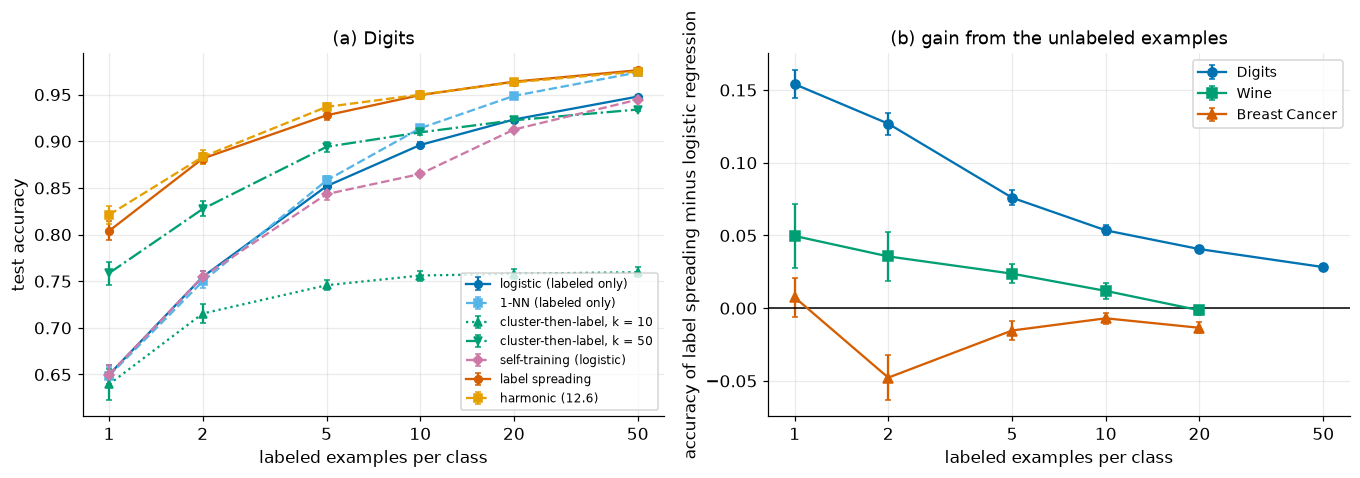

In [35]:
def figure_12_13():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
    ax = axes[0]
    styles = {"logistic (labeled only)": (BLUE, "o", "-"), "1-NN (labeled only)": (SKY, "s", "--"), "cluster-then-label, k = 10": (GREEN, "^", ":"),
              "cluster-then-label, k = 50": (GREEN, "v", "-."), "self-training (logistic)": (PURPLE, "D", "--"), "label spreading": (VERMILION, "o", "-"),
              "harmonic (12.6)": (ORANGE, "s", "--")}
    xs = np.array(mean_d.columns)
    for m in order:
        col, mk, ls = styles[m]
        ax.errorbar(xs, mean_d.loc[m].to_numpy(), yerr=se_d.loc[m].to_numpy(), color=col, marker=mk, linestyle=ls, markersize=5, capsize=2, label=m)
    ax.set_xscale("log")
    ax.set_xticks(xs, [str(v) for v in xs])
    ax.minorticks_off()
    ax.set(xlabel="labeled examples per class", ylabel="test accuracy", title="(a) Digits")
    ax.legend(fontsize=8, loc="lower right")
    ax = axes[1]
    for (name, df), col, mk in zip([("Digits", semi_dig)] + list(semi_other.items()), [BLUE, GREEN, VERMILION], ["o", "s", "^"]):
        piv = df[df["method"].isin(["label spreading", "logistic (labeled only)"])].pivot_table(index=["labels per class", "rep"], columns="method", values="accuracy")
        diff = (piv["label spreading"] - piv["logistic (labeled only)"]).groupby(level=0)
        ax.errorbar(diff.mean().index, diff.mean(), yerr=diff.std(ddof=1) / np.sqrt(30), color=col, marker=mk, capsize=2, label=name)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xscale("log")
    ax.set_xticks([1, 2, 5, 10, 20, 50], ["1", "2", "5", "10", "20", "50"])
    ax.minorticks_off()
    ax.set(xlabel="labeled examples per class", ylabel="accuracy of label spreading minus logistic regression", title="(b) gain from the unlabeled examples")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()


figure_12_13()

Figure 12.13 draws the Digits table (a) and the gain of label spreading over the logistic regression for the three data sets (b). The gain is positive for all label counts on Digits (from about $0.16$ with one label per class to $0.03$ with fifty), positive and decreasing to zero on Wine, and zero or negative on Breast Cancer (an advantage of $0.008$, within the error bar, with one label per class and then $-0.048$, $-0.015$, $-0.007$ and $-0.014$).

### 12.9.4 Clusters as features

A second way to use unlabeled examples is to learn a representation with them. We replace $\mathbf{x}$ by its similarity to $k$ centers fitted by $k$-means *without labels*: the **triangle** encoding of Coates, Lee and Ng (2011) is $f_j(\mathbf{x})=\max\{0,\ \bar d(\mathbf{x})-d_j(\mathbf{x})\}$, with $d_j$ the distance to the $j$-th center and $\bar d$ the mean of the $k$ distances, so that a feature is nonzero only for the centers nearer than average. The features then feed a logistic regression. With *all* the training labels the number of centers $k$ and the penalty $C$ are chosen by $5$-fold cross-validation on the training set (inside the pipeline, so that the centers are refitted in each fold), and the test set is used once. With a few labels, the centers are fitted on all the unlabeled training inputs and the regression on the labeled ones, with $k=100$ and $C=1$ fixed in advance.

In [36]:
class KMeansTriangle(BaseEstimator, TransformerMixin):
    """Triangle encoding of the distances to the centers of a k-means fitted without labels."""

    def __init__(self, k=100, random_state=0):
        self.k, self.random_state = k, random_state

    def fit(self, X, y=None):
        self.km_ = KMeans(self.k, n_init=3, random_state=self.random_state).fit(X)
        return self

    def transform(self, X):
        D = self.km_.transform(X)
        return np.maximum(0, D.mean(axis=1, keepdims=True) - D)


cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
raw_cv = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                      {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=cv5).fit(Xg_tr, yg_tr)
feat_cv = GridSearchCV(make_pipeline(KMeansTriangle(random_state=SEED), StandardScaler(), LogisticRegression(max_iter=3000)),
                       {"kmeanstriangle__k": [10, 50, 100, 300], "logisticregression__C": [0.01, 0.1, 1]}, cv=cv5).fit(Xg_tr, yg_tr)
print(f"all {len(Xg_tr)} training labels:")
print(f"  logistic regression on the pixels:      best C = {raw_cv.best_params_['logisticregression__C']}, CV accuracy {raw_cv.best_score_:.4f}, test accuracy {raw_cv.score(Xg_te, yg_te):.4f}")
print(f"  logistic regression on k-means features: best k = {feat_cv.best_params_['kmeanstriangle__k']}, C = {feat_cv.best_params_['logisticregression__C']}, "
      f"CV accuracy {feat_cv.best_score_:.4f}, test accuracy {feat_cv.score(Xg_te, yg_te):.4f}")

res = {"raw pixels, 100 labels": [], "k-means features (k = 100) from the unlabeled examples, 100 labels": []}
for r in range(30):
    rng = np.random.default_rng([SEED, 10, r])
    idx = np.concatenate([rng.choice(np.where(yg_tr == c)[0], 10, replace=False) for c in range(10)])
    res["raw pixels, 100 labels"].append(LogisticRegression(C=1, max_iter=2000).fit(Xg_tr[idx], yg_tr[idx]).score(Xg_te, yg_te))
    enc = KMeansTriangle(100, random_state=r).fit(Xg_tr)
    res["k-means features (k = 100) from the unlabeled examples, 100 labels"].append(
        make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(enc.transform(Xg_tr[idx]), yg_tr[idx]).score(enc.transform(Xg_te), yg_te))
print("\n10 labels per class, 30 repetitions (test accuracy, mean and standard error):")
for k, v in res.items():
    print(f"  {k}: {np.mean(v):.3f} ({np.std(v, ddof=1) / np.sqrt(len(v)):.3f})")
print(f"[{time.perf_counter() - t0:.1f} s]")

all 1347 training labels:
  logistic regression on the pixels:      best C = 10, CV accuracy 0.9673, test accuracy 0.9644
  logistic regression on k-means features: best k = 300, C = 1, CV accuracy 0.9792, test accuracy 0.9800



10 labels per class, 30 repetitions (test accuracy, mean and standard error):
  raw pixels, 100 labels: 0.896 (0.003)
  k-means features (k = 100) from the unlabeled examples, 100 labels: 0.921 (0.004)
[9.1 s]


With all $1347$ training labels, a logistic regression on the $k$-means features reaches a cross-validated accuracy of $0.9792$ and a test accuracy of $0.9800$ ($9$ errors in $450$), against $0.9673$ and $0.9644$ ($16$ errors) for the logistic regression on the pixels: seven fewer errors, a difference that a test set of $450$ images cannot establish alone, but that the cross-validation, on $1347$ images, supports. The best number of centers is $300$, the largest value of the grid, so a larger value might do better; the point is that the best $k$ is far above the number of classes: as a feature extractor, $k$-means is not asked to find the ten digits but to cover the space of images with enough centers that each image is near a few of them, which is the quantizer of Section 12.6 used as a representation.

With $100$ labels ($10$ per class) and the centers fitted on the unlabeled training images, the logistic regression on the features reaches $0.921$ ($0.004$) against $0.896$ ($0.003$) on the pixels, a gain of $0.025$ from clusters learned without labels. It is a smaller gain than that of label spreading at the same number of labels ($0.949$, Section 12.9.2), so that, in this experiment, the graph method makes the better use of the unlabeled images while the representation has the advantage of producing a fixed feature map that can be applied to new images, to be fed to any classifier.

## 12.10 The methods side by side

We close the chapter with the same table for all the methods and all four data sets, with the number of clusters equal to the number of classes: $3$ for Iris and Wine, $2$ for Breast Cancer, $10$ for Digits. This is a favorable setting, because $k$ is the one quantity that Section 12.5 showed to be hard to find, and the labels are used only to score. The Gaussian mixture uses the covariance structure with the smallest BIC *at that $k$* (a choice made without labels), and the spectral clustering uses the $10$-nearest-neighbor graph and the Shi–Malik variant.

In [37]:
rows, chosen_cov = [], {}
t0 = time.perf_counter()
for name, (X, y) in datasets.items():
    k = len(np.unique(y))
    labs = {"k-means": KMeans(k, n_init=10, random_state=SEED).fit_predict(X),
            "Ward": AgglomerativeClustering(k).fit_predict(X)}
    gms = {cov: GaussianMixture(k, covariance_type=cov, n_init=3, random_state=SEED, reg_covar=1e-2 if name == "Digits" else 1e-6).fit(X) for cov in ["spherical", "diag", "tied", "full"]}
    best_cov = min(gms, key=lambda c: gms[c].bic(X))
    labs["Gaussian mixture (lowest BIC)"] = gms[best_cov].predict(X)
    chosen_cov[name] = best_cov
    labs["spectral (10-NN)"] = spectral_clustering(knn_similarity(X, 10), k, "rw")[0]
    for m, lab in labs.items():
        rows.append({"data": name, "k": k, "method": m, "ARI": adjusted_rand_score(y, lab), "NMI": normalized_mutual_info_score(y, lab),
                     "silhouette": silhouette_score(X, lab) if len(np.unique(lab)) > 1 else np.nan})
side = pd.DataFrame(rows)
print("covariance structure of the mixture with the lowest BIC:", chosen_cov)
print("\nARI with the labels:")
print(side.pivot_table(index="method", columns="data", values="ARI", sort=False)[list(datasets)].to_string(float_format=lambda v: f"{v:.3f}"))
print("\nNMI:")
print(side.pivot_table(index="method", columns="data", values="NMI", sort=False)[list(datasets)].to_string(float_format=lambda v: f"{v:.3f}"))
print("\nsilhouette of the partition:")
print(side.pivot_table(index="method", columns="data", values="silhouette", sort=False)[list(datasets)].to_string(float_format=lambda v: f"{v:.3f}"))
print(f"[{time.perf_counter() - t0:.1f} s]")

covariance structure of the mixture with the lowest BIC: {'Iris': 'full', 'Wine': 'diag', 'Breast Cancer': 'full', 'Digits': 'tied'}

ARI with the labels:
data                           Iris  Wine  Breast Cancer  Digits
method                                                          
k-means                       0.730 0.897          0.654   0.667
Ward                          0.731 0.790          0.575   0.794
Gaussian mixture (lowest BIC) 0.904 0.915          0.774   0.590
spectral (10-NN)              0.745 0.896          0.767   0.757

NMI:
data                           Iris  Wine  Breast Cancer  Digits
method                                                          
k-means                       0.758 0.876          0.532   0.739
Ward                          0.770 0.786          0.457   0.868
Gaussian mixture (lowest BIC) 0.900 0.892          0.661   0.737
spectral (10-NN)              0.778 0.877          0.677   0.854

silhouette of the partition:
data                         

No method wins everywhere. In terms of ARI the mixture is the best on three data sets (Iris $0.904$, Wine $0.915$, Breast Cancer $0.774$) and the worst on the fourth (Digits $0.590$, with the covariance structure selected by the BIC, the tied one); Ward's method is the best on Digits ($0.794$, with the best NMI, $0.868$) and the worst on Wine ($0.790$) and on Breast Cancer ($0.575$); spectral clustering is never far from the best ($0.745$, $0.896$, $0.767$, $0.757$) and never the best. $k$-means is never the best by ARI, but it is within $0.02$ of the best on Wine and within $0.12$ on Breast Cancer and is cheap. The explanations are the ones met in the chapter: the mixture adapts to elongated and unequally sized groups (Iris, Breast Cancer), the compact spherical groups of standardized Wine suit $k$-means, and in Digits the groups are not compact in the pixel space, where $k$-means and the mixture do worse than agglomeration and the graph (a plausible reading, not one that the experiment tests).

The silhouette ranks the methods differently from the ARI. It is practically the same for all methods on a given data set (Iris $0.50$ to $0.55$, Wine $0.28$, Digits $0.17$ to $0.18$), highest for $k$-means on Breast Cancer and Wine (and on Digits, where spectral clustering ties with it), and lowest for the mixture on Iris, Breast Cancer and Digits, simply because $k$-means maximizes a compactness that the silhouette also rewards, and the mixture does not. On Digits $k$-means has the highest silhouette ($0.182$) and one of the lowest ARIs ($0.667$): an internal score measures the fit to a geometric ideal, and the agreement with the labels is another matter. Each number comes from a single run with a fixed seed, so differences of a few hundredths should not be interpreted; the differences between methods that are decisive here, such as $0.59$ against $0.79$ on Digits, are larger than that.

## 12.11 Summary

- **The problem (Section 12.2).** Clustering minimizes the within-cluster scatter $\mathrm{SS}_W$ over partitions, a set of size $S(n,k)$ ($6.2\times10^{70}$ for the $150$ flowers and $k=3$). $\mathrm{SS}_W$ has a centroid and a pairwise form (Proposition 12.1, identical to $10^{-14}$), $\mathrm{SS}_T=\mathrm{SS}_W+\mathrm{SS}_B$, and merging two clusters raises the scatter by $\frac{n_An_B}{n_A+n_B}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2$ (equation (12.2), the gain of a split in a regression tree). The problem is NP-hard. On Iris the species explain $86.9\%$ of the scatter, and the best three clusters, with $\mathrm{SS}_W=78.85$, explain more than the species ($89.30$).
- **$k$-means (Section 12.3).** Lloyd's algorithm alternates two exact optimizations, decreases $J$ at every step and stops in finitely many steps at a fixed point, which is a local minimum (Theorem 12.4), reproduced by scikit-learn to $10^{-15}$. Fixed points can be improved by single moves (Hartigan), by about one part in $10^5$ on Digits, a small amount next to the spread between local minima: the best value found is $0.9\%$ to $6\%$ below the values reached by three single random starts. $k$-means++ more than halves the failures of uniform seeding on Iris ($19$ bad runs in $200$ against $49$) and is better on Digits ($37\%$ of the runs at the best value against $21\%$), but not on Wine; the number of starts matters as much as the seeding. The scale of the features is part of the model: on Wine the ARI is $0.371$ for the raw features and $0.897$ for the standardized ones.
- **Evaluation (Section 12.4).** The silhouette compares cohesion and separation ($0.681$ for $k=2$ on Iris, $0.553$ for $k=3$); the adjusted Rand index counts pairs, does not depend on the names of the clusters, and has expectation zero under random labels (to $10^{-4}$ for $3$ to $200$ groups on Digits), while the NMI of random labels grows to $0.15$.
- **How many clusters (Section 12.5).** $J^\ast(k)$ decreases with $k$ (Proposition 12.8) and so does the held-out distortion (from $4.214$ to $1.380$ for $k=2$ to $400$). The four criteria agree on Wine ($k=3$, apart from the gap rule, which gives $4$) and disagree elsewhere: Iris gets $2$ from the silhouette and the stability, $3$ from the species, nothing from the gap rule; on Digits the silhouette and the stability peak at $9$, the best ARI is at $11$ and nothing points at $10$.
- **Quantization (Section 12.6).** $k$-means designs a vector quantizer, whose distortion falls with slope $-2/p$ in $\log k$ (Theorem 12.9). On the photograph a codebook of $16$ colors gives $27.4$ dB at $6:1$ compression, and the mean squared error of the codebook is $12$ to $16$ times smaller than that of the uniform grid with $8$ to $216$ colors; the slope gives an effective dimension of $2.7$ for pixels in $3$ dimensions, and $6.3$ for Digits (to be read with the caveats of Section 12.6.3).
- **Mixtures (Section 12.7.1).** EM alternates responsibilities and weighted Gaussian fits and never decreases the likelihood (Theorem 12.11); $k$-means is its limit for equal spherical components of vanishing variance (Proposition 12.12). The likelihood is unbounded (the spike of a component on one flower takes it past the sensible fit at a variance between $10^{-32}$ and $10^{-48}$). On Iris the full-covariance mixture has ARI $0.904$ against $0.730$ for $k$-means; the BIC picks $2$ components for Iris and $4$ diagonal components for Wine (ARI $0.683$), not the species.
- **Hierarchical clustering (Section 12.7.2).** Ward's merge cost is the increase of the $k$-means objective (Proposition 12.13, heights agreeing to $10^{-14}$) and its cuts are within $0.6\%$ to $2.8\%$ of the $k$-means value on Iris; single linkage is the minimum spanning tree with the heaviest edges removed (Proposition 12.14) and chains: on Wine it gives clusters of $174$, $3$ and $1$ wines.
- **Spectral clustering (Section 12.8).** The Laplacian satisfies $\mathbf{f}^\top\mathbf{L}\mathbf{f}=\frac12\sum w_{ij}(f_i-f_j)^2$; the multiplicity of the eigenvalue $0$ is the number of connected components (Proposition 12.15, confirmed on six graphs); RatioCut and Ncut relax to eigenvectors of $\mathbf{L}$ and $\mathbf{L}_{\mathrm{rw}}$ (Proposition 12.16, with $\lambda_2\le\mathrm{RatioCut}$). On two moons and two circles $k$-means and the mixture fail (ARI $0.247$, $0.488$ and $0$) and single linkage, DBSCAN and spectral clustering recover both groupings exactly. On Digits spectral clustering reaches an ARI of $0.72$ to $0.83$ depending on the graph and the variant, against $0.667$ for $k$-means and $0.794$ for Ward; the eigengap suggests $9$ or $11$ clusters.
- **Semi-supervised learning (Section 12.9).** The harmonic solution $\mathbf{L}_{uu}^{-1}\mathbf{W}_{ul}\mathbf{f}_l$ (Proposition 12.17, equal to scikit-learn's `LabelPropagation` to $10^{-9}$) lifts the accuracy on Digits from $0.650$ to $0.821$ with ten labels, a gain that shrinks to $0.03$ with $500$; it is useful on Wine with two labels per class and *harmful* on Breast Cancer ($0.809$ for label spreading against $0.857$ for the logistic regression with two labels per class; $0.653$ for the harmonic solution with one), because its assumption does not hold there. Self-training gains nothing or loses, although its pseudo-labels are almost all correct, and cluster-then-label with $k=10$ plateaus at $0.76$. Clusters as features ($k=300$ centers, triangle encoding) improve the logistic regression on Digits from $0.964$ to $0.980$ with all labels and from $0.896$ to $0.921$ with $100$.
- **The methods side by side (Section 12.10).** With $k$ equal to the number of classes the ARI is best for the mixture on Iris ($0.904$), Wine ($0.915$) and Breast Cancer ($0.774$) and for Ward on Digits ($0.794$); no method wins everywhere, and the internal silhouette does not follow the ARI.

:::{admonition} Which tool for which situation
:class: tip
| situation | start with | reason |
|---|---|---|
| compact, roughly round groups of similar size; features on one scale | $k$-means with $k$-means++ seeding and several starts, features standardized | cheap, simple; the result depends on the scale and the start (Sections 12.3.4 and 12.3.5) |
| elongated or unequal groups; a probability of belonging is needed | Gaussian mixture with BIC to choose the covariance structure and $k$ | soft assignments and a likelihood; the BIC answers a density question (Section 12.7.1) |
| a hierarchy, or nothing is known about $k$ | Ward's agglomeration and a dendrogram | all the scales at once; avoid single and average linkage with outliers (Section 12.7.2) |
| groups of arbitrary shape, connected by chains of near points | spectral clustering on a nearest-neighbor graph, or DBSCAN | connectivity instead of distance to a center; the graph needs choices (Sections 12.8.3 and 12.8.4) |
| compressing vectors or images; a data-driven codebook | $k$-means as a vector quantizer, $k$ from the rate | optimal quantizer for the empirical distribution (Section 12.6) |
| few labels and many unlabeled examples | label spreading or the harmonic solution, if the classes form clusters; a supervised baseline always | gains of $16$ points with ten labels on Digits, losses on Breast Cancer (Section 12.9) |
| the number of clusters | several criteria, the partitions themselves and the purpose; do not trust one number | the criteria disagree (Section 12.5) |
| scoring against known groups | the ARI, not the NMI with many groups | Section 12.4.2 |
:::


### Data sources

- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn; all $150$ flowers, the four measurements in centimeters (Sections 12.2 to 12.8).
- *Wine*: M. Forina *et al.*, "PARVUS: An Extendible Package for Data Exploration, Classification and Correlation", Institute of Pharmaceutical and Food Analysis and Technologies, Genoa (1991), UCI Machine Learning Repository. Bundled with scikit-learn; all $178$ wines, standardized (Sections 12.3 to 12.10).
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn; malignant $=1$, standardized; for Section 12.9 the stratified $426/143$ split of Chapters 6 to 11.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). Bundled with scikit-learn; all $1797$ images of ten classes, pixels divided by $16$; for Section 12.9 the stratified $1347/450$ split of Chapters 6, 9 and 11.
- *The photograph of Section 12.6.2*: `china.jpg`, distributed with scikit-learn (`sklearn.datasets.load_sample_image`), a photograph of a pagoda by danielbuechele (Flickr), retrieved in 2011 by Robert Layton and released under a Creative Commons Attribution 2.0 license.
- *Constructed data* (flagged in the text): the two interleaved half circles and the two concentric circles of Section 12.8.3 (`make_moons` and `make_circles`, $300$ points each, Gaussian noise of standard deviations $0.06$ and $0.05$, a feature of the experiment and not a property of any real data set); the four points of Exercise 12.1, the contingency tables of Exercise 12.3, the two triangles of Exercise 12.4 and the path graph of Exercise 12.5; and the random partitions and random labels of Sections 12.2 and 12.4 and the uniform reference data of the gap statistic (Section 12.5), which are draws from a random number generator with the fixed seed of the chapter.

### Further reading

- S. P. Lloyd, "Least squares quantization in PCM", *IEEE Transactions on Information Theory* 28(2), 129–137 (1982) (a 1957 report of Bell Labs), and J. Max, "Quantizing for minimum distortion", *IRE Transactions on Information Theory* 6(1), 7–12 (1960). The two optimality conditions and the algorithm (Sections 12.3 and 12.6). Y. Linde, A. Buzo and R. M. Gray, "An algorithm for vector quantizer design", *IEEE Transactions on Communications* 28(1), 84–95 (1980), for the vector case; P. L. Zador, "Asymptotic quantization error of continuous signals and the quantization dimension", *IEEE Transactions on Information Theory* 28(2), 139–149 (1982), for Theorem 12.9.
- J. A. Hartigan and M. A. Wong, "Algorithm AS 136: A $k$-means clustering algorithm", *Applied Statistics* 28(1), 100–108 (1979). The single-move algorithm of Section 12.3.3.
- D. Arthur and S. Vassilvitskii, "$k$-means++: the advantages of careful seeding", *Proceedings of SODA 2007*, 1027–1035. Theorem 12.6 and its proof. D. Aloise, A. Deshpande, P. Hansen and P. Popat, "NP-hardness of Euclidean sum-of-squares clustering", *Machine Learning* 75(2), 245–248 (2009), and M. Mahajan, P. Nimbhorkar and K. Varadarajan, "The planar $k$-means problem is NP-hard", *Theoretical Computer Science* 442, 13–21 (2012) (Section 12.2.4).
- D. Sculley, "Web-scale $k$-means clustering", *Proceedings of WWW 2010*, 1177–1178. The mini-batch algorithm of Exercise 12.7.
- L. Kaufman and P. J. Rousseeuw, *Finding Groups in Data*, Wiley, 1990, and P. J. Rousseeuw, "Silhouettes: a graphical aid to the interpretation and validation of cluster analysis", *Journal of Computational and Applied Mathematics* 20, 53–65 (1987). L. Hubert and P. Arabie, "Comparing partitions", *Journal of Classification* 2, 193–218 (1985). Section 12.4.
- R. Tibshirani, G. Walther and T. Hastie, "Estimating the number of clusters in a data set via the gap statistic", *Journal of the Royal Statistical Society B* 63(2), 411–423 (2001); A. Ben-Hur, A. Elisseeff and I. Guyon, "A stability based method for discovering structure in clustered data", *Pacific Symposium on Biocomputing* 7, 6–17 (2002); T. Lange, V. Roth, M. L. Braun and J. M. Buhmann, "Stability-based validation of clustering solutions", *Neural Computation* 16(6), 1299–1323 (2004). Section 12.5.
- A. P. Dempster, N. M. Laird and D. B. Rubin, "Maximum likelihood from incomplete data via the EM algorithm", *Journal of the Royal Statistical Society B* 39(1), 1–38 (1977); G. Schwarz, "Estimating the dimension of a model", *Annals of Statistics* 6(2), 461–464 (1978); R. E. Kass and A. E. Raftery, "Bayes factors", *Journal of the American Statistical Association* 90(430), 773–795 (1995). Section 12.7.1.
- J. H. Ward Jr., "Hierarchical grouping to optimize an objective function", *Journal of the American Statistical Association* 58(301), 236–244 (1963). Section 12.7.2.
- J. Shi and J. Malik, "Normalized cuts and image segmentation", *IEEE Transactions on Pattern Analysis and Machine Intelligence* 22(8), 888–905 (2000); A. Y. Ng, M. I. Jordan and Y. Weiss, "On spectral clustering: analysis and an algorithm", *Advances in Neural Information Processing Systems* 14 (2001); M. Meilă and J. Shi, "A random walks view of spectral segmentation", *AISTATS 2001*. The algorithm of Section 12.8.2.
- U. von Luxburg, "A tutorial on spectral clustering", *Statistics and Computing* 17(4), 395–416 (2007). The best introduction to Section 12.8 (Laplacians, the relaxations of RatioCut and Ncut, the perturbation argument of Davis and Kahan, the choice of the graph). I. S. Dhillon, Y. Guan and B. Kulis, "Kernel $k$-means, spectral clustering and normalized cuts", *Proceedings of KDD 2004*, 551–556 (Exercise 12.2(c)).
- M. Ester, H.-P. Kriegel, J. Sander and X. Xu, "A density-based algorithm for discovering clusters in large spatial databases with noise", *Proceedings of KDD 1996*, 226–231. DBSCAN (Section 12.8.3).
- Y. Bengio, J.-F. Paiement, P. Vincent, O. Delalleau, N. Le Roux and M. Ouimet, "Out-of-sample extensions for LLE, Isomap, MDS, Eigenmaps, and spectral clustering", *Advances in Neural Information Processing Systems* 16 (2003). The Nyström extension quoted at the end of Section 12.8.4.
- O. Chapelle, B. Schölkopf and A. Zien (eds.), *Semi-Supervised Learning*, MIT Press, 2006; X. Zhu, Z. Ghahramani and J. Lafferty, "Semi-supervised learning using Gaussian fields and harmonic functions", *Proceedings of ICML 2003*, 912–919; D. Zhou, O. Bousquet, T. N. Lal, J. Weston and B. Schölkopf, "Learning with local and global consistency", *Advances in Neural Information Processing Systems* 16 (2003); F. G. Cozman, I. Cohen and M. C. Cirelo, "Semi-supervised learning of mixture models", *Proceedings of ICML 2003*, 99–106. Section 12.9.
- A. Coates, H. Lee and A. Y. Ng, "An analysis of single-layer networks in unsupervised feature learning", *Proceedings of AISTATS 2011*, 215–223. The triangle encoding of Section 12.9.4.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd edition, Springer, 2009 (free online), Chapter 14, and C. M. Bishop, *Pattern Recognition and Machine Learning*, Springer, 2006, Chapter 9. Standard references for the whole chapter.

## 12.12 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 12.1 ★★ — A fixed point of Lloyd's algorithm as bad as one likes.** (Constructed points.) In the plane let the four points be $(\pm a,\pm\tfrac12)$ with $a>\tfrac12$, and take $k=2$. (a) Compute $J$ for the partition into the left pair and the right pair, and for the partition into the upper pair and the lower pair. (b) Show that both partitions, with their means as centers, are fixed points of Lloyd's algorithm. (c) What does this say about the ratio of the objective at a fixed point to the optimal objective? (d) Start from $k$-means++ seeding. If the first center is $(-a,-\tfrac12)$, compute the probability that the second center is the point $(-a,\tfrac12)$ (the choice that leads to the bad fixed point), and its limit when $a\to\infty$.

*Hint.* (a) The mean of a pair is the midpoint, and each point is at distance equal to half the length of the pair's segment from it. (d) The probabilities are proportional to the squared distances $D^2$ to the first center, which are $1$, $4a^2$ and $4a^2+1$. For the second center on the other side of the first, check that Lloyd's algorithm ends in the left/right partition.

**Exercise 12.2 ★★ — The $k$-means objective with a Gram matrix.** Let $\mathbf{X}\in\mathbb{R}^{n\times p}$ have rows $\mathbf{x}_i^\top$, $\mathbf{K}=\mathbf{X}\mathbf{X}^\top$, and let $\mathbf{Z}\in\{0,1\}^{n\times k}$ be the indicator matrix of a clustering ($Z_{ij}=1$ if $i\in C_j$) and $\mathbf{H}=\mathbf{Z}\,\mathrm{diag}(n_1^{-1/2},\dots,n_k^{-1/2})$. (a) Show that $\mathbf{H}^\top\mathbf{H}=\mathbf{I}_k$ and that $J=\mathrm{tr}(\mathbf{K})-\mathrm{tr}(\mathbf{H}^\top\mathbf{K}\mathbf{H})$. (b) Deduce that minimizing $J$ over the clusterings is maximizing $\mathrm{tr}(\mathbf{H}^\top\mathbf{K}\mathbf{H})$ over matrices of this form, and that relaxing $\mathbf{H}$ to *any* matrix with orthonormal columns gives a problem solved by the $k$ leading eigenvectors of $\mathbf{K}$ (Ky Fan's theorem), with value $\sum_{j\le k}\lambda_j(\mathbf{K})$. (c) Replace $\mathbf{K}$ by the Gram matrix of a kernel (Chapter 9): what is the resulting algorithm called, and how does the relaxation compare with the one of Section 12.8.2?

*Hint.* (a) $\sum_{i\in C_j}\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2=\sum_{i\in C_j}\lVert\mathbf{x}_i\rVert^2-n_j\lVert\boldsymbol\mu_j\rVert^2$ and $n_j\lVert\boldsymbol\mu_j\rVert^2=\frac1{n_j}\mathbf{1}_{C_j}^\top\mathbf{K}\mathbf{1}_{C_j}$.

**Exercise 12.3 ★ — The adjusted Rand index by hand.** Two partitions of eight examples have the contingency table $\begin{pmatrix}3&1\\1&3\end{pmatrix}$. (a) Compute the number of pairs together in both partitions, the Rand index and the adjusted Rand index. (b) Explain why the Rand index looks high and the ARI low. (c) Find a contingency table with the same margins whose ARI is negative and compute it.

*Hint.* With $a_i=b_j=4$ the sums $\sum_i\binom{a_i}2$ and $\sum_j\binom{b_j}2$ are $12$ each, and $\binom82=28$. The Rand index counts the pairs on which the partitions agree, the ARI subtracts the agreement expected by chance (Proposition 12.7(c)).

**Exercise 12.4 ★★ — Two triangles and a bridge.** The graph has the six vertices $1,\dots,6$, unit weights on the edges $12,13,23$ and $45,46,56$ (two triangles), and on the edge $34$ (the bridge). (a) Write the degrees and the Laplacian $\mathbf{L}$. (b) For $A=\{1,2,3\}$ compute $\mathrm{cut}(A,\bar A)$, the RatioCut and the Ncut, and verify Proposition 12.16(a) for the vector $\mathbf{f}=(1,1,1,-1,-1,-1)$ (here $\lvert A\rvert=\lvert\bar A\rvert$, so $f_i=\pm1$). (c) Use the symmetry of the graph (look for an eigenvector of the form $(a,a,b,-b,-a,-a)$) to compute $\lambda_2$ exactly and check that $\lambda_2\le\mathrm{RatioCut}$; what does the sign of the Fiedler vector give?

*Hint.* (c) The equations for the vertices $1$ and $3$ are $a-b=\lambda a$ and $4b-2a=\lambda b$; eliminate $a$ and $b$ to get a quadratic equation in $\lambda$.

**Exercise 12.5 ★★★ — Harmonic functions and random walks.** Let $\mathbf{f}$ be the harmonic solution (12.6) for one class ($\mathbf{f}_l\in\{0,1\}^l$) on a connected graph with at least one labeled vertex of each value. (a) Show the **maximum principle**: $0\le f_i\le1$ for all $i$, and for several classes the scores of an unlabeled vertex are in $[0,1]$ and sum to $1$. (b) Let $P_{ij}=w_{ij}/d_i$ and $h_i$ be the probability that the random walk with transition matrix $P$ started at $i$ reaches a labeled vertex of value $1$ before one of value $0$. Show that $h$ satisfies the same linear system as $\mathbf{f}_u$ and conclude that $\mathbf{f}=\mathbf{h}$. (c) On the path graph with $5$ vertices, with vertex $1$ labeled $0$ and vertex $5$ labeled $1$, compute $\mathbf{f}$. (d) What happens to (12.6) if a connected component has no labeled vertex?

*Hint.* (a) Look at the vertex where $\mathbf{f}$ attains its maximum over the unlabeled vertices: harmonicity makes it an average of its neighbors. (b) Condition on the first step. (d) $\mathbf{L}_{uu}$ is singular, since the indicator of that component is in its null space.

### Python (computational) exercises

**Exercise 12.6 ★★ — Choosing $k$ on Breast Cancer.** Use the standardized Breast Cancer data of this chapter. (a) For $k=1,\dots,8$ compute $J^\ast(k)$ (with $10$ starts), the silhouette score, the gap statistic and the stability, as in Section 12.5. Which $k$ does each criterion choose, and what is the ARI with the diagnosis at $k=2$? (b) Repeat the clustering at $k=2$ on the *raw* (unstandardized) features and on the features scaled to $[0,1]$: how do the ARI and the cluster sizes change? (c) Which features contribute most to the difference between the two clusters of the standardized solution, as measured by the difference of the cluster means in standard-deviation units?

*Hint.* Reuse `gap_statistic` and `stability` from Section 12.5. For (c) the cluster means of the standardized data are already in standard-deviation units.

**Exercise 12.7 ★★ — Mini-batch $k$-means from scratch.** On the pixels of the photograph (Section 12.6.2) with $k=16$, implement the mini-batch algorithm of Sculley (2010): start from $k$ centers chosen by $k$-means++ on a subsample; at each iteration draw a batch of $b$ pixels, assign each to its nearest center, and for each assigned pixel increment the count $v_j$ of its center and move the center by $\boldsymbol\mu_j\leftarrow\boldsymbol\mu_j+\frac1{v_j}(\mathbf{x}-\boldsymbol\mu_j)$. For $b=100$ and $b=1000$ record the distortion on a fixed random subsample of $20{,}000$ pixels after $10,50,100,500$ iterations, and compare with the distortion reached by Lloyd's algorithm on the same subsample and with scikit-learn's `MiniBatchKMeans`. Count the distance evaluations of each method.

*Hint.* A Lloyd iteration evaluates $nk$ distances, a mini-batch iteration $bk$. Report the number of distance evaluations needed to reach a distortion within $1\%$ of Lloyd's; do not report running times, which depend on the machine.

**Exercise 12.8 ★★ — From EM to $k$-means.** On Iris fit a mixture of $k=3$ spherical components with a **shared, fixed** variance $\sigma^2$ and equal fixed weights (only the means are learned), by EM started from the $k$-means centers, for $\sigma^2\in\{4,1,0.25,0.0625,0.0156\}$. For each value report the mean largest responsibility, the number of EM iterations until the means move by less than $10^{-8}$, the ARI between the hard assignments of the mixture and the $k$-means partition, and the largest distance between the learned means and the $k$-means centers. Compare with Proposition 12.12.

*Hint.* The M-step for the means is the weighted mean of equation (12.5) with the responsibilities of the spherical model, $r_{ij}\propto\exp(-\lVert\mathbf{x}_i-\boldsymbol\mu_j\rVert^2/2\sigma^2)$; use `logsumexp` to compute them.

**Exercise 12.9 ★★ — The bandwidth of the Gaussian graph.** On Digits compute spectral clustering (Shi–Malik) with the fully connected Gaussian graph $w_{ij}=\exp(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma^2)$, with $\sigma=c\,\bar\delta$, where $\bar\delta$ is the median distance of a point to its $10$-th nearest neighbor and $c\in\{0.5,1,2,4\}$. Report the ARI with the digits, the smallest eigenvalues of $\mathbf{L}_{\mathrm{sym}}$ and the largest value of $\lambda_{11}-\lambda_{10}$ (the gap), and compare with the $10$-nearest-neighbor graph of Section 12.8.4. Which values of $c$ give a graph that is *almost disconnected*, and which give a graph that is *almost complete*?

*Hint.* Use `np.linalg.eigh` on the dense matrix; at $n=1797$ it takes a few seconds. For a small $c$ the entries of $\mathbf{W}$ are tiny except for the nearest neighbors, and for a large $c$ they are all close to $1$.

**Exercise 12.10 ★★★ — Why self-training gains so little.** On the Digits split of Section 12.9 with $10$ labeled examples per class, implement self-training from scratch: at each round fit a logistic regression ($C=1$) on the current labeled set, label the unlabeled training examples whose largest predicted probability is at least $\tau$, and add them. Run $10$ rounds for $\tau\in\{0.7,0.9,0.99\}$ and, for $20$ random labeled sets, record after each round the number of added examples, the *accuracy of the added pseudo-labels* and the test accuracy. Is the lack of improvement caused by wrong pseudo-labels? Answer with the pseudo-label accuracy, with the classes to which the added examples belong (for $\tau=0.9$: how many examples of each class have been added after the ten rounds, and how does the test recall of each class change?), and with the calibration of the first model (Section 11.10): at $\tau=0.7$, how many pseudo-labels of the first round are wrong and how confident was the model about them, and how does its confidence compare with its accuracy?

*Hint.* Keep the true labels of the unlabeled examples aside only to *measure* the accuracy of the pseudo-labels; the algorithm never uses them. Compare the test accuracy after the last round with that of the logistic regression on the labeled examples alone, for the same random sets, with a paired difference and its standard error.

## What comes next

Chapter 12 produced groups; **Chapter 13** produces *coordinates*. Everything in this chapter measured the closeness of examples by distances in the original feature space, and two of its results already pointed at the next topic. The slope of the rate–distortion curve of Digits (Section 12.6.3) says that the $64$ pixels behave as a data set of far fewer effective dimensions, the statement made in Section 4.7.3 with the help of a principal-component analysis that was used before it was taught. And the relaxation of the $k$-means objective in Exercise 12.2 is solved by the leading eigenvectors of the Gram matrix, exactly the computation behind the spectral embedding of Section 12.8. Chapter 13 starts from the singular value decomposition, which already explained least squares and ridge regression (Chapter 6), derives **principal component analysis** as the best low-dimensional linear approximation of the data and as the eigendecomposition of the covariance matrix of Chapter 2, uses it to remove noise, to compress and to rotate the axes of the features for the axis-aligned trees of Chapter 11, and extends it to **kernel PCA** with the Gram matrices of Chapter 9. After that the book leaves classical methods behind: Part IV (Chapters 14 to 21) builds neural networks, where a layer learns features instead of being given them, the autoencoder of Chapter 20 learns a nonlinear version of the compression of this chapter and of the next, and the graph Laplacian of Section 12.8 returns in Chapter 21 as the operator that a graph neural network applies.